# Day 2 · YOLOX-S signature detection
### Cleaned dataset → full training → ONNX → Farhan's `detect(image_bytes)`

**Dataset:** [AimaArshad/signature-detection-yolox](https://huggingface.co/datasets/AimaArshad/signature-detection-yolox)
**Model:** official YOLOX-S, one signature class, 640×640. **Default:** 30 complete epochs, batch size 16.

Yeh workbook top-to-bottom Colab GPU par run karein. Dataset ka exact commit pin hoga;
har completed epoch Drive/R2 par verify karke save hoga. Disconnect ke baad same Run ID
aur `RESUME=True` se next epoch se continue karein.

**Preparation status:** source and offline code tests only. Training, real accuracy,
ONNX parity and real-model acceptance are measured when you run the relevant cells.
The live HF snapshot could not be fetched during preparation; Cell 5 checks its actual
schema, current license, counts and image integrity. No metrics are invented.

| Requirement | Workbook result |
|---|---|
| Full training | All cleaned train images; validation after every epoch |
| Survive disconnect | Full state checkpoint to Drive and/or R2 every epoch |
| 12–2 PM handoff path | First-epoch ONNX handoff while training continues; optional existing-checkpoint export |
| Metrics | Measured mAP@0.5, precision, recall; CSV + screenshot-ready PNG |
| `detect(image_bytes)` | ONNX Runtime, preprocessing, decode, NMS, original-size PNG crops |
| Tests + failures | Positive bbox/crop, unsigned `[]`, observed FP/FN lists and examples |
| Model upload | R2 or your HF model repo, with a saved receipt |

First select **Runtime → Change runtime type → T4 GPU**.

## 1 · Mount Drive and unpack the embedded source

Is cell mein notebook ke saare scripts hain. Separate ZIP upload ki zaroorat nahi.
Secrets/checkpoints source payload mein included nahi hain. Rerunning recreates code;
it does not remove a run's output checkpoints.

In [ ]:
# @title Mount Drive and write the embedded project
from google.colab import drive
drive.mount('/content/drive')
import base64, json, os, subprocess, sys
from pathlib import Path
PROJECT = Path('/content/signature_day2')
PROJECT.mkdir(parents=True, exist_ok=True)
PAYLOAD = json.loads('{"bootstrap.py": "\\"\\"\\"Build an isolated Colab environment without replacing the notebook\'s PyTorch.\\"\\"\\"\\nfrom __future__ import annotations\\nimport json, os, shutil, subprocess, sys, urllib.request, zipfile\\nfrom pathlib import Path\\nfrom common import YOLOX_COMMIT,write_json,safe_relative,sha256_file\\n\\n\\ndef download(url,destination):\\n    destination=Path(destination);destination.parent.mkdir(parents=True,exist_ok=True)\\n    temporary=destination.with_name(destination.name+\\".part\\")\\n    request=urllib.request.Request(url,headers={\\"User-Agent\\":\\"signature-detection-coursework/1.0\\"})\\n    with urllib.request.urlopen(request,timeout=120) as response,temporary.open(\\"wb\\") as output:\\n        shutil.copyfileobj(response,output)\\n    os.replace(temporary,destination)\\n    return destination\\n\\n\\ndef checked(command,**kwargs):\\n    subprocess.run([str(c) for c in command],check=True,**kwargs)\\n\\n\\ndef setup(project,device=\\"auto\\"):\\n    project=Path(project).resolve();project.mkdir(parents=True,exist_ok=True)\\n    if sys.platform!=\\"linux\\" or not Path(\\"/content\\").is_dir():\\n        print(\\"This bootstrap is intended for a Linux Google Colab runtime.\\",flush=True)\\n    checked([sys.executable,\\"-m\\",\\"pip\\",\\"install\\",\\"--disable-pip-version-check\\",\\"-q\\",\\"uv==0.7.13\\"])\\n    if device not in (\\"auto\\",\\"cpu\\",\\"cuda\\",\\"cuda:0\\"):\\n        raise ValueError(\\"device must be auto, cpu or cuda\\")\\n    gpu_present=False\\n    if device==\\"auto\\":\\n        try:\\n            result=subprocess.run([\\"nvidia-smi\\",\\"--query-gpu=name\\",\\"--format=csv,noheader\\"],capture_output=True,text=True,timeout=10)\\n            gpu_present=result.returncode==0 and bool(result.stdout.strip())\\n        except (FileNotFoundError,subprocess.TimeoutExpired):\\n            pass\\n    variant=\\"cuda\\" if device in (\\"cuda\\",\\"cuda:0\\") or (device==\\"auto\\" and gpu_present) else \\"cpu\\"\\n    environment=project/(\\".runtime-py310-\\"+variant)\\n    python=environment/\\"bin\\"/\\"python\\"\\n    if not python.is_file():\\n        checked([sys.executable,\\"-m\\",\\"uv\\",\\"venv\\",\\"--python\\",\\"3.10\\",environment])\\n    requirements=project/\\"requirements_training.txt\\"\\n    fingerprint=sha256_file(requirements)\\n    ready=environment/\\"signature_ready.json\\"\\n    complete=ready.is_file() and json.loads(ready.read_text()).get(\\"requirements_sha256\\")==fingerprint and json.loads(ready.read_text()).get(\\"variant\\")==variant\\n    if not complete:\\n        print(\\"Installing pinned PyTorch\\",variant,\\"wheels; first setup can take several minutes.\\",flush=True)\\n        index=\\"https://download.pytorch.org/whl/\\"+(\\"cu118\\" if variant==\\"cuda\\" else \\"cpu\\")\\n        checked([sys.executable,\\"-m\\",\\"uv\\",\\"pip\\",\\"install\\",\\"--python\\",python,\\"--no-cache\\",\\n                 \\"--index-url\\",index,\\"torch==2.6.0\\",\\"torchvision==0.21.0\\"])\\n        checked([sys.executable,\\"-m\\",\\"uv\\",\\"pip\\",\\"install\\",\\"--python\\",python,\\"--no-cache\\",\\"-r\\",requirements])\\n        write_json(ready,{\\"requirements_sha256\\":fingerprint,\\"python\\":\\"3.10\\",\\"torch\\":\\"2.6.0\\",\\"torchvision\\":\\"0.21.0\\",\\"variant\\":variant})\\n    source=project/\\"vendor\\"/\\"YOLOX\\"\\n    revision_file=source/\\".source_revision\\"\\n    if not revision_file.is_file():\\n        if source.exists() and any(source.iterdir()):\\n            raise ValueError(\\"An unverified YOLOX source folder exists. Choose a new project directory.\\")\\n        archive=download(\\"https://github.com/Megvii-BaseDetection/YOLOX/archive/\\"+YOLOX_COMMIT+\\".zip\\",project/\\"downloads\\"/\\"yolox_source.zip\\")\\n        source.mkdir(parents=True,exist_ok=True)\\n        with zipfile.ZipFile(archive) as zipped:\\n            for member in zipped.infolist():\\n                if member.is_dir():continue\\n                relative=safe_relative(member.filename)\\n                parts=relative.parts[1:]\\n                if not parts:continue\\n                target=source.joinpath(*parts);target.parent.mkdir(parents=True,exist_ok=True)\\n                with zipped.open(member) as input_stream,target.open(\\"wb\\") as output:shutil.copyfileobj(input_stream,output)\\n        if \\"Apache License\\" not in (source/\\"LICENSE\\").read_text(encoding=\\"utf-8\\"):\\n            raise RuntimeError(\\"The pinned YOLOX source license could not be verified\\")\\n        revision_file.write_text(YOLOX_COMMIT,encoding=\\"utf-8\\")\\n    if revision_file.read_text().strip()!=YOLOX_COMMIT:\\n        raise RuntimeError(\\"YOLOX source revision does not match this notebook\\")\\n    runtime={\\"python\\":str(python),\\"source_dir\\":str(source),\\"yolox_commit\\":YOLOX_COMMIT,\\"device\\":variant}\\n    write_json(project/\\"runtime.json\\",runtime)\\n    env={**os.environ,\\"PYTHONPATH\\":str(project)+os.pathsep+str(source),\\"YOLOX_SOURCE_DIR\\":str(source)}\\n    probe=\\"import os,sys,torch,torchvision\\\\nfrom modeling import build_model\\\\nfrom common import resolve_device_name\\\\ndevice=resolve_device_name(sys.argv[1],torch.cuda.is_available())\\\\nif device==\'cpu\':torch.set_num_threads(max(1,min(4,os.cpu_count() or 2)))\\\\nboxes=torch.tensor([[0.,0.,2.,2.]],device=device)\\\\ntorchvision.ops.nms(boxes,torch.tensor([.9],device=device),.5)\\\\nmodel=build_model(\'s\').to(device).eval()\\\\nsize=640 if device.startswith(\'cuda\') else 128\\\\nwith torch.inference_mode():\\\\n output=model(torch.zeros(1,3,size,size,device=device))\\\\nexpected=sum((size//stride)**2 for stride in (8,16,32))\\\\nassert tuple(output.shape)==(1,expected,6),output.shape\\\\nmodel.train()\\\\nimages=torch.zeros(2,3,128,128,device=device)\\\\ntargets=torch.zeros(2,50,5,device=device);targets[:,0,:]=torch.tensor([0,64,64,20,12],device=device)\\\\nwith torch.autocast(device_type=\'cuda\' if device.startswith(\'cuda\') else \'cpu\',enabled=device.startswith(\'cuda\')):\\\\n loss=model(images,targets)[\'total_loss\']\\\\nassert torch.isfinite(loss),\'Model smoke-check loss is non-finite\'\\\\nloss.backward()\\\\nprint(\'Device:\',device,\'| YOLOX forward/backward and NMS checks passed.\')\\\\n\\"\\n    checked([python,\\"-c\\",probe,variant],cwd=project,env=env)\\n    print(\\"Isolated YOLOX environment ready. No Ultralytics package is used.\\",flush=True)\\n    return runtime\\n\\nif __name__==\\"__main__\\":\\n    import argparse\\n    parser=argparse.ArgumentParser(description=__doc__)\\n    parser.add_argument(\\"--device\\",choices=(\\"auto\\",\\"cpu\\",\\"cuda\\"),default=\\"auto\\")\\n    setup(Path(__file__).resolve().parent,parser.parse_args().device)\\n", "checkpoints.py": "\\"\\"\\"Each completed epoch is committed to Drive and/or R2 before training continues.\\n\\nThe latest pointer is written only after all checkpoint objects are durable.\\nAn interrupted pointer write leaves the preceding completed backup recoverable.\\n\\"\\"\\"\\nfrom __future__ import annotations\\nimport os\\nimport shutil\\nfrom pathlib import Path\\nfrom common import read_json, write_json, sha256_file, safe_relative\\n\\n\\ndef copy_atomic(source, destination):\\n    destination = Path(destination)\\n    destination.parent.mkdir(parents=True, exist_ok=True)\\n    temporary = destination.with_name(destination.name + \'.part\')\\n    shutil.copyfile(source, temporary)\\n    if sha256_file(source) != sha256_file(temporary):\\n        raise IOError(\'Checkpoint copy hash mismatch\')\\n    os.replace(temporary, destination)\\n    return {\'file\': destination.name, \'sha256\': sha256_file(destination),\\n            \'size_bytes\': destination.stat().st_size}\\n\\n\\ndef backup_epoch(out, config, epoch, run_identity, store=None):\\n    out = Path(out)\\n    latest, best = out/\'checkpoints\'/\'latest.pth\', out/\'checkpoints\'/\'best.pth\'\\n    best_epoch = read_json(out/\'reports\'/\'progress.json\')[\'best_epoch\']\\n    record = {\'epoch\': epoch, \'identity\': run_identity, \'best_epoch\': best_epoch}\\n    successful = []\\n    failures = []\\n    if config.get(\'drive_dir\'):\\n        try:\\n            remote = Path(config[\'drive_dir\'])/config[\'run_id\']\\n            remote.mkdir(parents=True, exist_ok=True)\\n            record_drive = {**record, \'latest\': copy_atomic(latest, remote/f\'epoch_{epoch:04d}.pth\')}\\n            best_destination = remote/f\'best_epoch_{best_epoch:04d}.pth\'\\n            if not best_destination.exists():\\n                record_drive[\'best\'] = copy_atomic(best, best_destination)\\n            else:\\n                record_drive[\'best\'] = {\'file\': best_destination.name,\\n                                        \'sha256\': sha256_file(best_destination)}\\n            for filename in (\'config.json\', \'reports/history.json\', \'reports/progress.json\',\\n                             \'reports/dataset_audit.json\'):\\n                source = out/filename\\n                if source.is_file():\\n                    copy_atomic(source, remote/filename)\\n            write_json(remote/f\'epoch_{epoch:04d}.json\', record_drive)\\n            write_json(remote/\'latest.json\', record_drive)\\n            successful.append(\'Drive\')\\n        except Exception as exc:\\n            failures.append({\'destination\': \'Drive\', \'error_type\': type(exc).__name__})\\n    if store is not None:\\n        try:\\n            root = \'runs/\'+config[\'run_id\']+\'/checkpoints/\'\\n            previous_path = out/\'reports\'/\'r2_backup.json\'\\n            previous = read_json(previous_path) if previous_path.is_file() else {}\\n            latest_object = store.put_file(latest, root+f\'epoch_{epoch:04d}.pth\')\\n            best_object = previous.get(\'best\') if previous.get(\'best_epoch\') == best_epoch else None\\n            if not best_object:\\n                best_object = store.put_file(best, root+f\'best_epoch_{best_epoch:04d}.pth\')\\n            remote_record = {**record, \'latest\': latest_object, \'best\': best_object}\\n            store.put_file(out/\'config.json\', \'runs/\'+config[\'run_id\']+\'/config.json\')\\n            store.put_file(out/\'reports\'/\'history.json\', root+\'history.json\')\\n            store.put_json(remote_record, root+f\'epoch_{epoch:04d}.json\')\\n            store.put_json(remote_record, root+\'latest.json\')\\n            write_json(previous_path, remote_record)\\n            successful.append(\'R2\')\\n        except Exception as exc:\\n            failures.append({\'destination\': \'R2\', \'error_type\': type(exc).__name__})\\n    write_json(out/\'reports\'/\'backup_status.json\',\\n               {**record, \'saved_to\': successful, \'failures\': failures})\\n    if config.get(\'require_r2_backup\') and \'R2\' not in successful:\\n        raise RuntimeError(\'Required R2 checkpoint was not committed. Local/Drive files were retained. Fix R2 and resume before another epoch.\')\\n    if not successful:\\n        raise RuntimeError(\'No remote checkpoint was committed at this epoch. Local latest.pth is intact. Fix backup and resume.\')\\n    if failures:\\n        print(\'Backup issue:\', failures, \'| checkpoint survived in:\', successful, flush=True)\\n    print(f\'Epoch {epoch} checkpoint verified: \'+\', \'.join(successful), flush=True)\\n\\n\\ndef recover(out, config, store=None):\\n    \\"\\"\\"Select the newest verified full checkpoint; never silently start from zero.\\"\\"\\"\\n    from modeling import load_state\\n    out = Path(out)\\n    latest, best = out/\'checkpoints\'/\'latest.pth\', out/\'checkpoints\'/\'best.pth\'\\n    candidates = []\\n    if latest.is_file():\\n        local = load_state(latest)\\n        candidates.append((int(local.get(\'next_epoch\', -1)), \'local\', local))\\n    if config.get(\'drive_dir\'):\\n        remote = Path(config[\'drive_dir\'])/config[\'run_id\']\\n        if (remote/\'latest.json\').is_file():\\n            record = read_json(remote/\'latest.json\')\\n            candidates.append((int(record[\'epoch\']), \'drive\', record))\\n    if store:\\n        try:\\n            record = store.get_json(\'runs/\'+config[\'run_id\']+\'/checkpoints/latest.json\')\\n            candidates.append((int(record[\'epoch\']), \'r2\', record))\\n        except Exception:\\n            if not candidates:\\n                raise\\n            print(\'R2 manifest unavailable; inspecting surviving local/Drive checkpoint.\', flush=True)\\n    if not candidates:\\n        raise FileNotFoundError(\'No full Day 2 checkpoint for this run. Use the same RUN_ID and backup destination.\')\\n    epoch, source, record = max(candidates, key=lambda row: row[0])\\n    if source == \'drive\':\\n        for key, destination in ((\'latest\', latest), (\'best\', best)):\\n            item = record[key]\\n            path = remote.joinpath(*safe_relative(item[\'file\']).parts)\\n            if sha256_file(path) != item[\'sha256\']:\\n                raise ValueError(\'Drive checkpoint hash mismatch\')\\n            copy_atomic(path, destination)\\n    elif source == \'r2\':\\n        store.download_verified(record[\'latest\'], latest)\\n        store.download_verified(record[\'best\'], best)\\n        write_json(out/\'reports\'/\'r2_backup.json\', record)\\n    if source == \'local\' and not best.is_file():\\n        # A reset may leave local latest but remove best. Restore the paired best\\n        # from a completed backup before proceeding; never rebase silently.\\n        for _, backup_source, backup_record in sorted(candidates, key=lambda row: -row[0]):\\n            if backup_source == \'drive\' and backup_record.get(\'best\'):\\n                item = backup_record[\'best\']\\n                path = remote.joinpath(*safe_relative(item[\'file\']).parts)\\n                if sha256_file(path) != item[\'sha256\']:\\n                    raise ValueError(\'Drive best checkpoint hash mismatch\')\\n                copy_atomic(path, best)\\n                break\\n            if backup_source == \'r2\' and backup_record.get(\'best\'):\\n                store.download_verified(backup_record[\'best\'], best)\\n                break\\n    state = load_state(latest)\\n    required = (\'training_model\', \'model\', \'optimizer\', \'scaler\', \'identity\', \'next_epoch\', \'ema_updates\')\\n    if any(key not in state for key in required) or state[\'identity\'].get(\'schema\') != \'day2-v1\':\\n        raise ValueError(\'Use Day 2 latest/epoch checkpoint for resume; older best.pth is a warm start only\')\\n    if state[\'next_epoch\'] != epoch:\\n        raise ValueError(\'Checkpoint and backup manifest epoch disagree\')\\n    if not best.is_file():\\n        raise FileNotFoundError(\'Matching best.pth is missing; restore its backup before resuming\')\\n    if load_state(best).get(\'identity\') != state[\'identity\']:\\n        raise ValueError(\'Best and latest checkpoints belong to different datasets/configurations\')\\n    if load_state(best).get(\'epoch\') != state.get(\'best_epoch\'):\\n        raise ValueError(\'The recovered best weights do not match latest.pth best_epoch; restore its paired backup\')\\n    config[\'dataset_revision\'] = state[\'identity\'][\'dataset_revision\']\\n    write_json(out/\'reports\'/\'recovery.json\', {\'source\': source, \'epoch\': epoch})\\n    print(\'Recovered full checkpoint after epoch\', epoch, \'from\', source, flush=True)\\n    return state\\n", "common.py": "\\"\\"\\"Shared helpers. Configuration files contain no credentials.\\"\\"\\"\\nfrom __future__ import annotations\\nimport hashlib\\nimport json\\nimport os\\nimport re\\nfrom pathlib import Path, PurePosixPath\\n\\nYOLOX_COMMIT = \'419778480ab6ec0590e5d3831b3afb3b46ab2aa3\'\\nDATASET_REPO = \'AimaArshad/signature-detection-yolox\'\\nMODEL_SIZES = {\'s\': (0.33, 0.50)}\\n\\n\\ndef read_json(path):\\n    return json.loads(Path(path).read_text(encoding=\'utf-8\'))\\n\\n\\ndef write_json(path, value):\\n    path = Path(path)\\n    path.parent.mkdir(parents=True, exist_ok=True)\\n    temporary = path.with_name(path.name + \'.tmp\')\\n    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding=\'utf-8\')\\n    os.replace(temporary, path)\\n\\n\\ndef sha256_file(path):\\n    digest = hashlib.sha256()\\n    with Path(path).open(\'rb\') as stream:\\n        for block in iter(lambda: stream.read(1024 * 1024), b\'\'):\\n            digest.update(block)\\n    return digest.hexdigest()\\n\\n\\ndef safe_relative(value):\\n    item = PurePosixPath(value)\\n    if not value or \'\\\\\\\\\' in value or \':\' in value or item.is_absolute() or \'..\' in item.parts:\\n        raise ValueError(\'Unsafe relative path: \' + value)\\n    return item\\n\\n\\ndef safe_id(value):\\n    if not re.fullmatch(r\'[A-Za-z0-9][A-Za-z0-9_-]{0,100}\', value):\\n        raise ValueError(\'Run ID must contain only letters, numbers, underscores or hyphens\')\\n    return value\\n\\n\\ndef resolve_device_name(requested=\'auto\', cuda_available=False):\\n    if requested not in (\'auto\', \'cuda\', \'cuda:0\', \'cpu\'):\\n        raise ValueError(\'device must be auto, cuda or cpu\')\\n    if requested in (\'cuda\', \'cuda:0\') and not cuda_available:\\n        raise RuntimeError(\'Select a Colab GPU, or explicitly use device=cpu\')\\n    return \'cuda:0\' if requested != \'cpu\' and cuda_available else \'cpu\'\\n\\n\\ndef identity(config, audit):\\n    \\"\\"\\"Settings that must stay unchanged during an interrupted run.\\"\\"\\"\\n    return {\'schema\': \'day2-v1\', \'yolox_commit\': YOLOX_COMMIT,\\n            \'dataset_repo\': audit[\'repo\'], \'dataset_revision\': audit[\'revision\'],\\n            \'annotation_hashes\': {k: v[\'annotation_sha256\'] for k, v in audit[\'splits\'].items()},\\n            **{k: config[k] for k in (\'epochs\', \'batch_size\', \'img_size\', \'seed\',\\n                                      \'conf_threshold\', \'nms_threshold\')}, \'model_size\': \'s\'}\\n\\n\\ndef validate_config(config):\\n    safe_id(config[\'run_id\'])\\n    if config.get(\'model_size\', \'s\') != \'s\' or config[\'img_size\'] != 640:\\n        raise ValueError(\'This workbook is YOLOX-S with fixed 640 input\')\\n    for key in (\'epochs\', \'batch_size\'):\\n        if isinstance(config[key], bool) or not isinstance(config[key], int) or config[key] < 1:\\n            raise ValueError(key + \' must be a positive integer\')\\n    if config[\'batch_size\'] < 2:\\n        raise ValueError(\'Use batch_size >= 2 for YOLOX BatchNorm training\')\\n    for key in (\'conf_threshold\', \'nms_threshold\'):\\n        if not 0 < config[key] <= 1:\\n            raise ValueError(key + \' must be in (0,1]\')\\n    if not config.get(\'drive_dir\') and not config.get(\'enable_r2\'):\\n        raise ValueError(\'Enable Drive or R2 so every completed epoch survives a runtime reset\')\\n    return config\\n", "config.example.json": "{\\n  \\"run_id\\": \\"signature_day2_fresh30_b16_20261108\\",\\n  \\"resume\\": false,\\n  \\"dataset_repo\\": \\"AimaArshad/signature-detection-yolox\\",\\n  \\"dataset_revision\\": \\"main\\",\\n  \\"epochs\\": 30,\\n  \\"batch_size\\": 16,\\n  \\"img_size\\": 640,\\n  \\"model_size\\": \\"s\\",\\n  \\"seed\\": 42,\\n  \\"workers\\": 2,\\n  \\"device\\": \\"cuda\\",\\n  \\"fp16\\": true,\\n  \\"conf_threshold\\": 0.35,\\n  \\"nms_threshold\\": 0.45,\\n  \\"drive_dir\\": \\"/content/drive/MyDrive/signature_day2_runs\\",\\n  \\"enable_r2\\": true,\\n  \\"require_r2_backup\\": true,\\n  \\"r2_prefix\\": \\"signature-detection-day2\\",\\n  \\"hf_model_repo\\": \\"\\",\\n  \\"initial_checkpoint\\": \\"\\",\\n  \\"export_checkpoint\\": \\"\\",\\n  \\"negative_image\\": \\"\\",\\n  \\"early_export_epoch\\": 1,\\n  \\"publish_model\\": true,\\n  \\"source_dir\\": \\"/content/signature_day2/vendor/YOLOX\\"\\n}\\n", "data_loading.py": "\\"\\"\\"Document-safe training transforms and batch loading.\\"\\"\\"\\nfrom __future__ import annotations\\nimport collections, random\\nfrom pathlib import Path\\nimport numpy as np\\nimport torch\\nfrom torch.utils.data import Dataset, DataLoader\\nfrom common import read_json\\nfrom modeling import preprocessing\\n\\n\\nclass SignatureDataset(Dataset):\\n    def __init__(self,root,split,size=640,training=False):\\n        self.root=Path(root); self.split=split; self.size=size; self.training=training; self.augment=training\\n        self.coco=read_json(self.root/\\"annotations\\"/(\\"instances_\\"+split+\\"2017.json\\"))\\n        self.images=self.coco[\\"images\\"]\\n        self.boxes=collections.defaultdict(list)\\n        for ann in self.coco[\\"annotations\\"]:\\n            self.boxes[ann[\\"image_id\\"]].append(ann)\\n        self.max_labels=max(50,max((len(v) for v in self.boxes.values()),default=0))\\n\\n    def __len__(self):\\n        return len(self.images)\\n\\n    def __getitem__(self,index):\\n        import cv2\\n        row=self.images[index]\\n        image=cv2.imread(str(self.root/(self.split+\\"2017\\")/row[\\"file_name\\"]))\\n        if image is None:\\n            raise ValueError(\\"Cannot decode \\"+row[\\"file_name\\"])\\n        if image.shape[1]!=row[\\"width\\"] or image.shape[0]!=row[\\"height\\"]:\\n            raise ValueError(\\"Image dimensions changed after dataset audit\\")\\n        if not self.training:\\n            processed,ratio=preprocessing(image,self.size)\\n            return torch.from_numpy(processed),{\\"image_id\\":row[\\"id\\"],\\"width\\":row[\\"width\\"],\\"height\\":row[\\"height\\"],\\"ratio\\":ratio}\\n        from yolox.data.data_augment import TrainTransform, preproc, random_affine\\n        targets=np.asarray([[a[\\"bbox\\"][0],a[\\"bbox\\"][1],a[\\"bbox\\"][0]+a[\\"bbox\\"][2],a[\\"bbox\\"][1]+a[\\"bbox\\"][3],0]\\n                            for a in self.boxes[row[\\"id\\"]]],dtype=np.float32).reshape(-1,5)\\n        if self.augment:\\n            # Letterbox first so affine augmentation never crops away an entire high-resolution page.\\n            canvas,ratio=preproc(image,(self.size,self.size),swap=(0,1,2))\\n            targets[:,:4]*=ratio\\n            image,targets=random_affine(canvas.astype(np.uint8),targets,target_size=(self.size,self.size),\\n                degrees=3.0,translate=0.03,scales=(0.90,1.10),shear=0.0)\\n            if len(targets):\\n                targets=targets[(targets[:,2]>targets[:,0]) & (targets[:,3]>targets[:,1])]\\n        transform=TrainTransform(max_labels=self.max_labels,flip_prob=0.0,hsv_prob=0.20 if self.augment else 0.0)\\n        processed,labels=transform(image,targets,(self.size,self.size))\\n        return torch.from_numpy(processed),torch.from_numpy(labels)\\n\\n\\ndef eval_collate(rows):\\n    return torch.stack([r[0] for r in rows]),[r[1] for r in rows]\\n\\n\\ndef seed_worker(worker_id):\\n    seed=torch.initial_seed()%2**32\\n    random.seed(seed);np.random.seed(seed)\\n\\n\\ndef make_loader(dataset,batch_size,workers=2,seed=42,epoch=0):\\n    generator=torch.Generator().manual_seed(seed+epoch)\\n    return DataLoader(dataset,batch_size=batch_size,shuffle=dataset.training,num_workers=workers,\\n        pin_memory=torch.cuda.is_available(),drop_last=False,generator=generator,\\n        worker_init_fn=seed_worker,persistent_workers=False,\\n        collate_fn=None if dataset.training else eval_collate)\\n", "dataset.py": "\\"\\"\\"Download a pinned HF snapshot; validate COCO and image/split integrity.\\"\\"\\"\\nfrom __future__ import annotations\\nimport collections, concurrent.futures, hashlib, json, math, os, shutil, stat, zipfile\\nfrom pathlib import Path\\nfrom common import read_json, write_json, sha256_file, safe_relative\\n\\nSCHEMA_VERSION = 1\\nSPLITS = {\\"train\\":\\"train2017\\", \\"val\\":\\"val2017\\", \\"test\\":\\"test2017\\"}\\n\\n\\ndef validate_coco(raw):\\n    category_names = {int(c[\\"id\\"]): str(c[\\"name\\"]).strip().lower() for c in raw[\\"categories\\"]}\\n    if len(category_names) != 1 or set(category_names.values()) != {\\"signature\\"}:\\n        raise ValueError(\\"Expected exactly one COCO category named signature\\")\\n    images, image_ids, names = [], {}, set()\\n    for image in raw[\\"images\\"]:\\n        row = dict(image)\\n        name = str(safe_relative(row[\\"file_name\\"]))\\n        if int(row[\\"id\\"]) in image_ids or name in names:\\n            raise ValueError(\\"Duplicate image ID or filename in a COCO split\\")\\n        if int(row[\\"width\\"]) <= 0 or int(row[\\"height\\"]) <= 0:\\n            raise ValueError(\\"Invalid image dimensions\\")\\n        row.update(id=int(row[\\"id\\"]),file_name=name,width=int(row[\\"width\\"]),height=int(row[\\"height\\"]))\\n        images.append(row); image_ids[row[\\"id\\"]]=row; names.add(name)\\n    annotations, seen, clipped = [], set(), 0\\n    for annotation in raw[\\"annotations\\"]:\\n        row = dict(annotation)\\n        if row[\\"id\\"] in seen or row[\\"image_id\\"] not in image_ids or int(row[\\"category_id\\"]) not in category_names:\\n            raise ValueError(\\"Duplicate or orphan annotation\\")\\n        seen.add(row[\\"id\\"])\\n        if row.get(\\"iscrowd\\",0):\\n            raise ValueError(\\"Crowd annotations are not supported in this single-signature pipeline\\")\\n        box = row[\\"bbox\\"]\\n        if len(box)!=4 or not all(math.isfinite(float(v)) for v in box):\\n            raise ValueError(\\"Invalid COCO box\\")\\n        x,y,w,h=map(float,box); image=image_ids[row[\\"image_id\\"]]\\n        x1,y1=max(0,x),max(0,y); x2,y2=min(image[\\"width\\"],x+w),min(image[\\"height\\"],y+h)\\n        if w<=0 or h<=0 or x2<=x1 or y2<=y1:\\n            raise ValueError(\\"A COCO box has zero/negative area or lies outside the image\\")\\n        clipped += int((x1,y1,x2,y2)!=(x,y,x+w,y+h))\\n        row.update(category_id=1,bbox=[x1,y1,x2-x1,y2-y1],area=(x2-x1)*(y2-y1),iscrowd=0)\\n        row.pop(\\"segmentation\\",None)\\n        annotations.append(row)\\n    result={\\"info\\":raw.get(\\"info\\",{}),\\"images\\":images,\\"annotations\\":annotations,\\n            \\"categories\\":[{\\"id\\":1,\\"name\\":\\"signature\\",\\"supercategory\\":\\"signature\\"}]}\\n    return result, clipped\\n\\n\\ndef extract_images(archive_path, destination, split_directory):\\n    destination=Path(destination)\\n    with zipfile.ZipFile(archive_path) as archive:\\n        for member in archive.infolist():\\n            if member.is_dir():\\n                continue\\n            relative=safe_relative(member.filename)\\n            if stat.S_ISLNK(member.external_attr >> 16):\\n                raise ValueError(\\"Dataset ZIP contains a symbolic link\\")\\n            if relative.parts[0] != split_directory:\\n                raise ValueError(\\"Expected ZIP members beneath \\" + split_directory + \\"/\\")\\n            target=destination.joinpath(*relative.parts)\\n            target.parent.mkdir(parents=True,exist_ok=True)\\n            if target.is_file() and target.stat().st_size==member.file_size:\\n                continue\\n            temporary=target.with_name(target.name+\\".part\\")\\n            with archive.open(member) as source, temporary.open(\\"wb\\") as output:\\n                shutil.copyfileobj(source,output)\\n            os.replace(temporary,target)\\n\\n\\ndef _check_image(row):\\n    from PIL import Image\\n    path,width,height=row\\n    if not path.is_file():\\n        raise FileNotFoundError(\\"COCO image missing: \\"+str(path))\\n    with Image.open(path) as image:\\n        if image.size!=(width,height):\\n            raise ValueError(\\"Pixel dimensions disagree with annotations: \\"+str(path))\\n        image.load()\\n        if image.getexif().get(274, 1) != 1:\\n            raise ValueError(\'Normalize EXIF orientation and corresponding boxes before training: \'+str(path))\\n        pixels=image.convert(\'RGB\')\\n        digest=hashlib.sha256(str(pixels.size).encode()+pixels.tobytes()).hexdigest()\\n    return digest\\n\\n\\ndef audit_local_dataset(dataset, verify_pixels=True):\\n    dataset=Path(dataset)\\n    reports, hash_splits = {}, {}\\n    for split,directory in SPLITS.items():\\n        path=dataset/\\"annotations\\"/(\\"instances_\\"+directory+\\".json\\")\\n        coco,clipped=validate_coco(read_json(path))\\n        counts=collections.Counter(a[\\"image_id\\"] for a in coco[\\"annotations\\"])\\n        paths=[(dataset/directory/i[\\"file_name\\"],i[\\"width\\"],i[\\"height\\"]) for i in coco[\\"images\\"]]\\n        if verify_pixels:\\n            with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:\\n                hashes=list(pool.map(_check_image,paths))\\n            for digest in hashes:\\n                previous=hash_splits.get(digest)\\n                if previous and previous!=split:\\n                    raise ValueError(\\"Identical decoded pixels occur across \\"+previous+\\" and \\"+split+\\". Fix the dataset split before training.\\")\\n                hash_splits[digest]=split\\n        else:\\n            hashes=[]\\n        reports[split]={\\"images\\":len(coco[\\"images\\"]),\\"boxes\\":len(coco[\\"annotations\\"]),\\n                       \\"negative_images\\":sum(counts[i[\\"id\\"]]==0 for i in coco[\\"images\\"]),\\n                       \\"max_boxes_per_image\\":max(counts.values(),default=0),\\"clipped_boxes\\":clipped,\\n                       \\"annotation_sha256\\":sha256_file(path)}\\n        write_json(path,coco)\\n        reports[split][\\"annotation_sha256\\"]=sha256_file(path)\\n    return {\\"splits\\":reports,\\"all_pixels_decoded\\":verify_pixels,\\"exact_split_overlap_checked\\":verify_pixels,\\n            \\"near_duplicate_audit\\":\\"Exact decoded pixels checked; near-duplicates and form-template overlap need separate review\\"}\\n\\n\\ndef prepare_dataset(project, repo, revision=\\"main\\", smoke_test=False):\\n    if smoke_test:\\n        raise ValueError(\'Day 2 uses complete train/val/test splits. Dataset subsetting is disabled.\')\\n    from huggingface_hub import HfApi, snapshot_download\\n    project=Path(project)\\n    token=os.environ.get(\\"HF_TOKEN\\") or None\\n    info=HfApi(token=token).dataset_info(repo_id=repo,revision=revision)\\n    resolved=info.sha\\n    if not resolved:\\n        raise RuntimeError(\\"Hugging Face did not return an immutable dataset revision\\")\\n    source=project/\\"downloads\\"/resolved\\n    dataset=project/\\"datasets\\"/(resolved+(\\"_smoke\\" if smoke_test else \\"\\"))\\n    dataset.mkdir(parents=True,exist_ok=True)\\n    if shutil.disk_usage(project).free < 12*1024**3 and not (dataset/\\"audit.json\\").is_file():\\n        raise RuntimeError(\\"At least 12 GiB free disk is required for the downloaded and extracted dataset\\")\\n    print(\\"Downloading HF dataset:\\",repo,\\"revision:\\",resolved,flush=True)\\n    snapshot_download(repo_id=repo,repo_type=\\"dataset\\",revision=resolved,token=token,local_dir=str(source),\\n        allow_patterns=[\\"README.md\\",\\"annotations/*.json\\",\\"train2017.zip\\",\\"val2017.zip\\",\\"test2017.zip\\",\\n                        \\"train2017/**\\",\\"val2017/**\\",\\"test2017/**\\"],max_workers=3)\\n    source_clips={}\\n    for split,directory in SPLITS.items():\\n        original=source/\\"annotations\\"/(\\"instances_\\"+directory+\\".json\\")\\n        if not original.is_file():\\n            raise FileNotFoundError(\'Cleaned snapshot must contain annotations/\'+original.name+\\n                                    \'. Inspect list_repo_files; no older dataset is substituted.\')\\n        coco,source_clips[split]=validate_coco(read_json(original))\\n        if (source/(directory+\'.zip\')).is_file():\\n            extract_images(source/(directory+\'.zip\'),dataset,directory)\\n        elif (source/directory).is_dir():\\n            shutil.copytree(source/directory,dataset/directory,dirs_exist_ok=True)\\n        else:\\n            raise FileNotFoundError(\'Missing \'+directory+\'.zip or \'+directory+\'/ in pinned snapshot\')\\n        if not coco[\'images\']:\\n            raise ValueError(\'The \'+split+\' split is empty\')\\n        write_json(dataset/\\"annotations\\"/original.name,coco)\\n    report=audit_local_dataset(dataset,verify_pixels=True)\\n    for split in SPLITS:\\n        report[\\"splits\\"][split][\\"source_boxes_clipped\\"]=source_clips[split]\\n    card=(source/\\"README.md\\").read_text(encoding=\\"utf-8\\") if (source/\\"README.md\\").is_file() else \\"\\"\\n    (dataset/\\"DATASET_CARD.md\\").write_text(card,encoding=\\"utf-8\\")\\n    card_data=getattr(info,\\"card_data\\",None) or {}\\n    license_value=card_data.get(\\"license\\",\\"unspecified\\") if hasattr(card_data,\\"get\\") else \\"unspecified\\"\\n    report.update(schema_version=SCHEMA_VERSION,repo=repo,revision=resolved,smoke_test=smoke_test,\\n        dataset_license=str(license_value),license_note=\'License copied from the pinned dataset card at runtime\')\\n    write_json(dataset/\\"audit.json\\",report)\\n    return dataset,report\\n", "detect.py": "\\"\\"\\"Farhan\'s image-bytes contract. No PyTorch or YOLOX installation is needed.\\n\\nConfigure once with configure(\'signature_yolox_s.onnx\', metadata_path=\'metadata.json\'),\\nthen call detect(image_bytes). Bboxes are integer xyxy in the EXIF-oriented image;\\nx2/y2 are exclusive. Crops use these same coordinates at original resolution.\\n\\"\\"\\"\\nfrom __future__ import annotations\\n\\nimport io\\nimport json\\nimport math\\nimport os\\nimport threading\\nimport uuid\\nfrom pathlib import Path\\n\\nimport numpy as np\\nfrom PIL import Image, ImageOps\\n\\nSIZE = 640\\nSTRIDES = (8, 16, 32)\\n\\n\\ndef preprocess(image_bgr):\\n    \\"\\"\\"Official non-legacy YOLOX: top-left letterbox, BGR, CHW float32, 0..255.\\n\\n    Normalization is the float32 cast. Do NOT divide by 255 or subtract mean/std.\\n    \\"\\"\\"\\n    if image_bgr.ndim != 3 or image_bgr.shape[2] != 3:\\n        raise ValueError(\'Expected an HWC three-channel BGR image\')\\n    height, width = image_bgr.shape[:2]\\n    if min(height, width) < 1:\\n        raise ValueError(\'Empty image\')\\n    ratio = min(SIZE / height, SIZE / width)\\n    target = (max(1, int(width * ratio)), max(1, int(height * ratio)))\\n    if target == (width, height):\\n        resized = image_bgr\\n    else:\\n        import cv2\\n        resized = cv2.resize(image_bgr, target, interpolation=cv2.INTER_LINEAR)\\n    canvas = np.full((SIZE, SIZE, 3), 114, dtype=np.uint8)\\n    canvas[:target[1], :target[0]] = resized\\n    tensor = np.ascontiguousarray(canvas.transpose(2, 0, 1)[None], dtype=np.float32)\\n    return tensor, ratio\\n\\n\\ndef decode_output(raw, decoded=False):\\n    \\"\\"\\"Raw YOLOX head -> center-x, center-y, width, height, obj, class.\\n\\n    The default export leaves decode outside ONNX. A metadata flag also supports\\n    official --decode_in_inference exports without decoding coordinates twice.\\n    \\"\\"\\"\\n    expected = sum((SIZE // stride) ** 2 for stride in STRIDES)\\n    raw = np.asarray(raw)\\n    if raw.shape != (1, expected, 6):\\n        raise ValueError(f\'Expected one-class output (1,{expected},6); got {raw.shape}\')\\n    output = raw[0].astype(np.float32, copy=True)\\n    if decoded:\\n        return output\\n    grids, scales = [], []\\n    for stride in STRIDES:\\n        side = SIZE // stride\\n        yy, xx = np.meshgrid(np.arange(side), np.arange(side), indexing=\'ij\')\\n        grids.append(np.stack((xx, yy), axis=-1).reshape(-1, 2))\\n        scales.append(np.full((side * side, 1), stride, dtype=np.float32))\\n    grid = np.concatenate(grids).astype(np.float32)\\n    stride = np.concatenate(scales)\\n    output[:, :2] = (output[:, :2] + grid) * stride\\n    with np.errstate(over=\'ignore\', invalid=\'ignore\'):\\n        output[:, 2:4] = np.exp(output[:, 2:4]) * stride\\n    return output\\n\\n\\ndef nms(boxes, scores, iou_threshold=0.45, max_detections=100):\\n    order = np.argsort(-scores, kind=\'stable\')\\n    areas = np.maximum(0, boxes[:, 2] - boxes[:, 0]) * np.maximum(0, boxes[:, 3] - boxes[:, 1])\\n    keep = []\\n    while order.size and len(keep) < max_detections:\\n        current = int(order[0])\\n        keep.append(current)\\n        remaining = order[1:]\\n        if remaining.size == 0:\\n            break\\n        wh = np.maximum(0, np.minimum(boxes[current, 2:], boxes[remaining, 2:]) -\\n                        np.maximum(boxes[current, :2], boxes[remaining, :2]))\\n        intersection = wh[:, 0] * wh[:, 1]\\n        iou = intersection / np.maximum(areas[current] + areas[remaining] - intersection, 1e-9)\\n        order = remaining[iou <= iou_threshold]\\n    return keep\\n\\n\\ndef postprocess(raw, ratio, width, height, confidence=0.35, nms_iou=0.45, decoded=False):\\n    if not 0 <= confidence <= 1 or not 0 <= nms_iou <= 1 or ratio <= 0:\\n        raise ValueError(\'Invalid threshold or image scale\')\\n    pred = decode_output(raw, decoded)\\n    scores = pred[:, 4] * pred[:, 5]\\n    mask = np.isfinite(pred).all(axis=1) & np.isfinite(scores) & (scores >= confidence)\\n    mask &= (pred[:, 2] > 0) & (pred[:, 3] > 0)\\n    pred, scores = pred[mask], scores[mask]\\n    boxes = np.concatenate((pred[:, :2] - pred[:, 2:4] / 2,\\n                            pred[:, :2] + pred[:, 2:4] / 2), axis=1)\\n    results = []\\n    # NMS runs before clipping, as in official YOLOX.\\n    for index in nms(boxes, scores, nms_iou):\\n        box = boxes[index] / ratio\\n        box[[0, 2]] = np.clip(box[[0, 2]], 0, width)\\n        box[[1, 3]] = np.clip(box[[1, 3]], 0, height)\\n        if box[2] <= box[0] or box[3] <= box[1]:\\n            continue\\n        results.append({\'bbox\': [float(x) for x in box], \'score\': float(scores[index])})\\n    return results\\n\\n\\nclass SignatureDetector:\\n    def __init__(self, model_path, metadata_path=None, output_dir=\'signature_crops\',\\n                 confidence=None, nms_iou=None, session=None):\\n        model_path = Path(model_path)\\n        metadata_path = Path(metadata_path) if metadata_path else model_path.with_name(\'metadata.json\')\\n        metadata = json.loads(metadata_path.read_text(encoding=\'utf-8\')) if metadata_path.is_file() else {}\\n        if metadata.get(\'input_size\', SIZE) != SIZE or metadata.get(\'num_classes\', 1) != 1:\\n            raise ValueError(\'This handoff supports only one-class YOLOX-S at 640\')\\n        self.confidence = float(confidence if confidence is not None else metadata.get(\'confidence_threshold\', 0.35))\\n        self.nms_iou = float(nms_iou if nms_iou is not None else metadata.get(\'nms_threshold\', 0.45))\\n        if not 0 <= self.confidence <= 1 or not 0 <= self.nms_iou <= 1:\\n            raise ValueError(\'Thresholds must be in [0,1]\')\\n        self.decoded = bool(metadata.get(\'decode_in_graph\', False))\\n        self.output_dir = Path(output_dir)\\n        if session is None:\\n            import onnxruntime as ort\\n            session = ort.InferenceSession(str(model_path), providers=[\'CPUExecutionProvider\'])\\n        self.session = session\\n        if hasattr(session, \'get_modelmeta\'):\\n            graph = session.get_modelmeta().custom_metadata_map\\n            flag = graph.get(\'decode_in_graph\')\\n            if flag is not None and (flag.lower() == \'true\') != self.decoded:\\n                raise ValueError(\'metadata.json decode flag does not match this ONNX graph\')\\n        spec = session.get_inputs()[0]\\n        if spec.shape != [1, 3, SIZE, SIZE] or spec.type != \'tensor(float)\':\\n            raise ValueError(f\'Expected fixed float32 [1,3,640,640], got {spec.shape} {spec.type}\')\\n        self.input_name = spec.name\\n\\n    def predict_bgr(self, image_bgr, confidence=None):\\n        tensor, ratio = preprocess(image_bgr)\\n        raw = self.session.run(None, {self.input_name: tensor})[0]\\n        height, width = image_bgr.shape[:2]\\n        return postprocess(raw, ratio, width, height,\\n                           self.confidence if confidence is None else confidence,\\n                           self.nms_iou, self.decoded)\\n\\n    def detect(self, image_bytes):\\n        if not isinstance(image_bytes, (bytes, bytearray, memoryview)) or not image_bytes:\\n            raise ValueError(\'image_bytes must contain an encoded image (PNG/JPEG etc.)\')\\n        with Image.open(io.BytesIO(bytes(image_bytes))) as source:\\n            image = ImageOps.exif_transpose(source).convert(\'RGB\')\\n        bgr = np.ascontiguousarray(np.asarray(image)[:, :, ::-1])\\n        predictions = self.predict_bgr(bgr)\\n        if not predictions:\\n            return []\\n        request_dir = self.output_dir / uuid.uuid4().hex\\n        request_dir.mkdir(parents=True, exist_ok=False)\\n        results = []\\n        for index, prediction in enumerate(predictions):\\n            x1, y1, x2, y2 = prediction[\'bbox\']\\n            box = [math.floor(x1), math.floor(y1), math.ceil(x2), math.ceil(y2)]\\n            crop_path = request_dir / f\'signature_{index:03d}.png\'\\n            image.crop(tuple(box)).save(crop_path, format=\'PNG\')\\n            results.append({\'bbox\': box, \'score\': prediction[\'score\'],\\n                            \'crop_path\': str(crop_path.resolve())})\\n        return results\\n\\n\\n_default = None\\n_lock = threading.Lock()\\n\\n\\ndef configure(model_path, metadata_path=None, output_dir=\'signature_crops\', **kwargs):\\n    \\"\\"\\"Call once during worker startup; each process keeps one ONNX session.\\"\\"\\"\\n    global _default\\n    detector = SignatureDetector(model_path, metadata_path, output_dir, **kwargs)\\n    with _lock:\\n        _default = detector\\n    return detector\\n\\n\\ndef detect(image_bytes):\\n    \\"\\"\\"Return [{bbox: [x1,y1,x2,y2], score: float, crop_path: str}], or [].\\n\\n    Invalid images/model errors raise; they are never disguised as no detections.\\n    Crop files are local to this worker. The caller owns retention or R2 upload.\\n    \\"\\"\\"\\n    global _default\\n    if _default is None:\\n        with _lock:\\n            if _default is None:\\n                _default = SignatureDetector(\\n                    os.environ.get(\'SIGNATURE_ONNX\', \'signature_yolox_s.onnx\'),\\n                    os.environ.get(\'SIGNATURE_METADATA\') or None,\\n                    os.environ.get(\'SIGNATURE_CROP_DIR\', \'signature_crops\'))\\n    return _default.detect(image_bytes)\\n", "evaluation.py": "\\"\\"\\"COCO evaluation with the standard pycocotools evaluator, no compiled YOLOX extension.\\"\\"\\"\\nfrom __future__ import annotations\\nimport contextlib, io, time\\nfrom pathlib import Path\\nfrom common import write_json\\nfrom geometry import operating_metrics\\n\\n\\ndef coco_metrics(coco_dict,predictions):\\n    from pycocotools.coco import COCO\\n    from pycocotools.cocoeval import COCOeval\\n    capture=io.StringIO()\\n    with contextlib.redirect_stdout(capture):\\n        ground=COCO(); ground.dataset=coco_dict; ground.createIndex()\\n        if predictions:\\n            proposed=ground.loadRes(predictions)\\n        else:\\n            proposed=COCO(); proposed.dataset={\\"images\\":coco_dict[\\"images\\"],\\"categories\\":coco_dict[\\"categories\\"],\\"annotations\\":[]}; proposed.createIndex()\\n        evaluator=COCOeval(ground,proposed,\\"bbox\\")\\n        evaluator.params.imgIds=[row[\\"id\\"] for row in coco_dict[\\"images\\"]]\\n        evaluator.params.catIds=[1]\\n        evaluator.evaluate();evaluator.accumulate();evaluator.summarize()\\n    return {\\"mAP50_95\\":max(0,float(evaluator.stats[0])),\\"mAP50\\":max(0,float(evaluator.stats[1])),\\n            \\"average_recall_100\\":max(0,float(evaluator.stats[8]))},capture.getvalue()\\n\\n\\ndef evaluate(model,dataset,config,output,split=\\"val\\"):\\n    import torch\\n    from tqdm.auto import tqdm\\n    from data_loading import make_loader\\n    from modeling import postprocessing\\n    output=Path(output);output.mkdir(parents=True,exist_ok=True)\\n    device=next(model.parameters()).device\\n    was_training=model.training\\n    model.eval()\\n    predictions=[]\\n    started=time.perf_counter()\\n    with torch.inference_mode():\\n        for images,records in tqdm(make_loader(dataset,config[\\"batch_size\\"],config.get(\\"workers\\",2)),desc=split+\\" evaluation\\"):\\n            images=images.to(device,non_blocking=True)\\n            with torch.autocast(device_type=device.type,enabled=bool(config.get(\\"fp16\\",True) and device.type==\\"cuda\\")):\\n                outputs=model(images)\\n            results=postprocessing(outputs.float(),0.001,config[\\"nms_threshold\\"])\\n            for detections,row in zip(results,records):\\n                if detections is None:\\n                    continue\\n                boxes=detections.detach().float().cpu().numpy()\\n                # NMS is score ordered. Cap to COCO\'s maximum detection count per image.\\n                order=(boxes[:,4]*boxes[:,5]).argsort()[::-1][:100]\\n                for box in boxes[order]:\\n                    x1=max(0,min(row[\\"width\\"],float(box[0])/row[\\"ratio\\"]))\\n                    y1=max(0,min(row[\\"height\\"],float(box[1])/row[\\"ratio\\"]))\\n                    x2=max(0,min(row[\\"width\\"],float(box[2])/row[\\"ratio\\"]))\\n                    y2=max(0,min(row[\\"height\\"],float(box[3])/row[\\"ratio\\"]))\\n                    if x2<=x1 or y2<=y1:\\n                        continue\\n                    predictions.append({\\"image_id\\":row[\\"image_id\\"],\\"category_id\\":1,\\n                        \\"bbox\\":[x1,y1,x2-x1,y2-y1],\\"score\\":float(box[4]*box[5])})\\n    metrics,summary=coco_metrics(dataset.coco,predictions)\\n    metrics.update(operating_metrics(predictions,dataset.coco[\\"annotations\\"],config[\\"conf_threshold\\"],0.5))\\n    metrics.update(images=len(dataset),candidate_confidence=0.001,nms_threshold=config[\\"nms_threshold\\"],\\n                   elapsed_seconds=time.perf_counter()-started)\\n    write_json(output/(split+\\"_metrics.json\\"),metrics)\\n    write_json(output/(split+\\"_predictions.json\\"),predictions)\\n    (output/(split+\\"_coco_summary.txt\\")).write_text(summary,encoding=\\"utf-8\\")\\n    model.train(was_training)\\n    return metrics\\n", "exp_signature_yolox_s.py": "\\"\\"\\"Export architecture exactly matches the single-class training network.\\"\\"\\"\\nfrom yolox.exp import Exp as BaseExp\\n\\n\\nclass Exp(BaseExp):\\n    def __init__(self):\\n        super().__init__()\\n        self.depth = 0.33\\n        self.width = 0.50\\n        self.num_classes = 1\\n        self.input_size = (640, 640)\\n        self.test_size = (640, 640)\\n", "export_model.py": "\\"\\"\\"Official ONNX export, real-image parity, and the small Farhan handoff.\\"\\"\\"\\nfrom __future__ import annotations\\nimport json\\nimport os\\nimport shutil\\nimport subprocess\\nimport sys\\nimport zipfile\\nfrom pathlib import Path\\nimport numpy as np\\nfrom common import read_json, write_json, sha256_file, YOLOX_COMMIT\\n\\nROOT = Path(__file__).resolve().parent\\n\\n\\ndef verify(checkpoint, onnx_path, dataset, output_dir, confidence, nms_iou):\\n    import cv2\\n    import onnx\\n    import onnxruntime as ort\\n    import torch\\n    from modeling import build_model, load_state\\n    from detect import preprocess, postprocess\\n    from geometry import iou_xyxy\\n    onnx.checker.check_model(str(onnx_path))\\n    model = build_model(\'s\').cpu().eval()\\n    model.load_state_dict(load_state(checkpoint)[\'model\'], strict=True)\\n    model.head.decode_in_inference = False\\n    # Exporter replaces nn.SiLU with this algebraically identical module.\\n    from torch import nn\\n    from yolox.models.network_blocks import SiLU\\n    from yolox.utils import replace_module\\n    model = replace_module(model, nn.SiLU, SiLU)\\n    session = ort.InferenceSession(str(onnx_path), providers=[\'CPUExecutionProvider\'])\\n    val = read_json(Path(dataset)/\'annotations\'/\'instances_val2017.json\')\\n    rows = sorted(val[\'images\'], key=lambda row: str(row[\'file_name\']))[:2]\\n    samples = []\\n    for row in rows:\\n        path = Path(dataset)/\'val2017\'/row[\'file_name\']\\n        image = cv2.imread(str(path))\\n        if image is None:\\n            raise ValueError(\'Cannot decode parity image: \'+str(path))\\n        samples.append((row[\'file_name\'], image))\\n    samples.append((\'synthetic_white_negative\', np.full((800, 600, 3), 255, dtype=np.uint8)))\\n    report = {\'passed\': False, \'rtol\': 1e-3, \'atol\': 1e-3,\\n              \'bbox_tolerance_pixels\': 0.5, \'score_tolerance\': 1e-3,\\n              \'raw_shape\': [1, 8400, 6], \'decode_in_graph\': False, \'samples\': []}\\n    destination = Path(output_dir)/\'onnx_parity.json\'\\n    try:\\n        for name, image in samples:\\n            tensor, ratio = preprocess(image)\\n            with torch.inference_mode():\\n                expected = model(torch.from_numpy(tensor)).numpy()\\n            actual = session.run(None, {session.get_inputs()[0].name: tensor})[0]\\n            if actual.shape != (1, 8400, 6):\\n                raise AssertionError(\'Unexpected ONNX output shape\')\\n            case = {\'image\': name, \'max_abs_error\': float(np.max(np.abs(actual-expected)))}\\n            report[\'samples\'].append(case)\\n            np.testing.assert_allclose(actual, expected, rtol=report[\'rtol\'], atol=report[\'atol\'])\\n            h, w = image.shape[:2]\\n            left = postprocess(expected, ratio, w, h, confidence, nms_iou)\\n            right = postprocess(actual, ratio, w, h, confidence, nms_iou)\\n            if len(left) != len(right):\\n                raise AssertionError(f\'Post-NMS count mismatch on {name}: {len(left)} vs {len(right)}\')\\n            used = set()\\n            for reference in left:\\n                options = [(iou_xyxy(reference[\'bbox\'], candidate[\'bbox\']), index)\\n                           for index, candidate in enumerate(right) if index not in used]\\n                overlap, index = max(options, default=(0.0, -1))\\n                if index < 0 or overlap < 0.99:\\n                    raise AssertionError(\'Post-NMS detection could not be matched at IoU>=0.99\')\\n                used.add(index)\\n                np.testing.assert_allclose(reference[\'bbox\'], right[index][\'bbox\'], rtol=0, atol=0.5)\\n                if abs(reference[\'score\']-right[index][\'score\']) > report[\'score_tolerance\']:\\n                    raise AssertionError(\'Detection score mismatch\')\\n            case[\'detections_matched\'] = len(left)\\n        report[\'passed\'] = True\\n    except Exception as exc:\\n        report[\'error\'] = str(exc)\\n        write_json(destination, report)\\n        raise\\n    write_json(destination, report)\\n    return report\\n\\n\\ndef export_and_verify(checkpoint, dataset, artifact, config, audit, out):\\n    import onnx\\n    from modeling import load_state\\n    artifact = Path(artifact)\\n    artifact.mkdir(parents=True, exist_ok=True)\\n    output = artifact/\'signature_yolox_s.onnx\'\\n    # A failed new export must not leave a stale model that looks successful.\\n    temporary = artifact/\'signature_yolox_s.pending.onnx\'\\n    temporary.unlink(missing_ok=True)\\n    command = [sys.executable, str(ROOT/\'run_official.py\'), \'export_onnx\',\\n               \'-f\', str(ROOT/\'exp_signature_yolox_s.py\'), \'-c\', str(Path(checkpoint).resolve()),\\n               \'--output-name\', str(temporary), \'--no-onnxsim\', \'-o\', \'11\']\\n    # No --decode_in_inference flag: decode belongs to detect.py.\\n    subprocess.run(command, check=True, cwd=ROOT, env=os.environ.copy())\\n    if not temporary.is_file():\\n        raise RuntimeError(\'Official tools/export_onnx.py did not produce the ONNX file\')\\n    model = onnx.load(str(temporary))\\n    onnx.helper.set_model_props(model, {\'architecture\': \'YOLOX-S\', \'num_classes\': \'1\',\\n                            \'decode_in_graph\': \'false\', \'input_range\': \'0..255\',\\n                            \'channel_order\': \'BGR\', \'padding\': \'top_left_114\'})\\n    onnx.save(model, str(temporary))\\n    onnx.checker.check_model(str(temporary))\\n    parity = verify(checkpoint, temporary, dataset, artifact, config[\'conf_threshold\'], config[\'nms_threshold\'])\\n    os.replace(temporary, output)\\n    checkpoint_state = load_state(checkpoint)\\n    training_identity = checkpoint_state.get(\'identity\', {})\\n    is_this_training = (training_identity.get(\'schema\') == \'day2-v1\' and\\n                        training_identity.get(\'dataset_revision\') == audit[\'revision\'])\\n    metadata = {\'schema_version\': 1, \'architecture\': \'YOLOX-S\', \'num_classes\': 1,\\n                \'input_size\': 640, \'input_shape\': [1, 3, 640, 640], \'output_shape\': [1, 8400, 6],\\n                \'decode_in_graph\': False, \'strides\': [8, 16, 32],\\n                \'preprocessing\': {\'color\': \'BGR\', \'layout\': \'NCHW\', \'dtype\': \'float32\',\\n                                  \'range\': [0, 255], \'divide_by_255\': False,\\n                                  \'padding_value\': 114, \'padding_position\': \'right_bottom\'},\\n                \'confidence_threshold\': config[\'conf_threshold\'], \'nms_threshold\': config[\'nms_threshold\'],\\n                \'bbox_format\': \'xyxy; original EXIF-oriented image pixels; x2/y2 exclusive\',\\n                \'model_sha256\': sha256_file(output), \'checkpoint_sha256\': sha256_file(checkpoint),\\n                \'epoch\': checkpoint_state.get(\'epoch\', checkpoint_state.get(\'next_epoch\')),\\n                \'run_id\': config[\'run_id\'], \'target_epochs\': config[\'epochs\'],\\n                \'dataset_repo\': audit[\'repo\'], \'dataset_revision\': audit[\'revision\'],\\n                \'dataset_license\': audit[\'dataset_license\'], \'yolox_commit\': YOLOX_COMMIT,\\n                \'checkpoint_training_identity\': training_identity,\\n                \'trained_on_selected_snapshot_verified\': is_this_training,\\n                \'onnx_parity_passed\': parity[\'passed\'],\\n                \'validation_metrics_at_checkpoint\': checkpoint_state.get(\'validation\'),\\n                \'training_complete\': (is_this_training and\\n                                      read_json(Path(out)/\'reports\'/\'progress.json\')[\'epoch\'] >= config[\'epochs\'])\\n                                     if (Path(out)/\'reports\'/\'progress.json\').is_file() else False}\\n    write_json(artifact/\'metadata.json\', metadata)\\n    for name in (\'detect.py\', \'requirements_inference.txt\', \'FARHAN_HANDOFF.md\', \'LICENSE\', \'NOTICE.txt\'):\\n        shutil.copy2(ROOT/name, artifact/name)\\n    source_license = Path(config[\'source_dir\'])/\'LICENSE\'\\n    shutil.copy2(source_license, artifact/\'LICENSE-YOLOX.txt\')\\n    bundle = artifact/\'farhan_handoff.zip\'\\n    with zipfile.ZipFile(bundle, \'w\', zipfile.ZIP_DEFLATED) as archive:\\n        for name in (\'signature_yolox_s.onnx\', \'metadata.json\', \'onnx_parity.json\', \'detect.py\',\\n                     \'requirements_inference.txt\', \'FARHAN_HANDOFF.md\', \'LICENSE\', \'NOTICE.txt\', \'LICENSE-YOLOX.txt\'):\\n            archive.write(artifact/name, name)\\n    print(\'ONNX checker and PyTorch/ONNX raw + post-NMS parity passed.\', flush=True)\\n    return artifact\\n", "FARHAN_HANDOFF.md": "# Farhan: replace the dummy with detect(image_bytes)\\n\\nThe source file `detect.py` is ready for integration before training finishes.\\nActual detections require the exported `signature_yolox_s.onnx` and its matching\\n`metadata.json`. The training pipeline creates `early_handoff/farhan_handoff.zip`\\nafter epoch 1 (optional), then a final `artifact/farhan_handoff.zip` from the\\nvalidation-selected best checkpoint after complete training.\\n\\n## Install and call\\n\\nUse Python 3.10 or 3.11. Extract the handoff zip, then:\\n\\n```bash\\npython -m pip install -r requirements_inference.txt\\n```\\n\\n```python\\nfrom pathlib import Path\\nfrom detect import configure, detect\\n\\n# Once during each worker process startup, not inside each request:\\nconfigure(\'signature_yolox_s.onnx\', metadata_path=\'metadata.json\',\\n          output_dir=\'/tmp/signature_crops\')\\n\\nresults = detect(Path(\'document.jpg\').read_bytes())\\n# [{\'bbox\': [x1, y1, x2, y2], \'score\': 0.91,\\n#   \'crop_path\': \'/tmp/signature_crops/<unique_request>/signature_000.png\'}]\\n# The score shown above illustrates the schema; it is not a measured prediction.\\n```\\n\\nYou can set `SIGNATURE_ONNX`, `SIGNATURE_METADATA`, and `SIGNATURE_CROP_DIR`\\nenvironment variables instead of calling `configure`. There is one lazy ONNX\\nRuntime CPU session per process. The worker does not need PyTorch, CUDA, the\\ntraining dataset or the YOLOX source tree.\\n\\n## Contract\\n\\n| Field | Meaning |\\n|---|---|\\n| Input | Encoded image bytes: JPEG/PNG or another Pillow-supported raster |\\n| bbox | Integer `[x1,y1,x2,y2]`, in the original EXIF-oriented image; x2/y2 exclusive |\\n| score | Objectness multiplied by signature class probability |\\n| crop_path | Absolute path to a PNG crop on the worker\'s filesystem |\\n| No confident boxes | `[]` |\\n| Invalid image / missing model / inference error | Exception; record job failure/retry |\\n\\nThe crop uses the same bbox with no added padding, at original resolution.\\nEach request gets a separate output directory. The caller owns file cleanup and\\nany subsequent R2 upload; a crop_path is not a public URL. For PDFs, render each\\npage upstream and call detect on each raster; boxes then refer to that raster.\\n\\n## Preprocessing and postprocessing\\n\\n1. Apply EXIF orientation, convert RGB to BGR.\\n2. Keep aspect ratio; scale longest side to 640 and pad right/bottom with 114.\\n3. HWC to NCHW, float32, values **0\\u2013255**. Do not divide by 255 or use ImageNet mean/std.\\n4. Raw ONNX output `[1,8400,6]`: grid/stride decode for strides 8,16,32.\\n5. Confidence = objectness \\u00d7 class; threshold from metadata (default 0.35).\\n6. NMS IoU from metadata (default 0.45), then undo scale, clip, and crop.\\n\\nThe code also supports metadata `decode_in_graph=true` for an official\\n`--decode_in_inference` export. Do not change this flag without changing the graph.\\n\\n## Evidence before marking complete\\n\\n- `onnx_parity.json`: real validation images and a blank input, raw tensor and post-NMS equivalence.\\n- `reports/metrics_table.csv` and `.png`: measured ONNX mAP@0.5, precision and recall.\\n- `acceptance/acceptance_tests.json`: positive sample has an overlapping box and crop; unsigned sample returns `[]`.\\n- `reports/errors.csv`, `ERRORS.md` and optional `error_examples.png`: observed false positives / false negatives.\\n\\nAn empty prediction is an operating-threshold result, not proof the document has\\nno signature. Detection locates signatures; it does not verify authenticity.\\n", "geometry.py": "\\"\\"\\"Geometry shared by evaluation, image prediction and PDF-page prediction.\\"\\"\\"\\nfrom __future__ import annotations\\nimport math\\n\\n\\ndef map_box(box, ratio, width, height, padding=8):\\n    if ratio <= 0 or padding < 0 or min(width, height) <= 0:\\n        raise ValueError(\\"Invalid image scale, dimensions or padding\\")\\n    values = [float(v) for v in box]\\n    if len(values) != 4 or not all(math.isfinite(v) for v in values):\\n        raise ValueError(\\"Invalid predicted box\\")\\n    x1, y1, x2, y2 = [v / ratio for v in values]\\n    x1, y1 = max(0, min(width, math.floor(x1))), max(0, min(height, math.floor(y1)))\\n    x2, y2 = max(0, min(width, math.ceil(x2))), max(0, min(height, math.ceil(y2)))\\n    if x2 <= x1 or y2 <= y1:\\n        return None\\n    box = [x1, y1, x2, y2]\\n    crop = [max(0, x1-padding), max(0, y1-padding), min(width, x2+padding), min(height, y2+padding)]\\n    return box, crop\\n\\n\\ndef iou_xyxy(a, b):\\n    x1, y1 = max(a[0], b[0]), max(a[1], b[1])\\n    x2, y2 = min(a[2], b[2]), min(a[3], b[3])\\n    intersection = max(0, x2-x1) * max(0, y2-y1)\\n    union = max(0, a[2]-a[0])*max(0, a[3]-a[1]) + max(0, b[2]-b[0])*max(0, b[3]-b[1]) - intersection\\n    return intersection/union if union > 0 else 0.0\\n\\n\\ndef operating_metrics(predictions, annotations, threshold=0.25, match_iou=0.5):\\n    from collections import defaultdict\\n    ground_truth, proposed = defaultdict(list), defaultdict(list)\\n    for ann in annotations:\\n        x, y, w, h = ann[\\"bbox\\"]\\n        ground_truth[ann[\\"image_id\\"]].append([x,y,x+w,y+h])\\n    for pred in predictions:\\n        if pred[\\"score\\"] >= threshold:\\n            proposed[pred[\\"image_id\\"]].append(pred)\\n    tp = fp = 0\\n    for image_id, rows in proposed.items():\\n        used = set()\\n        for pred in sorted(rows, key=lambda p:p[\\"score\\"], reverse=True):\\n            x,y,w,h = pred[\\"bbox\\"]\\n            candidates = [(iou_xyxy([x,y,x+w,y+h], box), j) for j,box in enumerate(ground_truth[image_id]) if j not in used]\\n            overlap, index = max(candidates, default=(0.0,-1))\\n            if index >= 0 and overlap >= match_iou:\\n                used.add(index); tp += 1\\n            else:\\n                fp += 1\\n    fn = len(annotations) - tp\\n    precision = tp/(tp+fp) if tp+fp else 0.0\\n    recall = tp/(tp+fn) if tp+fn else 0.0\\n    return {\\"precision\\":precision, \\"recall\\":recall, \\"f1\\":2*precision*recall/(precision+recall) if precision+recall else 0.0,\\n            \\"tp\\":tp, \\"fp\\":fp, \\"fn\\":fn, \\"confidence_threshold\\":threshold, \\"matching_iou\\":match_iou}\\n", "LICENSE": "                                 Apache License\\n                           Version 2.0, January 2004\\n                        http://www.apache.org/licenses/\\n\\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\\n\\n   1. Definitions.\\n\\n      \\"License\\" shall mean the terms and conditions for use, reproduction,\\n      and distribution as defined by Sections 1 through 9 of this document.\\n\\n      \\"Licensor\\" shall mean the copyright owner or entity authorized by\\n      the copyright owner that is granting the License.\\n\\n      \\"Legal Entity\\" shall mean the union of the acting entity and all\\n      other entities that control, are controlled by, or are under common\\n      control with that entity. For the purposes of this definition,\\n      \\"control\\" means (i) the power, direct or indirect, to cause the\\n      direction or management of such entity, whether by contract or\\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\\n      outstanding shares, or (iii) beneficial ownership of such entity.\\n\\n      \\"You\\" (or \\"Your\\") shall mean an individual or Legal Entity\\n      exercising permissions granted by this License.\\n\\n      \\"Source\\" form shall mean the preferred form for making modifications,\\n      including but not limited to software source code, documentation\\n      source, and configuration files.\\n\\n      \\"Object\\" form shall mean any form resulting from mechanical\\n      transformation or translation of a Source form, including but\\n      not limited to compiled object code, generated documentation,\\n      and conversions to other media types.\\n\\n      \\"Work\\" shall mean the work of authorship, whether in Source or\\n      Object form, made available under the License, as indicated by a\\n      copyright notice that is included in or attached to the work\\n      (an example is provided in the Appendix below).\\n\\n      \\"Derivative Works\\" shall mean any work, whether in Source or Object\\n      form, that is based on (or derived from) the Work and for which the\\n      editorial revisions, annotations, elaborations, or other modifications\\n      represent, as a whole, an original work of authorship. For the purposes\\n      of this License, Derivative Works shall not include works that remain\\n      separable from, or merely link (or bind by name) to the interfaces of,\\n      the Work and Derivative Works thereof.\\n\\n      \\"Contribution\\" shall mean any work of authorship, including\\n      the original version of the Work and any modifications or additions\\n      to that Work or Derivative Works thereof, that is intentionally\\n      submitted to Licensor for inclusion in the Work by the copyright owner\\n      or by an individual or Legal Entity authorized to submit on behalf of\\n      the copyright owner. For the purposes of this definition, \\"submitted\\"\\n      means any form of electronic, verbal, or written communication sent\\n      to the Licensor or its representatives, including but not limited to\\n      communication on electronic mailing lists, source code control systems,\\n      and issue tracking systems that are managed by, or on behalf of, the\\n      Licensor for the purpose of discussing and improving the Work, but\\n      excluding communication that is conspicuously marked or otherwise\\n      designated in writing by the copyright owner as \\"Not a Contribution.\\"\\n\\n      \\"Contributor\\" shall mean Licensor and any individual or Legal Entity\\n      on behalf of whom a Contribution has been received by Licensor and\\n      subsequently incorporated within the Work.\\n\\n   2. Grant of Copyright License. Subject to the terms and conditions of\\n      this License, each Contributor hereby grants to You a perpetual,\\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\\n      copyright license to reproduce, prepare Derivative Works of,\\n      publicly display, publicly perform, sublicense, and distribute the\\n      Work and such Derivative Works in Source or Object form.\\n\\n   3. Grant of Patent License. Subject to the terms and conditions of\\n      this License, each Contributor hereby grants to You a perpetual,\\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\\n      (except as stated in this section) patent license to make, have made,\\n      use, offer to sell, sell, import, and otherwise transfer the Work,\\n      where such license applies only to those patent claims licensable\\n      by such Contributor that are necessarily infringed by their\\n      Contribution(s) alone or by combination of their Contribution(s)\\n      with the Work to which such Contribution(s) was submitted. If You\\n      institute patent litigation against any entity (including a\\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\\n      or a Contribution incorporated within the Work constitutes direct\\n      or contributory patent infringement, then any patent licenses\\n      granted to You under this License for that Work shall terminate\\n      as of the date such litigation is filed.\\n\\n   4. Redistribution. You may reproduce and distribute copies of the\\n      Work or Derivative Works thereof in any medium, with or without\\n      modifications, and in Source or Object form, provided that You\\n      meet the following conditions:\\n\\n      (a) You must give any other recipients of the Work or\\n          Derivative Works a copy of this License; and\\n\\n      (b) You must cause any modified files to carry prominent notices\\n          stating that You changed the files; and\\n\\n      (c) You must retain, in the Source form of any Derivative Works\\n          that You distribute, all copyright, patent, trademark, and\\n          attribution notices from the Source form of the Work,\\n          excluding those notices that do not pertain to any part of\\n          the Derivative Works; and\\n\\n      (d) If the Work includes a \\"NOTICE\\" text file as part of its\\n          distribution, then any Derivative Works that You distribute must\\n          include a readable copy of the attribution notices contained\\n          within such NOTICE file, excluding those notices that do not\\n          pertain to any part of the Derivative Works, in at least one\\n          of the following places: within a NOTICE text file distributed\\n          as part of the Derivative Works; within the Source form or\\n          documentation, if provided along with the Derivative Works; or,\\n          within a display generated by the Derivative Works, if and\\n          wherever such third-party notices normally appear. The contents\\n          of the NOTICE file are for informational purposes only and\\n          do not modify the License. You may add Your own attribution\\n          notices within Derivative Works that You distribute, alongside\\n          or as an addendum to the NOTICE text from the Work, provided\\n          that such additional attribution notices cannot be construed\\n          as modifying the License.\\n\\n      You may add Your own copyright statement to Your modifications and\\n      may provide additional or different license terms and conditions\\n      for use, reproduction, or distribution of Your modifications, or\\n      for any such Derivative Works as a whole, provided Your use,\\n      reproduction, and distribution of the Work otherwise complies with\\n      the conditions stated in this License.\\n\\n   5. Submission of Contributions. Unless You explicitly state otherwise,\\n      any Contribution intentionally submitted for inclusion in the Work\\n      by You to the Licensor shall be under the terms and conditions of\\n      this License, without any additional terms or conditions.\\n      Notwithstanding the above, nothing herein shall supersede or modify\\n      the terms of any separate license agreement you may have executed\\n      with Licensor regarding such Contributions.\\n\\n   6. Trademarks. This License does not grant permission to use the trade\\n      names, trademarks, service marks, or product names of the Licensor,\\n      except as required for reasonable and customary use in describing the\\n      origin of the Work and reproducing the content of the NOTICE file.\\n\\n   7. Disclaimer of Warranty. Unless required by applicable law or\\n      agreed to in writing, Licensor provides the Work (and each\\n      Contributor provides its Contributions) on an \\"AS IS\\" BASIS,\\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\\n      implied, including, without limitation, any warranties or conditions\\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\\n      PARTICULAR PURPOSE. You are solely responsible for determining the\\n      appropriateness of using or redistributing the Work and assume any\\n      risks associated with Your exercise of permissions under this License.\\n\\n   8. Limitation of Liability. In no event and under no legal theory,\\n      whether in tort (including negligence), contract, or otherwise,\\n      unless required by applicable law (such as deliberate and grossly\\n      negligent acts) or agreed to in writing, shall any Contributor be\\n      liable to You for damages, including any direct, indirect, special,\\n      incidental, or consequential damages of any character arising as a\\n      result of this License or out of the use or inability to use the\\n      Work (including but not limited to damages for loss of goodwill,\\n      work stoppage, computer failure or malfunction, or any and all\\n      other commercial damages or losses), even if such Contributor\\n      has been advised of the possibility of such damages.\\n\\n   9. Accepting Warranty or Additional Liability. While redistributing\\n      the Work or Derivative Works thereof, You may choose to offer,\\n      and charge a fee for, acceptance of support, warranty, indemnity,\\n      or other liability obligations and/or rights consistent with this\\n      License. However, in accepting such obligations, You may act only\\n      on Your own behalf and on Your sole responsibility, not on behalf\\n      of any other Contributor, and only if You agree to indemnify,\\n      defend, and hold each Contributor harmless for any liability\\n      incurred by, or claims asserted against, such Contributor by reason\\n      of your accepting any such warranty or additional liability.\\n\\n   END OF TERMS AND CONDITIONS\\n\\n   APPENDIX: How to apply the Apache License to your work.\\n\\n      To apply the Apache License to your work, attach the following\\n      boilerplate notice, with the fields enclosed by brackets \\"{}\\"\\n      replaced with your own identifying information. (Don\'t include\\n      the brackets!)  The text should be enclosed in the appropriate\\n      comment syntax for the file format. We also recommend that a\\n      file or class name and description of purpose be included on the\\n      same \\"printed page\\" as the copyright notice for easier\\n      identification within third-party archives.\\n\\n   Copyright (c) 2021-2022 Megvii Inc. All rights reserved.\\n\\n   Licensed under the Apache License, Version 2.0 (the \\"License\\");\\n   you may not use this file except in compliance with the License.\\n   You may obtain a copy of the License at\\n\\n       http://www.apache.org/licenses/LICENSE-2.0\\n\\n   Unless required by applicable law or agreed to in writing, software\\n   distributed under the License is distributed on an \\"AS IS\\" BASIS,\\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\\n   See the License for the specific language governing permissions and\\n   limitations under the License.\\n", "modeling.py": "\\"\\"\\"Official Apache-2.0 YOLOX architecture and consistent preprocessing.\\"\\"\\"\\nfrom __future__ import annotations\\nimport os, sys\\nfrom pathlib import Path\\n\\n\\ndef add_yolox_source(source=None):\\n    source=Path(source or os.environ.get(\\"YOLOX_SOURCE_DIR\\",Path(__file__).parent/\\"vendor\\"/\\"YOLOX\\")).resolve()\\n    if not (source/\\"yolox\\"/\\"__init__.py\\").is_file():\\n        raise FileNotFoundError(\\"Set YOLOX_SOURCE_DIR to the pinned Megvii YOLOX source directory\\")\\n    if str(source) not in sys.path:\\n        sys.path.insert(0,str(source))\\n    return source\\n\\n\\ndef build_model(size=\\"s\\", source=None):\\n    from common import MODEL_SIZES\\n    add_yolox_source(source)\\n    from yolox.exp import Exp\\n    exp=Exp()\\n    exp.depth,exp.width=MODEL_SIZES[size]\\n    exp.num_classes=1\\n    return exp.get_model()\\n\\n\\ndef load_state(path, device=\\"cpu\\"):\\n    import torch\\n    # Only state dictionaries and primitive metadata are accepted for project checkpoints.\\n    import numpy as np\\n    allowed=[np.core.multiarray.scalar,np.dtype,type(np.dtype(np.float32)),type(np.dtype(np.float64))]\\n    with torch.serialization.safe_globals(allowed):\\n        return torch.load(path,map_location=device,weights_only=True)\\n\\n\\ndef warm_start(model,path):\\n    checkpoint=load_state(path)\\n    state=checkpoint.get(\\"model\\",checkpoint)\\n    target=model.state_dict()\\n    compatible={k:v for k,v in state.items() if k in target and target[k].shape==v.shape}\\n    if len(compatible) < len(target)*0.5:\\n        raise ValueError(\\"The initial checkpoint is incompatible with the selected YOLOX size\\")\\n    model.load_state_dict(compatible,strict=False)\\n    return {\\"transferred_tensors\\":len(compatible),\\"model_tensors\\":len(target),\\n            \\"skipped_tensors\\":len(target)-len(compatible)}\\n\\n\\ndef preprocessing(image_bgr, size):\\n    from yolox.data.data_augment import preproc\\n    return preproc(image_bgr,(size,size))\\n\\n\\ndef postprocessing(outputs, confidence, nms_threshold):\\n    from yolox.utils import postprocess\\n    return postprocess(outputs,1,confidence,nms_threshold,class_agnostic=True)\\n", "NOTICE.txt": "Signature detection pipeline: Apache-2.0.\\nOfficial YOLOX source: Copyright Megvii Inc. and affiliates, Apache-2.0.\\nPinned source commit: 419778480ab6ec0590e5d3831b3afb3b46ab2aa3.\\nOriginal THOP 0.1.1.post2209072238 is MIT licensed; no ultralytics-thop package is used.\\nTraining dataset licensing is separate: its card currently declares license: other and intended coursework use.\\n", "onnx_evaluate.py": "\\"\\"\\"Measure the deployed ONNX graph, not a different training checkpoint.\\"\\"\\"\\nfrom __future__ import annotations\\nimport time\\nfrom pathlib import Path\\nfrom common import read_json, write_json, sha256_file\\nfrom detect import SignatureDetector\\nfrom evaluation import coco_metrics\\nfrom geometry import operating_metrics\\n\\n\\ndef evaluate_onnx(artifact, dataset, split, output, config):\\n    import cv2\\n    from tqdm.auto import tqdm\\n    artifact, dataset, output = Path(artifact), Path(dataset), Path(output)\\n    coco = read_json(dataset/\'annotations\'/f\'instances_{split}2017.json\')\\n    if not coco[\'annotations\']:\\n        raise ValueError(\'AP/recall require at least one labeled positive in \'+split)\\n    detector = SignatureDetector(artifact/\'signature_yolox_s.onnx\')\\n    predictions = []\\n    started = time.perf_counter()\\n    for row in tqdm(coco[\'images\'], desc=\'ONNX \'+split):\\n        image = cv2.imread(str(dataset/(split+\'2017\')/row[\'file_name\']))\\n        if image is None:\\n            raise ValueError(\'Cannot decode \'+row[\'file_name\'])\\n        # COCO AP sweeps confidence. It must not use only confidence >= 0.35 boxes.\\n        for detection in detector.predict_bgr(image, confidence=0.001):\\n            x1, y1, x2, y2 = detection[\'bbox\']\\n            predictions.append({\'image_id\': row[\'id\'], \'category_id\': 1,\\n                                \'bbox\': [x1, y1, x2-x1, y2-y1], \'score\': detection[\'score\']})\\n    metrics, summary = coco_metrics(coco, predictions)\\n    metrics.update(operating_metrics(predictions, coco[\'annotations\'], config[\'conf_threshold\'], 0.5))\\n    metrics.update(split=split, images=len(coco[\'images\']), backend=\'onnxruntime-cpu\',\\n                   elapsed_seconds=time.perf_counter()-started, model_sha256=sha256_file(artifact/\'signature_yolox_s.onnx\'),\\n                   dataset_revision=config[\'dataset_revision\'],\\n                   annotation_sha256=sha256_file(dataset/\'annotations\'/f\'instances_{split}2017.json\'),\\n                   ap_candidate_confidence=0.001, nms_threshold=config[\'nms_threshold\'])\\n    write_json(output/(split+\'_metrics.json\'), metrics)\\n    write_json(output/(split+\'_predictions.json\'), predictions)\\n    (output/(split+\'_coco_summary.txt\')).write_text(summary, encoding=\'utf-8\')\\n    return metrics\\n", "pipeline.py": "\\"\\"\\"Reusable Day 2 training pipeline. See README.md for staged and one-command use.\\"\\"\\"\\nfrom __future__ import annotations\\nimport argparse\\nimport datetime\\nimport os\\nimport shutil\\nimport sys\\nimport zipfile\\nfrom pathlib import Path\\nfrom common import read_json, write_json, validate_config, YOLOX_COMMIT, sha256_file\\n\\nROOT = Path(__file__).resolve().parent\\n\\n\\ndef initialize(config_path):\\n    config = validate_config(read_json(config_path))\\n    source = Path(config[\'source_dir\'])\\n    if not (source/\'.source_revision\').is_file() or (source/\'.source_revision\').read_text().strip() != YOLOX_COMMIT:\\n        raise RuntimeError(\'Run bootstrap.py first; source must match the pinned YOLOX commit\')\\n    os.environ[\'YOLOX_SOURCE_DIR\'] = str(source)\\n    os.environ[\'PYTHONPATH\'] = str(ROOT)+os.pathsep+str(source)\\n    if str(source) not in sys.path:\\n        sys.path.insert(0, str(source))\\n    out = ROOT/\'outputs\'/config[\'run_id\']\\n    out.mkdir(parents=True, exist_ok=True)\\n    store = None\\n    if config.get(\'enable_r2\'):\\n        from r2_storage import R2Store\\n        store = R2Store.from_env(config.get(\'r2_prefix\', \'signature-detection-day2\'))\\n        store.check_connection()\\n    return config, out, store\\n\\n\\ndef prepare(config, out, store=None, resume=False):\\n    state = None\\n    if resume:\\n        from checkpoints import recover\\n        state = recover(out, config, store)\\n    else:\\n        assert_fresh_run_available(out, config, store)\\n    if store:\\n        # Test actual read/write permissions before downloading data or using GPU time.\\n        key = \'runs/\'+config[\'run_id\']+\'/connection_check.json\'\\n        marker = {\'run_id\': config[\'run_id\'], \'status\': \'r2_read_write_verified\'}\\n        store.put_json(marker, key)\\n        if store.get_json(key) != marker:\\n            raise RuntimeError(\'R2 read/write preflight did not return the written marker\')\\n        print(\'R2 read/write verified. Every-epoch R2 backup is required.\', flush=True)\\n    from dataset import prepare_dataset\\n    dataset, audit = prepare_dataset(ROOT, config[\'dataset_repo\'], config[\'dataset_revision\'])\\n    config[\'dataset_revision\'] = audit[\'revision\']\\n    config[\'dataset_dir\'] = str(dataset)\\n    write_json(out/\'config.json\', config)\\n    write_json(out/\'reports\'/\'dataset_audit.json\', audit)\\n    print(\'Complete split counts:\', {k: v[\'images\'] for k, v in audit[\'splits\'].items()}, flush=True)\\n    print(\'Unsigned counts:\', {k: v[\'negative_images\'] for k, v in audit[\'splits\'].items()}, flush=True)\\n    return dataset, audit, state\\n\\n\\ndef assert_fresh_run_available(out, config, store=None):\\n    \\"\\"\\"A new run must not overwrite completed checkpoints from a previous session.\\"\\"\\"\\n    if (Path(out)/\'checkpoints\'/\'latest.pth\').is_file():\\n        raise ValueError(\'This local RUN_ID already has training state. Use resume=true or a new RUN_ID.\')\\n    if config.get(\'drive_dir\') and (Path(config[\'drive_dir\'])/config[\'run_id\']/\'latest.json\').is_file():\\n        raise ValueError(\'This Drive RUN_ID already has checkpoints. Use resume=true or a new RUN_ID.\')\\n    if store and store.exists(\'runs/\'+config[\'run_id\']+\'/checkpoints/latest.json\'):\\n        raise ValueError(\'This R2 RUN_ID already has checkpoints. Use resume=true or a new RUN_ID.\')\\n\\n\\ndef existing_data(config, out):\\n    saved = read_json(out/\'config.json\')\\n    config[\'dataset_revision\'] = saved[\'dataset_revision\']\\n    config[\'dataset_dir\'] = saved[\'dataset_dir\']\\n    dataset = Path(config[\'dataset_dir\'])\\n    if not dataset.is_dir():\\n        raise FileNotFoundError(\'Run prepare again after reconnecting to restore the pinned dataset\')\\n    audit = read_json(out/\'reports\'/\'dataset_audit.json\')\\n    return dataset, audit\\n\\n\\ndef publish(artifact, out, config, store=None):\\n    artifact = Path(artifact)\\n    metadata = read_json(artifact/\'metadata.json\')\\n    parity = read_json(artifact/\'onnx_parity.json\')\\n    acceptance = read_json(out/\'acceptance\'/\'acceptance_tests.json\')\\n    if not parity.get(\'passed\') or not acceptance.get(\'passed\'):\\n        raise RuntimeError(\'Publish requires passing parity and the positive/negative image acceptance tests\')\\n    receipt = {\'run_id\': config[\'run_id\'], \'model_sha256\': metadata[\'model_sha256\'],\\n               \'validation_metrics\': read_json(out/\'evaluation\'/\'onnx\'/\'val_metrics.json\'),\\n               \'test_metrics\': read_json(out/\'evaluation\'/\'onnx\'/\'test_metrics.json\'),\\n               \'destinations\': {}}\\n    # This is a model upload; private R2 keys are not public HTTP links.\\n    if store:\\n        root = \'runs/\'+config[\'run_id\']+\'/model/\'\\n        objects = {}\\n        for filename in (\'signature_yolox_s.onnx\', \'metadata.json\', \'farhan_handoff.zip\', \'onnx_parity.json\'):\\n            objects[filename] = store.put_file(artifact/filename, root+filename)\\n        for name in (\'metrics_table.csv\', \'metrics_table.png\', \'errors.csv\', \'ERRORS.md\', \'error_summary.json\'):\\n            store.put_file(out/\'reports\'/name, root+name)\\n        store.put_file(out/\'acceptance\'/\'acceptance_tests.json\', root+\'acceptance_tests.json\')\\n        store.put_json({**receipt, \'objects\': objects}, root+\'manifest.json\')\\n        receipt[\'destinations\'][\'r2\'] = objects\\n    if config.get(\'hf_model_repo\'):\\n        from huggingface_hub import HfApi\\n        api = HfApi(token=os.environ.get(\'HF_TOKEN\') or None)\\n        repo = config[\'hf_model_repo\']\\n        api.create_repo(repo_id=repo, repo_type=\'model\', private=True, exist_ok=True)\\n        # Existing repository visibility is preserved.\\n        stage = out/\'hf_upload\'\\n        stage.mkdir(exist_ok=True)\\n        for name in (\'signature_yolox_s.onnx\', \'metadata.json\', \'detect.py\', \'requirements_inference.txt\',\\n                     \'onnx_parity.json\', \'farhan_handoff.zip\', \'FARHAN_HANDOFF.md\', \'LICENSE\', \'LICENSE-YOLOX.txt\', \'NOTICE.txt\'):\\n            shutil.copy2(artifact/name, stage/name)\\n        for name in (\'metrics_table.csv\', \'metrics_table.png\', \'ERRORS.md\'):\\n            shutil.copy2(out/\'reports\'/name, stage/name)\\n        model_card = (\'---\\\\nlibrary_name: onnx\\\\npipeline_tag: object-detection\\\\n\'\\n                      \'datasets:\\\\n- \'+config[\'dataset_repo\']+\'\\\\n---\\\\n\\\\n\'\\n                      \'# YOLOX-S signature detector\\\\n\\\\n\'\\n                      \'One signature class. Fixed 640 BGR input, raw float32 0\\u2013255; no /255. \'\\n                      \'decode.py / detect.py applies grid/stride decode and NMS.\\\\n\\\\n\'\\n                      \'Use detect.py and metadata.json; see FARHAN_HANDOFF.md. \'\\n                      \'Measured metrics are in metrics_table.csv/png. \'\\n                      \'Dataset revision and declared license are recorded in metadata.json.\\\\n\\\\n\'\\n                      \'Detection locates signatures; it does not establish authenticity or writer identity.\\\\n\')\\n        (stage/\'README.md\').write_text(model_card.replace(\'decode.py / detect.py\', \'detect.py\'), encoding=\'utf-8\')\\n        commit = api.upload_folder(repo_id=repo, repo_type=\'model\', folder_path=str(stage),\\n                                   commit_message=\'Day 2 YOLOX-S ONNX model and measured evaluation\')\\n        receipt[\'destinations\'][\'huggingface\'] = {\'repo_id\': repo, \'commit_url\': str(commit.commit_url)}\\n    if not receipt[\'destinations\']:\\n        raise ValueError(\'Enable R2 or set hf_model_repo for the requested model upload\')\\n    write_json(out/\'reports\'/\'upload_receipt.json\', receipt)\\n    return receipt\\n\\n\\ndef persist_deliverables(out, config):\\n    if not config.get(\'drive_dir\'):\\n        return\\n    from checkpoints import copy_atomic\\n    destination = Path(config[\'drive_dir\'])/config[\'run_id\']/\'deliverables\'\\n    for directory in (\'artifact\', \'reports\', \'acceptance\', \'evaluation/onnx\', \'early_handoff\'):\\n        source = out/directory\\n        if not source.is_dir():\\n            continue\\n        for file in source.rglob(\'*\'):\\n            if file.is_file():\\n                copy_atomic(file, destination/file.relative_to(out))\\n    if (out/\'day2_evidence.zip\').is_file():\\n        copy_atomic(out/\'day2_evidence.zip\', destination/\'day2_evidence.zip\')\\n\\n\\ndef evidence_zip(out):\\n    path = Path(out)/\'day2_evidence.zip\'\\n    with zipfile.ZipFile(path, \'w\', zipfile.ZIP_DEFLATED) as archive:\\n        for directory in (\'reports\', \'acceptance\', \'evaluation/onnx\'):\\n            root = Path(out)/directory\\n            if root.is_dir():\\n                for file in root.rglob(\'*\'):\\n                    if file.is_file():\\n                        archive.write(file, file.relative_to(out))\\n        for name in (\'config.json\', \'artifact/metadata.json\', \'artifact/onnx_parity.json\'):\\n            if (Path(out)/name).is_file():\\n                archive.write(Path(out)/name, name)\\n    return path\\n\\n\\ndef run(action, config_path):\\n    config, out, store = initialize(config_path)\\n    status_path = out/\'reports\'/\'status.json\'\\n    status = {\'run_id\': config[\'run_id\'], \'stage\': action, \'status\': \'running\',\\n              \'started_at_utc\': datetime.datetime.now(datetime.timezone.utc).isoformat()}\\n    write_json(status_path, status)\\n    try:\\n        if action in (\'prepare\', \'train\', \'all\'):\\n            resume = bool(config.get(\'resume\'))\\n            if not resume and action in (\'train\', \'all\') and (out/\'checkpoints\'/\'latest.pth\').is_file():\\n                raise ValueError(\'This RUN_ID already has a checkpoint. Set resume=true, or choose a new RUN_ID.\')\\n            dataset, audit, state = prepare(config, out, store, resume=resume)\\n        else:\\n            dataset, audit = existing_data(config, out)\\n            state = None\\n        if action == \'prepare\':\\n            status[\'status\'] = \'prepared\'\\n        if action in (\'train\', \'all\'):\\n            from bootstrap import download\\n            initial = None\\n            if state is None:\\n                initial = Path(config[\'initial_checkpoint\']) if config.get(\'initial_checkpoint\') else ROOT/\'pretrained\'/\'yolox_s.pth\'\\n                if not initial.is_file():\\n                    if config.get(\'initial_checkpoint\'):\\n                        raise FileNotFoundError(\'Put the prior best checkpoint in Drive and set its Colab path\')\\n                    download(\'https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_s.pth\', initial)\\n            from training import train\\n            train(dataset, out, config, audit, initial, state, store)\\n            status[\'status\'] = \'training_completed\'\\n        if action in (\'export\', \'all\'):\\n            from export_model import export_and_verify\\n            checkpoint = Path(config[\'export_checkpoint\']) if config.get(\'export_checkpoint\') else out/\'checkpoints\'/\'best.pth\'\\n            if not checkpoint.is_file():\\n                raise FileNotFoundError(\'Train a completed epoch or set export_checkpoint to an existing single-class best.pth\')\\n            export_and_verify(checkpoint, dataset, out/\'artifact\', config, audit, out)\\n            status[\'status\'] = \'onnx_verified\'\\n        if action in (\'evaluate\', \'all\'):\\n            from onnx_evaluate import evaluate_onnx\\n            from reports import metric_tables, observed_errors\\n            for split in (\'val\', \'test\'):\\n                evaluate_onnx(out/\'artifact\', dataset, split, out/\'evaluation\'/\'onnx\', config)\\n            metric_tables(out)\\n            observed_errors(dataset, out, config)\\n            status[\'status\'] = \'evaluated\'\\n        if action in (\'test\', \'all\'):\\n            from reports import acceptance_tests\\n            acceptance = acceptance_tests(out/\'artifact\', dataset, out, config)\\n            status[\'status\'] = \'acceptance_passed\' if acceptance[\'passed\'] else \'acceptance_failed\'\\n        if action == \'publish\' or (action == \'all\' and config.get(\'publish_model\')):\\n            publish(out/\'artifact\', out, config, store)\\n            status[\'status\'] = \'uploaded\'\\n        if action == \'all\':\\n            progress = read_json(out/\'reports\'/\'progress.json\')\\n            parity = read_json(out/\'artifact\'/\'onnx_parity.json\')\\n            acceptance = read_json(out/\'acceptance\'/\'acceptance_tests.json\')\\n            done = progress[\'epoch\'] >= config[\'epochs\'] and parity[\'passed\'] and acceptance[\'passed\']\\n            uploaded = (out/\'reports\'/\'upload_receipt.json\').is_file()\\n            status.update(status=\'done\' if done and uploaded else \'needs_followup\',\\n                          training_complete=progress[\'epoch\'] >= config[\'epochs\'],\\n                          onnx_parity_passed=parity[\'passed\'], acceptance_passed=acceptance[\'passed\'], model_uploaded=uploaded)\\n        status[\'finished_at_utc\'] = datetime.datetime.now(datetime.timezone.utc).isoformat()\\n        write_json(status_path, status)\\n        evidence_zip(out)\\n        persist_deliverables(out, config)\\n        if action == \'test\' and status[\'status\'] == \'acceptance_failed\':\\n            raise AssertionError(\'Real model acceptance tests failed. Evidence was saved; inspect it before handoff.\')\\n        if action == \'all\' and status[\'status\'] == \'needs_followup\':\\n            raise RuntimeError(\'Training artifacts saved, but one or more requested completion checks remain. See status.json.\')\\n    except Exception as exc:\\n        status.update(status=\'failed\', error_type=type(exc).__name__, error=str(exc))\\n        write_json(status_path, status)\\n        persist_deliverables(out, config)\\n        raise\\n    return out\\n\\n\\nif __name__ == \'__main__\':\\n    parser = argparse.ArgumentParser(description=__doc__)\\n    parser.add_argument(\'action\', choices=[\'prepare\', \'train\', \'export\', \'evaluate\', \'test\', \'publish\', \'all\'])\\n    parser.add_argument(\'--config\', required=True)\\n    args = parser.parse_args()\\n    print(\'Output:\', run(args.action, args.config))\\n", "r2_storage.py": "\\"\\"\\"Private R2 objects via the S3 API. Secret values remain in process memory.\\"\\"\\"\\nfrom __future__ import annotations\\nimport json, mimetypes, os, re\\nfrom pathlib import Path\\nfrom common import sha256_file, safe_relative\\n\\n\\nclass R2UploadError(RuntimeError):\\n    pass\\n\\n\\nclass R2Store:\\n    def __init__(self, bucket, prefix=\\"signature-detection\\", client=None):\\n        if not bucket or \\"/\\" in bucket:\\n            raise ValueError(\\"A valid R2 bucket name is required\\")\\n        self.bucket = bucket\\n        self.prefix = str(safe_relative(prefix.strip(\\"/\\")))\\n        if client is None:\\n            import boto3\\n            from botocore.config import Config\\n            account = os.environ.get(\\"R2_ACCOUNT_ID\\", \\"\\").strip()\\n            access = os.environ.get(\\"R2_ACCESS_KEY_ID\\", \\"\\").strip()\\n            secret = os.environ.get(\\"R2_SECRET_ACCESS_KEY\\", \\"\\").strip()\\n            if not re.fullmatch(r\\"[0-9a-fA-F]{32}\\", account) or not access or not secret:\\n                raise ValueError(\\"Set R2_ACCOUNT_ID, R2_ACCESS_KEY_ID and R2_SECRET_ACCESS_KEY in Colab Secrets or environment variables\\")\\n            client = boto3.client(\\"s3\\", endpoint_url=\\"https://\\"+account+\\".r2.cloudflarestorage.com\\",\\n                aws_access_key_id=access, aws_secret_access_key=secret, region_name=\\"auto\\",\\n                config=Config(signature_version=\\"s3v4\\", retries={\\"mode\\":\\"standard\\",\\"max_attempts\\":5},\\n                    connect_timeout=15, read_timeout=90,\\n                    request_checksum_calculation=\\"when_required\\", response_checksum_validation=\\"when_required\\"))\\n        self.client = client\\n\\n    @classmethod\\n    def from_env(cls, prefix=\\"signature-detection\\"):\\n        return cls(os.environ.get(\\"R2_BUCKET\\", \\"\\").strip(), prefix)\\n\\n    def key(self, relative):\\n        return self.prefix + \\"/\\" + str(safe_relative(relative))\\n\\n    @staticmethod\\n    def _error(exc, operation):\\n        response = getattr(exc, \\"response\\", {})\\n        code = str(response.get(\\"Error\\", {}).get(\\"Code\\", type(exc).__name__))\\n        return R2UploadError(operation + \\" failed (\\" + code + \\"). Check bucket permissions and credentials; local files were retained.\\")\\n\\n    def check_connection(self):\\n        try:\\n            self.client.head_bucket(Bucket=self.bucket)\\n        except Exception as exc:\\n            raise self._error(exc, \\"R2 connection check\\") from None\\n\\n    def exists(self, relative):\\n        try:\\n            self.client.head_object(Bucket=self.bucket, Key=self.key(relative))\\n            return True\\n        except Exception as exc:\\n            response = getattr(exc, \'response\', {})\\n            code = str(response.get(\'Error\', {}).get(\'Code\', \'\'))\\n            status = response.get(\'ResponseMetadata\', {}).get(\'HTTPStatusCode\')\\n            if code in (\'NoSuchKey\', \'NotFound\', \'404\') or status == 404:\\n                return False\\n            raise self._error(exc, \'R2 existing-run check\') from None\\n\\n    def put_file(self, source, relative, content_type=None):\\n        source = Path(source)\\n        digest, key = sha256_file(source), self.key(relative)\\n        content_type = content_type or mimetypes.guess_type(source.name)[0] or \\"application/octet-stream\\"\\n        try:\\n            self.client.upload_file(str(source), self.bucket, key,\\n                ExtraArgs={\\"ContentType\\":content_type,\\"Metadata\\":{\\"sha256\\":digest}})\\n            actual = self.client.head_object(Bucket=self.bucket, Key=key)\\n            if actual[\\"ContentLength\\"] != source.stat().st_size or actual.get(\\"Metadata\\",{}).get(\\"sha256\\") != digest:\\n                raise R2UploadError(\\"Uploaded object verification failed\\")\\n        except Exception as exc:\\n            raise self._error(exc, \\"R2 file upload\\") from None\\n        return {\\"bucket\\":self.bucket,\\"key\\":key,\\"sha256\\":digest,\\"size_bytes\\":source.stat().st_size}\\n\\n    def put_json(self, payload, relative):\\n        import hashlib\\n        body = json.dumps(payload, indent=2, allow_nan=False).encode(\\"utf-8\\")\\n        digest, key = hashlib.sha256(body).hexdigest(), self.key(relative)\\n        try:\\n            self.client.put_object(Bucket=self.bucket,Key=key,Body=body,ContentType=\\"application/json\\",Metadata={\\"sha256\\":digest})\\n        except Exception as exc:\\n            raise self._error(exc, \\"R2 manifest upload\\") from None\\n        return {\\"bucket\\":self.bucket,\\"key\\":key,\\"sha256\\":digest,\\"size_bytes\\":len(body)}\\n\\n    def get_json(self, relative):\\n        try:\\n            return json.loads(self.client.get_object(Bucket=self.bucket,Key=self.key(relative))[\\"Body\\"].read())\\n        except Exception as exc:\\n            raise self._error(exc, \\"R2 manifest download\\") from None\\n\\n    def download_verified(self, record, destination):\\n        destination = Path(destination)\\n        destination.parent.mkdir(parents=True,exist_ok=True)\\n        if record.get(\\"bucket\\") != self.bucket or not record[\\"key\\"].startswith(self.prefix+\\"/\\"):\\n            raise ValueError(\\"Checkpoint is outside the configured bucket/prefix\\")\\n        temporary = destination.with_name(destination.name+\\".part\\")\\n        try:\\n            self.client.download_file(self.bucket, record[\\"key\\"], str(temporary))\\n            if sha256_file(temporary) != record[\\"sha256\\"]:\\n                raise R2UploadError(\\"Downloaded checkpoint hash mismatch\\")\\n            os.replace(temporary,destination)\\n        except Exception as exc:\\n            raise self._error(exc,\\"R2 checkpoint download\\") from None\\n        return destination\\n", "README.md": "# Day 2 \\u2014 complete YOLOX-S signature training and ONNX handoff\\n\\nOpen `Signature_YOLOX_S_Day2_Colab.ipynb` in Google Colab and select a T4 GPU.\\nThe notebook embeds every project source file and the unsigned-image fixture;\\nyou do not need to upload this source folder separately.\\n\\nThis workbook is prepared code, **not a record of a completed training run**.\\nNo measured accuracy, trained ONNX artifact or real-model test pass is included\\nuntil its GPU cells run. It uses only the cleaned dataset\\n<https://huggingface.co/datasets/AimaArshad/signature-detection-yolox>.\\nLive repository access was unavailable in the preparation environment, so its\\ncurrent commit, license, file layout and counts are resolved and checked in Colab.\\nAn older dataset is never substituted.\\n\\n## Workflow\\n\\n| Stage | Output |\\n|---|---|\\n| Prepare | Immutable HF dataset SHA, all train/val/test images, COCO audit, box previews |\\n| Train | 30 epochs by default, batch size 16, all training images; val mAP@0.5 / precision / recall every epoch |\\n| Backup | Full state after every completed epoch to R2 and Drive by default; verified hashes |\\n| Early handoff | Epoch 1 best \\u2192 official export, parity, minimal Farhan zip; training continues |\\n| Final export | Validation-selected best \\u2192 official `tools/export_onnx.py`, fixed 640 ONNX |\\n| Validate | CPU ONNX evaluation on val and held-out test; CSV/PNG metrics, errors and examples |\\n| Test | Deterministic held-out positive bbox+crop, unsigned input must return `[]` |\\n| Upload | R2 and/or configured HF model repo; upload receipt after successful checks |\\n\\nAn isolated Python 3.10 environment uses torch 2.6.0 / torchvision 0.21.0.\\nYOLOX source is pinned to official commit\\n`419778480ab6ec0590e5d3831b3afb3b46ab2aa3` (tag 0.3.0).\\nNo Ultralytics training package is used. `bootstrap.py` tests forward/backward\\nand NMS before training. Its small random-input check is a setup test; full\\ntraining always uses the complete dataset splits.\\n\\n## Dataset format checked at runtime\\n\\nExpected cleaned COCO layout (matching this project\'s existing dataset loader):\\n\\n```text\\nannotations/instances_train2017.json\\nannotations/instances_val2017.json\\nannotations/instances_test2017.json\\ntrain2017.zip  (contains train2017/<COCO file_name>)\\nval2017.zip\\ntest2017.zip\\n```\\n\\nLoose `train2017/`, `val2017/`, `test2017/` directories are supported too. If the\\nnew snapshot uses a different layout, preparation stops with the missing path.\\nIt does not guess a schema, relabel missing files as negatives, mix revisions,\\nor fall back to tech4humans data.\\n\\nThe audit checks image decoding and dimensions, one signature category, unique\\nIDs, orphan labels, finite positive-area boxes, EXIF orientation and exact\\ndecoded-pixel overlap across splits. Slightly out-of-bounds boxes are clipped\\nand counted. Negative images have an image entry with no annotations and are\\npreserved. Near-duplicate and template overlap need separate review.\\n\\n## Starting training and meeting the handoff window\\n\\nKeep `EPOCHS=30` and `BATCH_SIZE=16` for a full run; there is no early stopping. More epochs do not\\nguarantee better accuracy. Validation selects the best checkpoint by mAP@0.5.\\nGPU speed and Colab availability determine duration; a 12\\u20132 PM completion is\\nnot guaranteed. The first epoch\'s export lets Farhan begin integration while\\nthe remaining epochs run. Its metadata marks training as incomplete.\\n\\nFresh training is configured with `RESUME=False`, a new Run ID, and empty\\n`INITIAL_CHECKPOINT` / `EXPORT_CHECKPOINT` settings. Training begins at epoch 1\\nusing official COCO-pretrained YOLOX-S weights; no earlier signature checkpoint\\nor optimizer state is loaded. This is a fresh fine-tuning run, rather than random\\nweight initialization. The batch size is 16 actual images per optimizer step,\\nwith no gradient accumulation; the last batch can be smaller.\\n\\nFor a quick handoff before training, set `EXPORT_CHECKPOINT` to a prior\\nsingle-class checkpoint, run Prepare, then Export + parity. The exported file\\nreflects that checkpoint\'s training; it is not evidence of cleaned-data training.\\n\\n## Resume after Colab disconnect\\n\\n1. Reopen the same notebook, mount the same Drive and recreate the environment.\\n2. Use the same `RUN_ID`, `EPOCHS`, batch size, image size, seed and thresholds.\\n3. Set `RESUME=True`. Keep the same Drive path/R2 bucket and prefix.\\n4. Run Prepare and Train. Recovery pins the original dataset SHA, verifies\\n   hashes, chooses the newest surviving full checkpoint, then continues at\\n   the next epoch. The latest backup is retried before another epoch runs.\\n\\nFull checkpoints include training weights, EMA inference weights, optimizer,\\nAMP scaler, EMA update count, Python/NumPy/Torch/CUDA RNG, history and identity.\\nBoth Drive and R2 write their latest pointer last. R2 backup is required by default. If an R2 upload fails, training stops even\\nwhen the Drive backup succeeds; local/Drive files are retained. Fix the connection\\nand resume before another epoch. Setting require_r2_backup=false explicitly\\nallows continuing when at least one enabled destination succeeds.\\nWork within an unfinished epoch cannot be recovered; epoch-level snapshots\\nare the recovery boundary. Storage is roughly one full training checkpoint\\nper epoch plus best weights; allow several GB and check your quota.\\n\\n`best.pth` is weights for inference/fine-tuning. Resume requires the matching\\nfull Day 2 latest/epoch checkpoint. Changing datasets or training schedules\\nrequires a new run. CPU recovery is supported with `DEVICE=\'cpu\'` but is slow;\\nGPU-only RNG/scaler state is not applied on CPU.\\n\\n## Metrics and tests\\n\\nAP uses standard pycocotools with candidate confidence 0.001, COCO maxDets=100\\nand configured NMS. `mAP50` is AP@IoU 0.5 for the one signature class.\\nPrecision/recall/F1 use confidence 0.35 by default and one-to-one IoU>=0.5\\nmatching. All scores in CSV/JSON are fractions 0\\u20131; multiply by 100 for percent.\\nValidation is used for checkpoint selection. The test split is evaluated only\\nafter the model/threshold are fixed. Do not tune confidence on test results.\\n\\nParity uses two deterministic validation images and a white input. It compares\\nraw `[1,8400,6]` tensors with rtol=1e-3, atol=1e-3; then matches post-NMS boxes\\nat IoU>=0.99, <=0.5 pixel coordinate difference and <=1e-3 score difference.\\nAny failure prevents a successful export handoff.\\n\\nAcceptance uses the first filename-sorted held-out positive and requires at\\nleast one prediction with IoU>=0.5 plus a valid original-resolution crop.\\nThe negative is a dataset test image with zero annotations, or your configured\\n`NEGATIVE_IMAGE` (a visually reviewed unsigned document). If neither is\\navailable, the included synthetic printed unsigned document is used and\\nclearly labeled synthetic. It must also return `[]`; the code does not force\\nthat outcome. One synthetic test is not a broad false-positive evaluation.\\nFailing tests save evidence and return a failure, rather than claiming Done.\\nTune only on validation, add reviewed negative training examples, and rerun a\\nnew evaluation when necessary.\\n\\n## Secrets and uploads\\n\\nColab Secrets/environment variables only:\\n\\n| Secret | Use |\\n|---|---|\\n| HF_TOKEN | Read private/gated dataset; write model repo for HF upload |\\n| R2_ACCOUNT_ID | Cloudflare account identifier |\\n| R2_ACCESS_KEY_ID | R2 S3 API credential |\\n| R2_SECRET_ACCESS_KEY | R2 S3 API credential |\\n| R2_BUCKET | Existing bucket name |\\n\\n`ENABLE_R2=True` and `require_r2_backup=true` are defaults. Add the four R2\\nsecrets and allow notebook access. A read/write marker verifies R2 permissions\\nbefore dataset preparation/training. A fresh Run ID is rejected if checkpoints\\nalready exist locally, in Drive, or in R2, to prevent overwriting another run.\\nThe final ONNX model, handoff and reports upload to R2 in the upload stage.\\nYou may additionally set `HF_MODEL_REPO` to a repo you can\\nwrite, for example `your-username/signature-yolox-s`. New HF model repos are\\ncreated private; existing repo visibility is preserved. No upload can happen\\nwithout your credentials. Leave checkpoint paths empty for the configured fresh run.\\nThe final status only says Done after training, parity, image tests and a\\nrecorded R2/HF model upload all succeed.\\n\\n## Headless commands\\n\\n```bash\\npython bootstrap.py --device cuda\\nPY=/path/to/project/.runtime-py310-cuda/bin/python\\n$PY pipeline.py prepare --config config.json\\n$PY pipeline.py train --config config.json\\n$PY pipeline.py export --config config.json\\n$PY pipeline.py evaluate --config config.json\\n$PY pipeline.py test --config config.json\\n$PY pipeline.py publish --config config.json\\n# Or all stages, with publish_model=true and a configured upload destination:\\n$PY pipeline.py all --config config.json\\n```\\n\\nRun code tests with `$PY -m unittest discover -s tests -v`. These geometry,\\ncontract, dataset and backup tests are distinct from real-model acceptance.\\n\\n## References\\n\\n- Cleaned dataset: <https://huggingface.co/datasets/AimaArshad/signature-detection-yolox>\\n- Official YOLOX source: <https://github.com/Megvii-BaseDetection/YOLOX/tree/419778480ab6ec0590e5d3831b3afb3b46ab2aa3>\\n- Official ONNX exporter: <https://github.com/Megvii-BaseDetection/YOLOX/blob/419778480ab6ec0590e5d3831b3afb3b46ab2aa3/tools/export_onnx.py>\\n- Official preprocessing: <https://github.com/Megvii-BaseDetection/YOLOX/blob/419778480ab6ec0590e5d3831b3afb3b46ab2aa3/yolox/data/data_augment.py>\\n- ONNX Runtime Python API: <https://onnxruntime.ai/docs/api/python/api_summary.html>\\n- Hugging Face upload API: <https://huggingface.co/docs/huggingface_hub/guides/upload>\\n- Cloudflare R2 S3 API: <https://developers.cloudflare.com/r2/api/s3/api/>\\n\\nThe detector source retains its Apache-2.0 license. The dataset\'s declared\\nlicense and card are captured from the pinned snapshot at runtime.\\n", "reports.py": "\\"\\"\\"Measured metric tables, observed errors, and image/crop acceptance evidence.\\"\\"\\"\\nfrom __future__ import annotations\\nimport collections\\nimport csv\\nimport shutil\\nfrom pathlib import Path\\nfrom PIL import Image, ImageDraw\\nfrom common import read_json, write_json\\nfrom geometry import operating_metrics, iou_xyxy\\nfrom detect import SignatureDetector\\n\\nROOT = Path(__file__).resolve().parent\\n\\n\\ndef annotated_image(source, predictions, annotations=()):\\n    with Image.open(source) as raw:\\n        image = raw.convert(\'RGB\')\\n    draw = ImageDraw.Draw(image)\\n    width = max(2, round(min(image.size)/300))\\n    for annotation in annotations:\\n        x, y, w, h = annotation[\'bbox\']\\n        draw.rectangle((x, y, x+w, y+h), outline=\'#14803c\', width=width)\\n    for prediction in predictions:\\n        x1, y1, x2, y2 = prediction[\'bbox\']\\n        draw.rectangle((x1, y1, x2, y2), outline=\'#e23c3c\', width=width)\\n        draw.text((x1, max(0, y1-14)), f\\"signature {prediction[\'score\']:.3f}\\", fill=\'#d00000\')\\n    return image\\n\\n\\ndef acceptance_tests(artifact, dataset, out, config):\\n    artifact, dataset, out = Path(artifact), Path(dataset), Path(out)\\n    evidence = out/\'acceptance\'\\n    evidence.mkdir(parents=True, exist_ok=True)\\n    coco = read_json(dataset/\'annotations\'/\'instances_test2017.json\')\\n    groups = collections.defaultdict(list)\\n    for annotation in coco[\'annotations\']:\\n        groups[annotation[\'image_id\']].append(annotation)\\n    ordered = sorted(coco[\'images\'], key=lambda row: str(row[\'file_name\']))\\n    positive = next((row for row in ordered if groups[row[\'id\']]), None)\\n    if positive is None:\\n        raise ValueError(\'A held-out test positive is required\')\\n    positive_path = dataset/\'test2017\'/positive[\'file_name\']\\n    detector = SignatureDetector(artifact/\'signature_yolox_s.onnx\', output_dir=evidence/\'crops\')\\n    positive_results = detector.detect(positive_path.read_bytes())\\n    overlaps = []\\n    for detection in positive_results:\\n        for ann in groups[positive[\'id\']]:\\n            x, y, w, h = ann[\'bbox\']\\n            overlaps.append(iou_xyxy(detection[\'bbox\'], [x, y, x+w, y+h]))\\n        with Image.open(detection[\'crop_path\']) as crop:\\n            x1, y1, x2, y2 = detection[\'bbox\']\\n            if crop.size != (x2-x1, y2-y1) or min(crop.size) <= 0:\\n                raise AssertionError(\'Crop dimensions do not match bbox\')\\n    positive_passed = bool(positive_results and max(overlaps, default=0) >= 0.5)\\n    annotated_image(positive_path, positive_results, groups[positive[\'id\']]).save(evidence/\'positive_bbox.png\')\\n    shutil.copy2(positive_path, evidence/(\'positive_input\'+positive_path.suffix))\\n    if config.get(\'negative_image\'):\\n        negative_path = Path(config[\'negative_image\'])\\n        negative_kind = \'user_reviewed_unsigned_document\'\\n    else:\\n        negative = next((row for row in ordered if not groups[row[\'id\']]), None)\\n        if negative is not None:\\n            negative_path = dataset/\'test2017\'/negative[\'file_name\']\\n            negative_kind = \'held_out_dataset_negative\'\\n        else:\\n            negative_path = ROOT/\'fixtures\'/\'unsigned_document.png\'\\n            negative_kind = \'synthetic_printed_unsigned_document\'\\n    negative_results = detector.detect(negative_path.read_bytes())\\n    negative_passed = negative_results == []\\n    shutil.copy2(negative_path, evidence/(\'negative_input\'+negative_path.suffix))\\n    annotated_image(negative_path, negative_results).save(evidence/\'negative_bbox.png\')\\n    report = {\'passed\': positive_passed and negative_passed,\\n              \'confidence_threshold\': detector.confidence,\\n              \'positive\': {\'passed\': positive_passed, \'source\': str(positive_path),\\n                           \'detections\': positive_results, \'best_gt_iou\': max(overlaps, default=0)},\\n              \'negative\': {\'passed\': negative_passed, \'source\': str(negative_path), \'source_type\': negative_kind,\\n                           \'expected\': [], \'actual\': negative_results}}\\n    write_json(evidence/\'acceptance_tests.json\', report)\\n    print(\'Positive bbox + crop:\', \'PASS\' if positive_passed else \'FAIL\', flush=True)\\n    print(\'Unsigned image returns []:\', \'PASS\' if negative_passed else \'FAIL\', \'|\', negative_kind, flush=True)\\n    if not report[\'passed\']:\\n        print(\'Handoff acceptance failed. Inspect acceptance/*.png and errors before marking Done.\', flush=True)\\n    return report\\n\\n\\ndef observed_errors(dataset, out, config, split=\'test\'):\\n    dataset, out = Path(dataset), Path(out)\\n    coco = read_json(dataset/\'annotations\'/f\'instances_{split}2017.json\')\\n    predictions = read_json(out/\'evaluation\'/\'onnx\'/(split+\'_predictions.json\'))\\n    gt, proposed = collections.defaultdict(list), collections.defaultdict(list)\\n    for ann in coco[\'annotations\']:\\n        gt[ann[\'image_id\']].append(ann)\\n    for pred in predictions:\\n        if pred[\'score\'] >= config[\'conf_threshold\']:\\n            proposed[pred[\'image_id\']].append(pred)\\n    rows, visual = [], []\\n    for image in coco[\'images\']:\\n        image_id = image[\'id\']\\n        values = operating_metrics(proposed[image_id], gt[image_id], config[\'conf_threshold\'], 0.5)\\n        labels = []\\n        if values[\'fn\']:\\n            labels.append(\'missed_signature\')\\n        if values[\'fp\']:\\n            labels.append(\'false_positive_on_unsigned_image\' if not gt[image_id]\\n                          else \'false_positive_or_duplicate_or_poor_localization\')\\n        if labels:\\n            rows.append({\'image_id\': image_id, \'file_name\': image[\'file_name\'], \'errors\': \'; \'.join(labels),\\n                         **{k: values[k] for k in (\'tp\', \'fp\', \'fn\')},\\n                         \'gt_count\': len(gt[image_id]), \'prediction_count\': len(proposed[image_id])})\\n            visual.append((values[\'fp\']+values[\'fn\'], image, proposed[image_id], gt[image_id]))\\n    report_dir = out/\'reports\'\\n    report_dir.mkdir(parents=True, exist_ok=True)\\n    with (report_dir/\'errors.csv\').open(\'w\', newline=\'\', encoding=\'utf-8\') as stream:\\n        writer = csv.DictWriter(stream, fieldnames=[\'image_id\', \'file_name\', \'errors\', \'tp\', \'fp\', \'fn\',\\n                                                   \'gt_count\', \'prediction_count\'])\\n        writer.writeheader()\\n        writer.writerows(rows)\\n    total = collections.Counter()\\n    for row in rows:\\n        for label in row[\'errors\'].split(\'; \'):\\n            total[label] += 1\\n    write_json(report_dir/\'error_summary.json\', {\'split\': split, \'images_evaluated\': len(coco[\'images\']),\\n               \'images_with_errors\': len(rows), \'observed_image_counts\': dict(total)})\\n    lines = [\'# Observed ONNX errors\', \'\', f\'Split: {split}; confidence={config[\\"conf_threshold\\"]}; matching IoU=0.5.\',\\n             f\'Images with measured FP/FN: {len(rows)} / {len(coco[\\"images\\"])}.\', \'\',\\n             \'See errors.csv for every affected image. Red boxes = predictions; green = ground truth.\', \'\']\\n    lines += [f\'- {key}: {value} images\' for key, value in total.items()]\\n    lines += [\'\', \'## Visual review prompts (hypotheses, not automatically proven causes)\', \'\',\\n              \'- Small signatures reduced to very few pixels at 640.\',\\n              \'- Faint ink, low contrast, blur or compression.\',\\n              \'- Stamps, printed names, handwriting or form lines mistaken for signatures.\',\\n              \'- Rotated pages, dense forms, overlapping signatures or unfamiliar templates.\',\\n              \'\', \'Confirm these causes by inspecting examples; do not label them measured failure modes without evidence.\']\\n    (report_dir/\'ERRORS.md\').write_text(\'\\\\n\'.join(lines)+\'\\\\n\', encoding=\'utf-8\')\\n    panels = []\\n    for index, (_, image, preds, anns) in enumerate(sorted(visual, key=lambda item: -item[0])[:6]):\\n        display = [{\'bbox\': [p[\'bbox\'][0], p[\'bbox\'][1], p[\'bbox\'][0]+p[\'bbox\'][2], p[\'bbox\'][1]+p[\'bbox\'][3]],\\n                    \'score\': p[\'score\']} for p in preds]\\n        panel = annotated_image(dataset/(split+\'2017\')/image[\'file_name\'], display, anns)\\n        panel.thumbnail((480, 520))\\n        canvas = Image.new(\'RGB\', (500, 560), \'white\')\\n        canvas.paste(panel, ((500-panel.width)//2, 28))\\n        ImageDraw.Draw(canvas).text((10, 8), f\\"{index+1}: {str(image[\'file_name\'])[:52]}\\", fill=\'black\')\\n        panels.append(canvas)\\n    if panels:\\n        montage = Image.new(\'RGB\', (1000, 560*math_ceil_half(len(panels))), \'#e8edf3\')\\n        for index, panel in enumerate(panels):\\n            montage.paste(panel, ((index % 2)*500, (index//2)*560))\\n        montage.save(report_dir/\'error_examples.png\')\\n    return rows\\n\\n\\ndef math_ceil_half(value):\\n    return (value+1)//2\\n\\n\\ndef metric_tables(out):\\n    import matplotlib\\n    matplotlib.use(\'Agg\')\\n    import matplotlib.pyplot as plt\\n    out = Path(out)\\n    directory = out/\'reports\'\\n    rows = []\\n    for split in (\'val\', \'test\'):\\n        metrics = read_json(out/\'evaluation\'/\'onnx\'/(split+\'_metrics.json\'))\\n        rows.append({\'split\': split, **{key: metrics[key] for key in\\n                    (\'mAP50\', \'mAP50_95\', \'precision\', \'recall\', \'f1\', \'tp\', \'fp\', \'fn\', \'images\', \'confidence_threshold\')}})\\n    with (directory/\'metrics_table.csv\').open(\'w\', newline=\'\', encoding=\'utf-8\') as stream:\\n        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))\\n        writer.writeheader()\\n        writer.writerows(rows)\\n    labels = [\'Split\', \'mAP@0.5\', \'mAP@0.5:0.95\', \'Precision\', \'Recall\', \'F1\', \'TP\', \'FP\', \'FN\']\\n    cells = [[row[\'split\']]+[f\\"{row[k]:.4f}\\" for k in (\'mAP50\', \'mAP50_95\', \'precision\', \'recall\', \'f1\')]\\n             +[str(row[k]) for k in (\'tp\', \'fp\', \'fn\')] for row in rows]\\n    fig, ax = plt.subplots(figsize=(12, 2.8))\\n    fig.patch.set_facecolor(\'#f5f7fb\')\\n    ax.axis(\'off\')\\n    ax.set_title(\'YOLOX-S | measured ONNX Runtime metrics\', loc=\'left\', fontsize=16, fontweight=\'bold\', pad=14)\\n    table = ax.table(cellText=cells, colLabels=labels, cellLoc=\'center\', loc=\'center\')\\n    table.auto_set_font_size(False)\\n    table.set_fontsize(10)\\n    table.scale(1, 2)\\n    for (r, c), cell in table.get_celld().items():\\n        cell.set_edgecolor(\'white\')\\n        cell.set_facecolor(\'#162b4d\' if r == 0 else (\'#e6edf8\' if r % 2 else \'#ffffff\'))\\n        if r == 0:\\n            cell.get_text().set_color(\'white\')\\n    confidence = rows[0][\'confidence_threshold\']\\n    fig.text(0.02, 0.05, f\'Precision/recall: confidence >= {confidence}, IoU >= 0.5. AP candidates >= 0.001. Scores are fractions 0\\u20131.\', fontsize=9)\\n    fig.tight_layout(rect=(0, 0.1, 1, 1))\\n    fig.savefig(directory/\'metrics_table.png\', dpi=180)\\n    plt.close(fig)\\n    history_path = directory/\'history.json\'\\n    if history_path.is_file():\\n        history = read_json(history_path)\\n        fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))\\n        axes[0].plot([r[\'epoch\'] for r in history], [r[\'loss\'] for r in history], color=\'#2563eb\')\\n        axes[0].set(xlabel=\'Epoch\', ylabel=\'Loss\', title=\'Training loss\')\\n        for key, label in ((\'mAP50\', \'mAP@0.5\'), (\'precision\', \'Precision\'), (\'recall\', \'Recall\')):\\n            axes[1].plot([r[\'epoch\'] for r in history], [r[key] for r in history], label=label)\\n        axes[1].set(xlabel=\'Epoch\', ylabel=\'Score\', title=\'Validation each epoch\', ylim=(0, 1))\\n        axes[1].legend()\\n        for axis in axes:\\n            axis.grid(alpha=0.2)\\n        fig.tight_layout()\\n        fig.savefig(directory/\'learning_curves.png\', dpi=160)\\n        plt.close(fig)\\n    return rows\\n", "requirements_inference.txt": "# Python 3.10+; no torch, YOLOX training package or GPU needed.\\nnumpy==1.26.4\\nopencv-python-headless==4.10.0.84\\nPillow==10.4.0\\nonnxruntime==1.20.1\\n", "requirements_training.txt": "numpy==1.26.4\\nopencv-python-headless==4.10.0.84\\nPillow==10.4.0\\npycocotools==2.0.8\\nloguru==0.7.2\\ntqdm==4.66.5\\nthop==0.1.1.post2209072238\\ntabulate==0.9.0\\nninja==1.11.1.1\\ntensorboard==2.17.1\\nscipy==1.11.4\\nmatplotlib==3.8.4\\nhuggingface-hub==0.28.1\\nboto3==1.36.26\\nonnx==1.17.0\\nonnxruntime==1.20.1\\nsetuptools==69.5.1\\nwheel==0.43.0\\npsutil==5.9.8\\n", "run_official.py": "\\"\\"\\"Execute official tools/export_onnx.py with PyTorch 2.6 compatibility.\\n\\nThe source checkout is immutable. YOLOX\'s old private torch.onnx._export alias\\nis adapted in this process only; exporter errors retain a nonzero exit status.\\n\\"\\"\\"\\nimport functools\\nimport os\\nimport runpy\\nimport sys\\nfrom pathlib import Path\\nimport numpy as np\\nimport torch\\nfrom loguru import logger\\n\\nROOT = Path(__file__).resolve().parent\\nSOURCE = Path(os.environ[\'YOLOX_SOURCE_DIR\'])\\nsys.path[:0] = [str(ROOT), str(SOURCE)]\\nlogger.catch = functools.partial(logger.catch, reraise=True)\\nif not hasattr(torch.onnx, \'_export\'):\\n    def legacy_export(*args, **kwargs):\\n        return torch.onnx.export(*args, dynamo=False, **kwargs)\\n    torch.onnx._export = legacy_export\\nif len(sys.argv) < 2 or sys.argv[1] != \'export_onnx\':\\n    raise SystemExit(\'Usage: python run_official.py export_onnx [official flags]\')\\nscript = SOURCE/\'tools\'/\'export_onnx.py\'\\nsys.argv = [str(script), *sys.argv[2:]]\\nallow = [np.core.multiarray.scalar, np.dtype, type(np.dtype(\'float32\')), type(np.dtype(\'float64\'))]\\nwith torch.serialization.safe_globals(allow):\\n    runpy.run_path(str(script), run_name=\'__main__\')\\n", "tests/test_day2.py": "\\"\\"\\"Offline code tests. Real model acceptance is run separately by pipeline.py test.\\"\\"\\"\\nimport io\\nimport json\\nimport contextlib\\nimport shutil\\nimport uuid\\nimport types\\nimport unittest\\nimport zipfile\\nfrom pathlib import Path\\nfrom unittest import mock\\nimport numpy as np\\nfrom PIL import Image\\nimport sys\\nsys.path.insert(0, str(Path(__file__).resolve().parents[1]))\\nfrom common import write_json, read_json, safe_relative, identity, validate_config\\nfrom detect import SignatureDetector, decode_output, postprocess, preprocess, nms\\nfrom geometry import operating_metrics\\nfrom dataset import validate_coco, audit_local_dataset, extract_images\\nfrom checkpoints import backup_epoch, recover\\nfrom r2_storage import R2Store\\nfrom pipeline import assert_fresh_run_available\\n\\n\\n@contextlib.contextmanager\\ndef scratch():\\n    # Normal inherited permissions also work in managed Windows workspaces.\\n    root = Path(__file__).resolve().parents[1]/\'test_scratch\'\\n    root.mkdir(exist_ok=True)\\n    path = root/uuid.uuid4().hex\\n    path.mkdir()\\n    try:\\n        yield str(path)\\n    finally:\\n        target = path.resolve()\\n        if not target.is_relative_to(root.resolve()) or target == root.resolve():\\n            raise ValueError(\'Unsafe test cleanup target\')\\n        shutil.rmtree(target)\\n\\n\\ndef raw_box(empty=False):\\n    raw = np.zeros((1, 8400, 6), dtype=np.float32)\\n    if not empty:\\n        # stride=8, grid=(25,28), center=(200,230), size=(200,60)\\n        index = 28*80+25\\n        raw[0, index] = [0, .75, np.log(25), np.log(7.5), .9, .9]\\n        raw[0, index+1] = [-1, .75, np.log(25), np.log(7.5), .8, .9]\\n    return raw\\n\\n\\nclass FakeSession:\\n    def __init__(self, raw):\\n        self.raw = raw\\n        self.input = None\\n    def get_inputs(self):\\n        return [types.SimpleNamespace(shape=[1, 3, 640, 640], type=\'tensor(float)\', name=\'images\')]\\n    def run(self, outputs, inputs):\\n        self.input = inputs[\'images\']\\n        return [self.raw]\\n\\n\\ndef image_bytes():\\n    buffer = io.BytesIO()\\n    Image.new(\'RGB\', (640, 640), (31, 62, 93)).save(buffer, format=\'PNG\')\\n    return buffer.getvalue()\\n\\n\\nclass InferenceTests(unittest.TestCase):\\n    def test_decode_grid_and_exponential_size(self):\\n        result = decode_output(raw_box())\\n        np.testing.assert_allclose(result[28*80+25, :4], [200, 230, 200, 60], atol=1e-4)\\n\\n    def test_decode_all_three_stride_offsets(self):\\n        result = decode_output(np.zeros((1, 8400, 6), dtype=np.float32))\\n        np.testing.assert_array_equal(result[6400, :4], [0, 0, 16, 16])\\n        np.testing.assert_array_equal(result[8000, :4], [0, 0, 32, 32])\\n\\n    def test_no_double_decode(self):\\n        result = decode_output(raw_box())\\n        np.testing.assert_array_equal(decode_output(result[None], True), result)\\n\\n    def test_nms_suppresses_duplicate(self):\\n        result = postprocess(raw_box(), 1, 640, 640)\\n        self.assertEqual(len(result), 1)\\n        np.testing.assert_allclose(result[0][\'bbox\'], [100, 200, 300, 260], atol=1e-4)\\n        self.assertAlmostEqual(result[0][\'score\'], .81, places=5)\\n\\n    def test_threshold_uses_objectness_times_class(self):\\n        self.assertEqual(postprocess(raw_box(), 1, 640, 640, .85), [])\\n\\n    def test_empty_predictions(self):\\n        self.assertEqual(postprocess(raw_box(True), 1, 640, 640), [])\\n\\n    def test_bad_output_shape_rejected(self):\\n        with self.assertRaises(ValueError):\\n            decode_output(np.zeros((1, 8400, 85), dtype=np.float32))\\n\\n    def test_padded_region_boxes_discarded(self):\\n        raw = np.zeros((1, 8400, 6), dtype=np.float32)\\n        raw[0, 0] = [500, 100, 20, 20, .9, .9]\\n        self.assertEqual(postprocess(raw, 1, 200, 400, decoded=True), [])\\n\\n    def test_nonfinite_values_do_not_escape(self):\\n        raw = raw_box()\\n        raw[0, 0] = [np.nan, 1, 1, 1, .9, .9]\\n        self.assertEqual(len(postprocess(raw, 1, 640, 640)), 1)\\n\\n    def test_top_left_letterbox_bgr_and_raw_range(self):\\n        image = np.full((100, 200, 3), [12, 34, 56], dtype=np.uint8)\\n        # Constant-color resize is exact under OpenCV linear interpolation.\\n        def resize(source, size, interpolation):\\n            self.assertEqual(size, (640, 320))\\n            return np.full((size[1], size[0], 3), source[0, 0], dtype=np.uint8)\\n        fake = types.SimpleNamespace(resize=resize, INTER_LINEAR=1)\\n        with mock.patch.dict(sys.modules, {\'cv2\': fake}):\\n            tensor, ratio = preprocess(image)\\n        self.assertEqual(ratio, 3.2)\\n        self.assertEqual(tensor.shape, (1, 3, 640, 640))\\n        self.assertEqual(tensor.dtype, np.float32)\\n        np.testing.assert_array_equal(tensor[0, :, 0, 0], [12, 34, 56])\\n        np.testing.assert_array_equal(tensor[0, :, 400, 0], [114, 114, 114])\\n\\n    def test_detect_saves_original_resolution_crop(self):\\n        with scratch() as temp:\\n            session = FakeSession(raw_box())\\n            detector = SignatureDetector(\'unused.onnx\', output_dir=temp, session=session)\\n            result = detector.detect(image_bytes())\\n            self.assertEqual(len(result), 1)\\n            x1, y1, x2, y2 = result[0][\'bbox\']\\n            with Image.open(result[0][\'crop_path\']) as crop:\\n                self.assertEqual(crop.size, (x2-x1, y2-y1))\\n                self.assertEqual(crop.getpixel((0, 0)), (31, 62, 93))\\n            np.testing.assert_array_equal(session.input[0, :, 0, 0], [93, 62, 31])\\n\\n    def test_unsigned_contract_empty_list_and_no_crop_directory(self):\\n        with scratch() as temp:\\n            path = Path(temp)/\'crops\'\\n            detector = SignatureDetector(\'unused.onnx\', output_dir=path, session=FakeSession(raw_box(True)))\\n            self.assertEqual(detector.detect(image_bytes()), [])\\n            self.assertFalse(path.exists())\\n\\n    def test_request_crops_do_not_overwrite(self):\\n        with scratch() as temp:\\n            detector = SignatureDetector(\'unused.onnx\', output_dir=temp, session=FakeSession(raw_box()))\\n            left, right = detector.detect(image_bytes()), detector.detect(image_bytes())\\n            self.assertNotEqual(left[0][\'crop_path\'], right[0][\'crop_path\'])\\n\\n    def test_invalid_input_raises(self):\\n        detector = SignatureDetector(\'unused.onnx\', session=FakeSession(raw_box()))\\n        with self.assertRaises(ValueError):\\n            detector.detect(b\'\')\\n        with self.assertRaises(Exception):\\n            detector.detect(b\'not an image\')\\n\\n\\ndef fixture(name=\'image.png\', negative=False):\\n    return {\'images\': [{\'id\': 1, \'file_name\': name, \'width\': 100, \'height\': 80}],\\n            \'categories\': [{\'id\': 7, \'name\': \'signature\'}],\\n            \'annotations\': [] if negative else [{\'id\': 1, \'image_id\': 1, \'category_id\': 7,\\n                                                 \'bbox\': [10, 20, 30, 15], \'iscrowd\': 0}]}\\n\\n\\nclass DatasetAndMetricsTests(unittest.TestCase):\\n    def test_negative_image_is_kept(self):\\n        coco, _ = validate_coco(fixture(negative=True))\\n        self.assertEqual(len(coco[\'images\']), 1)\\n        self.assertEqual(coco[\'annotations\'], [])\\n\\n    def test_category_id_is_normalized(self):\\n        coco, _ = validate_coco(fixture())\\n        self.assertEqual(coco[\'annotations\'][0][\'category_id\'], 1)\\n\\n    def test_orphan_annotation_rejected(self):\\n        raw = fixture()\\n        raw[\'annotations\'][0][\'image_id\'] = 99\\n        with self.assertRaises(ValueError):\\n            validate_coco(raw)\\n\\n    def test_degenerate_box_rejected(self):\\n        raw = fixture()\\n        raw[\'annotations\'][0][\'bbox\'][2] = -1\\n        with self.assertRaises(ValueError):\\n            validate_coco(raw)\\n\\n    def test_clip_boxes_and_record_count(self):\\n        raw = fixture()\\n        raw[\'annotations\'][0][\'bbox\'] = [-5, 20, 20, 15]\\n        coco, count = validate_coco(raw)\\n        self.assertEqual(count, 1)\\n        self.assertEqual(coco[\'annotations\'][0][\'bbox\'], [0, 20, 15, 15])\\n\\n    def test_decoded_pixel_leakage_detected_after_reencoding(self):\\n        with scratch() as temp:\\n            root = Path(temp)\\n            for split, color in [(\'train\', \'red\'), (\'val\', \'green\'), (\'test\', \'blue\')]:\\n                directory = root/(split+\'2017\')\\n                directory.mkdir()\\n                Image.new(\'RGB\', (100, 80), color).save(directory/\'image.png\')\\n                write_json(root/\'annotations\'/f\'instances_{split}2017.json\', fixture(negative=split == \'val\'))\\n            audit = audit_local_dataset(root)\\n            self.assertEqual(audit[\'splits\'][\'val\'][\'negative_images\'], 1)\\n            Image.new(\'RGB\', (100, 80), \'red\').save(root/\'val2017\'/\'image.png\', compress_level=0)\\n            with self.assertRaises(ValueError):\\n                audit_local_dataset(root)\\n\\n    def test_zip_traversal_rejected(self):\\n        with scratch() as temp:\\n            archive = Path(temp)/\'bad.zip\'\\n            with zipfile.ZipFile(archive, \'w\') as z:\\n                z.writestr(\'../escape.png\', b\'bad\')\\n            with self.assertRaises(ValueError):\\n                extract_images(archive, Path(temp)/\'output\', \'train2017\')\\n\\n    def test_unsafe_paths_rejected(self):\\n        for name in (\'../x\', \'C:/x\', \'/x\', \'a\\\\\\\\x\'):\\n            with self.assertRaises(ValueError):\\n                safe_relative(name)\\n\\n    def test_precision_recall_one_to_one_and_negative(self):\\n        anns = [{\'image_id\': 1, \'bbox\': [10, 10, 20, 20]}, {\'image_id\': 3, \'bbox\': [0, 0, 10, 10]}]\\n        preds = [{\'image_id\': 1, \'bbox\': [10, 10, 20, 20], \'score\': .9},\\n                 {\'image_id\': 1, \'bbox\': [10, 10, 20, 20], \'score\': .8},\\n                 {\'image_id\': 2, \'bbox\': [0, 0, 10, 10], \'score\': .7}]\\n        metrics = operating_metrics(preds, anns, .35, .5)\\n        self.assertEqual((metrics[\'tp\'], metrics[\'fp\'], metrics[\'fn\']), (1, 2, 1))\\n        self.assertAlmostEqual(metrics[\'precision\'], 1/3)\\n        self.assertEqual(metrics[\'recall\'], .5)\\n\\n\\nclass FakeStore:\\n    def __init__(self, fail=False):\\n        self.fail = fail\\n        self.calls = []\\n    def put_file(self, path, key):\\n        if self.fail:\\n            raise RuntimeError(\'simulated failed upload\')\\n        self.calls.append(key)\\n        return {\'key\': key, \'sha256\': \'fake\'}\\n    def put_json(self, value, key):\\n        self.calls.append(key)\\n        return {\'key\': key}\\n\\n\\nclass BackupTests(unittest.TestCase):\\n    def setup_files(self, root):\\n        out = Path(root)/\'run\'\\n        (out/\'checkpoints\').mkdir(parents=True)\\n        (out/\'checkpoints\'/\'latest.pth\').write_bytes(b\'latest training state\')\\n        (out/\'checkpoints\'/\'best.pth\').write_bytes(b\'best weights\')\\n        write_json(out/\'config.json\', {\'run_id\': \'demo\'})\\n        write_json(out/\'reports\'/\'history.json\', [{\'epoch\': 1}])\\n        write_json(out/\'reports\'/\'progress.json\', {\'best_epoch\': 1})\\n        return out\\n\\n    def test_drive_snapshot_hash_and_latest_pointer(self):\\n        with scratch() as temp:\\n            out = self.setup_files(temp)\\n            config = {\'drive_dir\': str(Path(temp)/\'drive\'), \'run_id\': \'demo\'}\\n            backup_epoch(out, config, 1, {\'schema\': \'day2-v1\'})\\n            target = Path(config[\'drive_dir\'])/\'demo\'\\n            self.assertEqual((target/\'epoch_0001.pth\').read_bytes(), b\'latest training state\')\\n            self.assertEqual(read_json(target/\'latest.json\')[\'epoch\'], 1)\\n            self.assertEqual(read_json(out/\'reports\'/\'backup_status.json\')[\'saved_to\'], [\'Drive\'])\\n\\n    def test_r2_pointer_is_last_and_failure_does_not_commit(self):\\n        with scratch() as temp:\\n            out = self.setup_files(temp)\\n            store = FakeStore()\\n            backup_epoch(out, {\'run_id\': \'demo\', \'require_r2_backup\': True}, 1, {\'schema\': \'day2-v1\'}, store)\\n            self.assertTrue(store.calls[-1].endswith(\'latest.json\'))\\n            broken = FakeStore(fail=True)\\n            with self.assertRaises(RuntimeError):\\n                backup_epoch(out, {\'run_id\': \'demo\'}, 2, {\'schema\': \'day2-v1\'}, broken)\\n            self.assertEqual(broken.calls, [])\\n\\n    def test_drive_survives_r2_failure(self):\\n        with scratch() as temp:\\n            out = self.setup_files(temp)\\n            config = {\'run_id\': \'demo\', \'drive_dir\': str(Path(temp)/\'drive\')}\\n            backup_epoch(out, config, 1, {\'schema\': \'day2-v1\'}, FakeStore(fail=True))\\n            status = read_json(out/\'reports\'/\'backup_status.json\')\\n            self.assertEqual(status[\'saved_to\'], [\'Drive\'])\\n            self.assertEqual(status[\'failures\'][0][\'destination\'], \'R2\')\\n\\n    def test_required_r2_failure_stops_even_when_drive_succeeds(self):\\n        with scratch() as temp:\\n            out = self.setup_files(temp)\\n            config = {\'run_id\': \'demo\', \'drive_dir\': str(Path(temp)/\'drive\'), \'require_r2_backup\': True}\\n            with self.assertRaisesRegex(RuntimeError, \'Required R2 checkpoint\'):\\n                backup_epoch(out, config, 1, {\'schema\': \'day2-v1\'}, FakeStore(fail=True))\\n            self.assertTrue((Path(temp)/\'drive\'/\'demo\'/\'latest.json\').is_file())\\n            self.assertEqual(read_json(out/\'reports\'/\'backup_status.json\')[\'saved_to\'], [\'Drive\'])\\n\\n    def test_recovery_uses_newest_drive_checkpoint_and_pins_revision(self):\\n        with scratch() as temp:\\n            out = Path(temp)/\'local\'\\n            (out/\'checkpoints\').mkdir(parents=True)\\n            drive = Path(temp)/\'drive\'/\'demo\'\\n            drive.mkdir(parents=True)\\n            run_identity = {\'schema\': \'day2-v1\', \'dataset_revision\': \'f\'*40}\\n            state = {\'training_model\': {}, \'model\': {}, \'optimizer\': {}, \'scaler\': {},\\n                     \'identity\': run_identity, \'next_epoch\': 3, \'ema_updates\': 20, \'best_epoch\': 2}\\n            (drive/\'epoch_0003.pth\').write_bytes(b\'state\')\\n            (drive/\'best_epoch_0002.pth\').write_bytes(b\'best\')\\n            from common import sha256_file\\n            write_json(drive/\'latest.json\', {\'epoch\': 3,\\n                       \'latest\': {\'file\': \'epoch_0003.pth\', \'sha256\': sha256_file(drive/\'epoch_0003.pth\')},\\n                       \'best\': {\'file\': \'best_epoch_0002.pth\', \'sha256\': sha256_file(drive/\'best_epoch_0002.pth\')}})\\n            fake_modeling = types.SimpleNamespace(load_state=lambda path: state if Path(path).name == \'latest.pth\'\\n                                                 else {\'identity\': run_identity, \'epoch\': 2})\\n            config = {\'run_id\': \'demo\', \'drive_dir\': str(Path(temp)/\'drive\'), \'dataset_revision\': \'main\'}\\n            with mock.patch.dict(sys.modules, {\'modeling\': fake_modeling}):\\n                restored = recover(out, config)\\n            self.assertEqual(restored[\'next_epoch\'], 3)\\n            self.assertEqual(config[\'dataset_revision\'], \'f\'*40)\\n\\n\\nclass FreshRunAndR2Tests(unittest.TestCase):\\n    def test_fresh_run_rejects_local_checkpoint(self):\\n        with scratch() as temp:\\n            out = Path(temp)/\'run\'\\n            (out/\'checkpoints\').mkdir(parents=True)\\n            (out/\'checkpoints\'/\'latest.pth\').write_bytes(b\'existing\')\\n            with self.assertRaisesRegex(ValueError, \'local RUN_ID\'):\\n                assert_fresh_run_available(out, {\'run_id\': \'demo\'})\\n\\n    def test_fresh_run_rejects_drive_checkpoint(self):\\n        with scratch() as temp:\\n            drive = Path(temp)/\'drive\'\\n            write_json(drive/\'demo\'/\'latest.json\', {\'epoch\': 1})\\n            with self.assertRaisesRegex(ValueError, \'Drive RUN_ID\'):\\n                assert_fresh_run_available(Path(temp)/\'local\', {\'run_id\': \'demo\', \'drive_dir\': str(drive)})\\n\\n    def test_fresh_run_rejects_r2_checkpoint(self):\\n        store = types.SimpleNamespace(exists=lambda key: True)\\n        with scratch() as temp:\\n            with self.assertRaisesRegex(ValueError, \'R2 RUN_ID\'):\\n                assert_fresh_run_available(Path(temp)/\'local\', {\'run_id\': \'demo\'}, store)\\n\\n    def test_unused_r2_run_is_available(self):\\n        store = types.SimpleNamespace(exists=lambda key: False)\\n        with scratch() as temp:\\n            assert_fresh_run_available(Path(temp)/\'local\', {\'run_id\': \'demo\'}, store)\\n\\n    def test_r2_missing_key_is_distinct_from_access_failure(self):\\n        class Missing(Exception):\\n            response = {\'Error\': {\'Code\': \'NoSuchKey\'}, \'ResponseMetadata\': {\'HTTPStatusCode\': 404}}\\n        class Client:\\n            def head_object(self, **kwargs):\\n                raise Missing()\\n        store = R2Store(\'test-bucket\', client=Client())\\n        self.assertFalse(store.exists(\'runs/demo/checkpoints/latest.json\'))\\n\\n    def test_r2_permission_error_does_not_look_like_unused_run(self):\\n        class Denied(Exception):\\n            response = {\'Error\': {\'Code\': \'AccessDenied\'}, \'ResponseMetadata\': {\'HTTPStatusCode\': 403}}\\n        class Client:\\n            def head_object(self, **kwargs):\\n                raise Denied()\\n        store = R2Store(\'test-bucket\', client=Client())\\n        with self.assertRaisesRegex(RuntimeError, \'AccessDenied\'):\\n            store.exists(\'runs/demo/checkpoints/latest.json\')\\n\\n\\nif __name__ == \'__main__\':\\n    unittest.main()\\n", "training.py": "\\"\\"\\"Complete YOLOX-S fine-tuning, evaluation each epoch, and durable resume.\\"\\"\\"\\nfrom __future__ import annotations\\nimport math\\nimport os\\nimport random\\nimport time\\nfrom pathlib import Path\\nimport numpy as np\\nimport torch\\nfrom common import identity, read_json, write_json, resolve_device_name\\nfrom modeling import build_model, load_state, warm_start\\nfrom data_loading import SignatureDataset, make_loader\\nfrom evaluation import evaluate\\nfrom checkpoints import backup_epoch\\n\\n\\ndef cpu_state(model):\\n    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}\\n\\n\\ndef save_torch(path, payload):\\n    path = Path(path)\\n    path.parent.mkdir(parents=True, exist_ok=True)\\n    temporary = path.with_name(path.name+\'.tmp\')\\n    torch.save(payload, temporary)\\n    os.replace(temporary, path)\\n\\n\\ndef rng_state():\\n    state = np.random.get_state()\\n    return {\'python\': random.getstate(),\\n            \'numpy\': [state[0], state[1].tolist(), int(state[2]), int(state[3]), float(state[4])],\\n            \'torch\': torch.get_rng_state(),\\n            \'cuda\': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}\\n\\n\\ndef restore_rng(state, device):\\n    random.setstate(state[\'python\'])\\n    kind, keys, pos, gaussian, cached = state[\'numpy\']\\n    np.random.set_state((kind, np.asarray(keys, dtype=np.uint32), pos, gaussian, cached))\\n    torch.set_rng_state(state[\'torch\'])\\n    if device.type == \'cuda\' and state.get(\'cuda\') is not None:\\n        torch.cuda.set_rng_state_all(state[\'cuda\'])\\n\\n\\ndef train(dataset, out, config, audit, initial=None, resumed=None, store=None):\\n    from tqdm.auto import tqdm\\n    from yolox.utils import ModelEMA\\n    out = Path(out)\\n    device = torch.device(resolve_device_name(config[\'device\'], torch.cuda.is_available()))\\n    amp = config.get(\'fp16\', True) and device.type == \'cuda\'\\n    seed = config[\'seed\']\\n    random.seed(seed)\\n    np.random.seed(seed)\\n    torch.manual_seed(seed)\\n    if device.type == \'cuda\':\\n        torch.cuda.manual_seed_all(seed)\\n    else:\\n        torch.set_num_threads(max(1, min(4, os.cpu_count() or 2)))\\n    # Epoch-boundary recovery is reproducible to practical tolerances, not bitwise guaranteed.\\n    torch.backends.cudnn.benchmark = False\\n    model = build_model(\'s\').to(device)\\n    if resumed is None:\\n        if initial is None:\\n            raise ValueError(\'An official pretrained or prior signature checkpoint is required\')\\n        transfer = warm_start(model, initial)\\n        write_json(out/\'reports\'/\'initialization.json\', transfer)\\n    groups = {\'decay\': [], \'no_decay\': []}\\n    for name, parameter in model.named_parameters():\\n        if parameter.requires_grad:\\n            groups[\'no_decay\' if parameter.ndim == 1 or name.endswith(\'.bias\') else \'decay\'].append(parameter)\\n    max_lr = 0.01 / 64 * config[\'batch_size\']\\n    optimizer = torch.optim.SGD([\\n        {\'params\': groups[\'no_decay\'], \'weight_decay\': 0.0},\\n        {\'params\': groups[\'decay\'], \'weight_decay\': 0.0005}],\\n        lr=max_lr, momentum=0.9, nesterov=True)\\n    scaler = torch.amp.GradScaler(\'cuda\', enabled=amp)\\n    ema = ModelEMA(model, decay=0.9998)\\n    training = SignatureDataset(dataset, \'train\', 640, training=True)\\n    validation = SignatureDataset(dataset, \'val\', 640)\\n    if not training.coco[\'annotations\'] or not validation.coco[\'annotations\']:\\n        raise ValueError(\'Train and validation splits both need signature annotations\')\\n    epochs = config[\'epochs\']\\n    steps = math.ceil(len(training)/config[\'batch_size\'])\\n    total_steps = steps*epochs\\n    warmup_steps = steps*min(3, max(0, epochs-1))\\n    no_aug_epochs = min(5, max(1, epochs//5))\\n    run_identity = identity(config, audit)\\n    latest, best = out/\'checkpoints\'/\'latest.pth\', out/\'checkpoints\'/\'best.pth\'\\n    start, best_ap, best_epoch, history = 0, -1.0, 0, []\\n    if resumed is not None:\\n        if resumed[\'identity\'] != run_identity:\\n            raise ValueError(\'Resume configuration/dataset mismatch. Keep the saved settings or start a new RUN_ID.\')\\n        model.load_state_dict(resumed[\'training_model\'], strict=True)\\n        ema.ema.load_state_dict(resumed[\'model\'], strict=True)\\n        ema.updates = resumed[\'ema_updates\']\\n        optimizer.load_state_dict(resumed[\'optimizer\'])\\n        if amp and resumed.get(\'scaler\'):\\n            scaler.load_state_dict(resumed[\'scaler\'])\\n        start, best_ap, best_epoch = resumed[\'next_epoch\'], resumed[\'best_ap\'], resumed[\'best_epoch\']\\n        history = resumed[\'history\']\\n        restore_rng(resumed[\'rng\'], device)\\n        write_json(out/\'reports\'/\'history.json\', history)\\n        write_json(out/\'reports\'/\'progress.json\',\\n                   {\'epoch\': start, \'epochs\': epochs, \'best_epoch\': best_epoch, \'best_val_mAP50\': best_ap})\\n        # Retry the most recent backup before spending another epoch on training.\\n        backup_epoch(out, config, start, run_identity, store)\\n    for epoch in range(start, epochs):\\n        started = time.perf_counter()\\n        training.augment = epoch < epochs-no_aug_epochs\\n        model.head.use_l1 = not training.augment\\n        ema.ema.head.use_l1 = model.head.use_l1\\n        model.train()\\n        sums, batches = {}, 0\\n        loader = make_loader(training, config[\'batch_size\'], config[\'workers\'], seed, epoch)\\n        bar = tqdm(loader, desc=f\'Epoch {epoch+1}/{epochs}\')\\n        for iteration, (images, targets) in enumerate(bar):\\n            step = epoch*steps+iteration\\n            if warmup_steps and step < warmup_steps:\\n                lr = max_lr*((step+1)/warmup_steps)**2\\n            else:\\n                fraction = (step-warmup_steps)/max(1, total_steps-warmup_steps-1)\\n                lr = max_lr*(0.05+0.95*(1+math.cos(math.pi*min(1, max(0, fraction))))/2)\\n            for group in optimizer.param_groups:\\n                group[\'lr\'] = lr\\n            images, targets = images.to(device), targets.to(device)\\n            optimizer.zero_grad(set_to_none=True)\\n            with torch.autocast(device_type=device.type, enabled=amp):\\n                outputs = model(images, targets)\\n                loss = outputs[\'total_loss\']\\n            if not torch.isfinite(loss):\\n                raise FloatingPointError(\'Non-finite loss. Inspect data/boxes before resuming.\')\\n            previous_scale = scaler.get_scale()\\n            scaler.scale(loss).backward()\\n            scaler.step(optimizer)\\n            scaler.update()\\n            if scaler.get_scale() >= previous_scale:\\n                ema.update(model)\\n            for name, value in outputs.items():\\n                value = float(value.detach().item()) if torch.is_tensor(value) else float(value)\\n                sums[name] = sums.get(name, 0.0)+value\\n            batches += 1\\n            if (iteration+1) % 20 == 0:\\n                bar.set_postfix(loss=f\'{float(loss.detach()):.4f}\', lr=f\'{lr:.6f}\')\\n        metrics = evaluate(ema.ema, validation, config, out/\'evaluation\'/\'during_training\', \'val\')\\n        improved = metrics[\'mAP50\'] > best_ap\\n        if improved:\\n            best_ap, best_epoch = metrics[\'mAP50\'], epoch+1\\n            save_torch(best, {\'model\': cpu_state(ema.ema), \'identity\': run_identity,\\n                              \'epoch\': best_epoch, \'validation\': metrics})\\n        record = {\'epoch\': epoch+1, \'loss\': sums[\'total_loss\']/batches,\\n                  \'learning_rate\': lr, \'seconds\': time.perf_counter()-started, **metrics}\\n        history.append(record)\\n        write_json(out/\'reports\'/\'history.json\', history)\\n        write_json(out/\'reports\'/\'progress.json\', {\'epoch\': epoch+1, \'epochs\': epochs,\\n                   \'best_epoch\': best_epoch, \'best_val_mAP50\': best_ap})\\n        save_torch(latest, {\'training_model\': cpu_state(model), \'model\': cpu_state(ema.ema),\\n                            \'optimizer\': optimizer.state_dict(), \'scaler\': scaler.state_dict(),\\n                            \'ema_updates\': int(ema.updates), \'identity\': run_identity,\\n                            \'next_epoch\': epoch+1, \'best_ap\': float(best_ap), \'best_epoch\': best_epoch,\\n                            \'history\': history, \'rng\': rng_state()})\\n        backup_epoch(out, config, epoch+1, run_identity, store)\\n        print(f\\"val mAP@0.5={metrics[\'mAP50\']:.4f} precision={metrics[\'precision\']:.4f} \\"\\n              f\\"recall={metrics[\'recall\']:.4f} | best epoch={best_epoch}\\", flush=True)\\n        # Optional early handoff after a real completed epoch; full training then continues.\\n        if config.get(\'early_export_epoch\', 1) == epoch+1:\\n            from export_model import export_and_verify\\n            early = out/\'early_handoff\'\\n            saved_rng = rng_state()\\n            try:\\n                export_and_verify(best, dataset, early, config, audit, out)\\n                print(\'EARLY HANDOFF READY:\', early/\'farhan_handoff.zip\', flush=True)\\n            except Exception as exc:\\n                write_json(out/\'reports\'/\'early_export_failure.json\',\\n                           {\'epoch\': epoch+1, \'error_type\': type(exc).__name__, \'message\': str(exc)})\\n                print(\'Early export failed; full training continues. See early_export_failure.json.\', flush=True)\\n            finally:\\n                restore_rng(saved_rng, device)\\n    if not best.is_file():\\n        raise RuntimeError(\'No evaluated best checkpoint exists\')\\n    return best\\n", "VALIDATION.md": "# Preparation validation \\u2014 08 November 2026\\n\\n- 34 offline code tests passed on Python 3.12.4, using installed NumPy/Pillow.\\n- All project Python files compile. Every notebook code cell parses as Python.\\n- The notebook is nbformat 4.5 with empty outputs and unique cell IDs.\\n- Embedded source files and the ZIP are checked against the delivered source;\\n  the unsigned-image fixture is generated without any signature.\\n\\nCovered: grid/stride decode at all three scales, NMS duplicates, objectness \\u00d7 class\\nconfidence, padding/clipping, invalid/empty input, original-resolution crop pixels,\\nunique request paths, raw BGR range, dataset negatives, clipping, orphan/degenerate\\nlabels, exact pixel leakage, one-to-one precision/recall, verified Drive backups,\\nR2 latest-pointer ordering/failures and checkpoint recovery/revision pinning. Additional checks cover required R2 failure handling, unused Run ID protection, and distinguishing missing R2 objects from permission errors.\\n\\nThese are code tests with controlled model output and fake storage where noted.\\nThey do not establish model accuracy or real cloud connectivity.\\n\\nThis preparation environment has no PyTorch, ONNX Runtime or GPU and could not\\nfetch the live HF snapshot. The notebook therefore performs its pinned dependency\\nsetup, dataset verification, full GPU training, official ONNX export, real-image\\nPyTorch/ONNX parity, measured evaluation, actual positive/negative image tests\\nand authenticated R2/HF model upload when run in Colab. Their outputs are pending;\\nno trained ONNX file, accuracy value or real-model test pass is claimed here.\\n"}')
BINARY = json.loads('{"fixtures/unsigned_document.png": "..."}')
for name, content in PAYLOAD.items():
    path = PROJECT/name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content, encoding='utf-8')
for name, content in BINARY.items():
    path = PROJECT/name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(base64.b64decode(content))
print('Project ready:', PROJECT, '| source files:', len(PAYLOAD))


Mounted at /content/drive
Project ready: /content/signature_day2 | source files: 26


## 2 · Run settings and secrets

**Fresh cleaned-data training:** `RESUME=False`, a new Run ID, and no old signature
checkpoint. Training starts at epoch 1 using official COCO-pretrained YOLOX-S
initialization. `INITIAL_CHECKPOINT` and `EXPORT_CHECKPOINT` stay empty.
The target is 30 complete epochs, with 16 images per training batch.

**Disconnect recovery:** same `RUN_ID` and training settings, `RESUME=True`.
Use a different Run ID for a different dataset or schedule.

R2 is enabled by default, alongside Drive. Add `R2_ACCOUNT_ID`,
`R2_ACCESS_KEY_ID`, `R2_SECRET_ACCESS_KEY`, `R2_BUCKET` in Colab's 🔑 Secrets
and allow notebook access to all four secrets. The connection is tested before training.
Each epoch must be saved to R2; an R2 backup failure stops training with the local/Drive
checkpoint retained, so you can fix the connection and resume. `HF_TOKEN` is needed
only when HF access/upload requires it.
To upload to HF, set your writable `HF_MODEL_REPO`, e.g. `your-username/signature-yolox-s`.
Never paste token values into this notebook.

In [ ]:
import os
import json
from pathlib import Path
from google.colab import userdata

PROJECT = Path('/content/signature_day2')

if not (PROJECT / 'pipeline.py').is_file():
    raise RuntimeError(
        'Run the original "Mount Drive and unpack the embedded source" '
        'cell first.'
    )

# GPU recovery: keep the original Run ID.
RUN_ID = 'signature_day2_fresh30_b16_20261108'
RESUME = True
DEVICE = 'cuda'

# Original training settings.
EPOCHS = 30
BATCH_SIZE = 16
CONFIDENCE = 0.35
NMS_IOU = 0.45

# Dataset revision recorded in the saved checkpoint.
DATASET_REVISION = 'a55352328a1fbc3442b54db0e377f5add470bcba'

DRIVE_BACKUP_ROOT = '/content/drive/MyDrive/signature_day2_runs'
ENABLE_R2 = True
R2_PREFIX = 'signature-detection-day2'

HF_MODEL_REPO = ''
INITIAL_CHECKPOINT = ''
EXPORT_CHECKPOINT = ''
NEGATIVE_IMAGE = ''

# First-epoch export is already past; final export is Section 9.
EARLY_EXPORT_EPOCH = 0

# Load secrets. Enable Notebook access for these in Colab.
for key in (
    'HF_TOKEN',
    'R2_ACCOUNT_ID',
    'R2_ACCESS_KEY_ID',
    'R2_SECRET_ACCESS_KEY',
    'R2_BUCKET',
):
    try:
        value = userdata.get(key)
        if value:
            os.environ[key] = value.strip()
    except (
        userdata.SecretNotFoundError,
        userdata.NotebookAccessError,
    ):
        pass

required_secrets = (
    'R2_ACCOUNT_ID',
    'R2_ACCESS_KEY_ID',
    'R2_SECRET_ACCESS_KEY',
    'R2_BUCKET',
)

missing = [
    key for key in required_secrets
    if not os.environ.get(key)
]

if missing:
    raise ValueError(
        'Add these Colab Secrets and enable Notebook access: '
        + ', '.join(missing)
    )

CONFIG = {
    'run_id': RUN_ID,
    'resume': RESUME,
    'dataset_repo': 'AimaArshad/signature-detection-yolox',
    'dataset_revision': DATASET_REVISION,
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'img_size': 640,
    'model_size': 's',
    'seed': 42,
    'workers': 2,
    'device': DEVICE,
    'fp16': DEVICE != 'cpu',
    'conf_threshold': CONFIDENCE,
    'nms_threshold': NMS_IOU,
    'drive_dir': DRIVE_BACKUP_ROOT,
    'enable_r2': ENABLE_R2,
    'r2_prefix': R2_PREFIX,
    'require_r2_backup': ENABLE_R2,
    'hf_model_repo': HF_MODEL_REPO,
    'initial_checkpoint': INITIAL_CHECKPOINT,
    'export_checkpoint': EXPORT_CHECKPOINT,
    'negative_image': NEGATIVE_IMAGE,
    'early_export_epoch': EARLY_EXPORT_EPOCH,
    'publish_model': True,
    'source_dir': str(PROJECT / 'vendor' / 'YOLOX'),
}

CONFIG_PATH = PROJECT / 'config.json'
CONFIG_PATH.write_text(
    json.dumps(CONFIG, indent=2),
    encoding='utf-8',
)

OUT = PROJECT / 'outputs' / RUN_ID

print('Run ID:', RUN_ID, '| resume:', RESUME)
print('Mode: Resume existing checkpoint')
print('Device:', DEVICE, '| FP16 enabled:', CONFIG['fp16'])
print('Target epochs:', EPOCHS, '| Batch size:', BATCH_SIZE)
print('Every-epoch backup: Drive + R2')
print('Model upload: R2')
print('Section 5 will restore and verify the latest checkpoint.')


Run ID: signature_day2_fresh30_b16_20261108 | resume: True
Mode: Resume existing checkpoint
Device: cuda | FP16 enabled: True
Target epochs: 30 | Batch size: 16
Every-epoch backup: Drive + R2
Model upload: R2
Section 5 will restore and verify the latest checkpoint.


## 3 · Install the pinned runtime and test YOLOX setup

First setup can take several minutes. This isolates Python 3.10 / torch 2.6.0
from Colab's notebook kernel and checks YOLOX forward/backward + NMS.
All training/inference scripts below use this runtime through `PY`.

In [ ]:
subprocess.run([sys.executable, str(PROJECT/'bootstrap.py'), '--device', DEVICE], check=True)
RUNTIME = json.loads((PROJECT/'runtime.json').read_text())
PY = RUNTIME['python']
os.environ['YOLOX_SOURCE_DIR'] = RUNTIME['source_dir']
os.environ['PYTHONPATH'] = str(PROJECT)+os.pathsep+RUNTIME['source_dir']
def run_stage(stage):
    subprocess.run([PY, str(PROJECT/'pipeline.py'), stage, '--config', str(CONFIG_PATH)],
                   cwd=PROJECT, env=os.environ.copy(), check=True)
print('Training Python:', PY)


Training Python: /content/signature_day2/.runtime-py310-cuda/bin/python


## 4 · Code tests before GPU training

These tests cover decode, NMS, raw BGR preprocessing, image-byte/crop contract,
negative empty-list handling, metric matching, dataset leakage and backup recovery.
They use controlled predictions for code correctness. Real-model acceptance is Cell 11.

In [ ]:
subprocess.run([PY, '-m', 'unittest', 'discover', '-s', str(PROJECT/'tests'), '-v'],
               cwd=PROJECT, env=os.environ.copy(), check=True)


CompletedProcess(args=['/content/signature_day2/.runtime-py310-cuda/bin/python', '-m', 'unittest', 'discover', '-s', '/content/signature_day2/tests', '-v'], returncode=0)

## 5 · Download and audit the complete cleaned dataset

HF `main` is resolved to one immutable SHA. Required layout: `annotations/instances_*2017.json`
and `train2017.zip`, `val2017.zip`, `test2017.zip` (or loose split directories).
Wrong schema stops here. It will not replace the dataset or use a subset.
Exact decoded-pixel leakage across splits is rejected. Box clipping, negatives,
dimensions, image decoding and EXIF orientation are audited.

On resume, the full checkpoint is recovered **before** dataset download, so the
original dataset SHA is used even if HF main has changed.

In [ ]:
run_stage('prepare')
CONFIG = json.loads((OUT/'config.json').read_text())
CONFIG_PATH.write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
DATASET = Path(CONFIG['dataset_dir'])
AUDIT = json.loads((OUT/'reports'/'dataset_audit.json').read_text())
import pandas as pd
from IPython.display import display, Image as DisplayImage, Markdown
display(pd.DataFrame(AUDIT['splits']).T[['images','boxes','negative_images','source_boxes_clipped']])
print('Pinned dataset SHA:', AUDIT['revision'])
print('Declared dataset license:', AUDIT['dataset_license'])
if not AUDIT['splits']['test']['negative_images']:
    print('No annotated unsigned test images. Cell 11 uses your NEGATIVE_IMAGE, or a clearly marked synthetic unsigned form.')


,images,boxes,negative_images,source_boxes_clipped
train,26632,32137,0,1
val,2418,3041,0,0
test,2333,2991,0,0


Pinned dataset SHA: a55352328a1fbc3442b54db0e377f5add470bcba
Declared dataset license: other
No annotated unsigned test images. Cell 11 uses your NEGATIVE_IMAGE, or a clearly marked synthetic unsigned form.


## 6 · Look at original images and their boxes

Green boxes should match the signatures. Labels must be COCO absolute `[x,y,width,height]`;
the model is trained on one class. Fix dataset errors before spending time on training.

In [ ]:
import random
from PIL import Image, ImageDraw
preview = Image.new('RGB', (1000, 1100), '#eaf0f7')
for split_index, split in enumerate(('train', 'val')):
    coco = json.loads((DATASET/'annotations'/f'instances_{split}2017.json').read_text())
    chosen = random.Random(42).sample(coco['images'], min(2, len(coco['images'])))
    for j, row in enumerate(chosen):
        with Image.open(DATASET/(split+'2017')/row['file_name']) as source:
            image = source.convert('RGB')
        draw = ImageDraw.Draw(image)
        anns = [a for a in coco['annotations'] if a['image_id'] == row['id']]
        for ann in anns:
            x,y,w,h = ann['bbox']
            draw.rectangle((x,y,x+w,y+h), outline='#13a34b', width=max(2, image.width//300))
        image.thumbnail((480, 500))
        col, top = j*500, split_index*550
        preview.paste(image, (col+(500-image.width)//2, top+30))
        ImageDraw.Draw(preview).text((col+12, top+8), f'{split} | {len(anns)} signatures', fill='#162b4d')
preview.save(OUT/'reports'/'dataset_box_preview.png')
display(preview)


## 7 · Farhan's function can be integrated now

`detect.py` already defines `configure(model_path, ...)` and `detect(image_bytes)`.
It returns `[{bbox, score, crop_path}]` or `[]`. Send this file first; after epoch 1,
send `early_handoff/farhan_handoff.zip` with the verified model and metadata.
The full training cell below continues after creating that early zip.

**Preprocessing:** keep aspect ratio → top-left letterbox 640, pad 114 → BGR CHW
float32 **0–255**. No `/255` and no ImageNet mean/std. Postprocess performs
grid/stride decode, objectness × class threshold, NMS and original-size crop extraction.

In [ ]:
print((PROJECT/'FARHAN_HANDOFF.md').read_text())
# Optional: download this function file immediately, before training.
DOWNLOAD_FUNCTION_NOW = False
if DOWNLOAD_FUNCTION_NOW:
    from google.colab import files
    files.download(str(PROJECT/'detect.py'))


## 8 · Full training, every-epoch metrics and backups

Run the next cell for 30 complete epochs at batch size 16. First-epoch early export is enabled by default.
After each epoch: validate → save full state → verify Drive/R2 backup → continue.
Best weights are chosen by **validation mAP@0.5**; no early stopping.

The early zip is an integration model, not proof of completed training. Runtime speed,
GPU allocation and dataset size determine duration; finishing by 12–2 PM is not guaranteed.

For this fresh run, leave both checkpoint path settings empty. Export uses the best
checkpoint produced by this new cleaned-data training.

In [ ]:
run_stage('train')
PROGRESS = json.loads((OUT/'reports'/'progress.json').read_text())
display(pd.DataFrame(json.loads((OUT/'reports'/'history.json').read_text()))[
    ['epoch','loss','mAP50','precision','recall','f1']].tail(10))
print('Completed epochs:', PROGRESS['epoch'], '/', PROGRESS['epochs'])
print('Selected best epoch:', PROGRESS['best_epoch'])
print('Early handoff:', OUT/'early_handoff'/'farhan_handoff.zip')


,epoch,loss,mAP50,precision,recall,f1
20,21,1.280177,0.968623,0.981722,0.971391,0.976529
21,22,1.235653,0.968680,0.982690,0.970733,0.976675
22,23,1.204090,0.968735,0.982357,0.970404,0.976344
23,24,1.162663,0.968861,0.982690,0.970733,0.976675
24,25,1.129684,0.968906,0.984016,0.971720,0.977829
25,26,1.265681,0.968887,0.983350,0.971062,0.977167
26,27,1.185677,0.968929,0.983678,0.971062,0.977329
27,28,1.124854,0.968979,0.984318,0.970076,0.977145
28,29,1.092967,0.968993,0.984980,0.970404,0.977638
29,30,1.060850,0.969026,0.985972,0.970733,0.978293


Completed epochs: 30 / 30
Selected best epoch: 30
Early handoff: /content/signature_day2/outputs/signature_day2_fresh30_b16_20261108/early_handoff/farhan_handoff.zip


## 9 · Official ONNX export + PyTorch/ONNX Runtime equivalence

Uses the pinned **`tools/export_onnx.py`**, opset 11, fixed `[1,3,640,640]`.
Decode stays outside the graph and is handled in `detect.py`.
Two real validation images and a blank input are checked: raw tensor allclose
(`rtol=1e-3, atol=1e-3`), then post-NMS counts, box IoU≥0.99,
coordinate difference≤0.5 pixel and score difference≤1e-3.
An export/parity error stops the handoff; a saved result is never treated as a pass.

In [ ]:
run_stage('export')
ARTIFACT = OUT/'artifact'
PARITY = json.loads((ARTIFACT/'onnx_parity.json').read_text())
assert PARITY['passed'], PARITY
display(pd.DataFrame(PARITY['samples']))
print('Final handoff zip:', ARTIFACT/'farhan_handoff.zip')


,image,max_abs_error,detections_matched
0,0000002_f7f8f1705a6e.jpg,0.000005,3
1,0000003_eecb97cf51c2.jpg,0.000005,1
2,synthetic_white_negative,0.000005,0


Final handoff zip: /content/signature_day2/outputs/signature_day2_fresh30_b16_20261108/artifact/farhan_handoff.zip


## 10 · Measure final ONNX metrics and inspect errors

Validation and held-out test both run on the exported ONNX file.
AP sweeps candidate confidence from 0.001. Precision/recall use the fixed configured
confidence and one-to-one IoU≥0.5 matching. Values are 0–1 fractions.
Freeze model/threshold before test; tune only on validation.

This produces a screenshot-ready PNG table, CSV, curves, per-image FP/FN list and
red-prediction / green-ground-truth error examples. Suggested causes are labeled
as visual review prompts; observed errors come from measured predictions.

,split,mAP50,mAP50_95,precision,recall,f1,tp,fp,fn,images,confidence_threshold
0,val,0.969026,0.857979,0.985972,0.970733,0.978293,2952,42,89,2418,0.35
1,test,0.968429,0.860702,0.984019,0.967569,0.975725,2894,47,97,2333,0.35


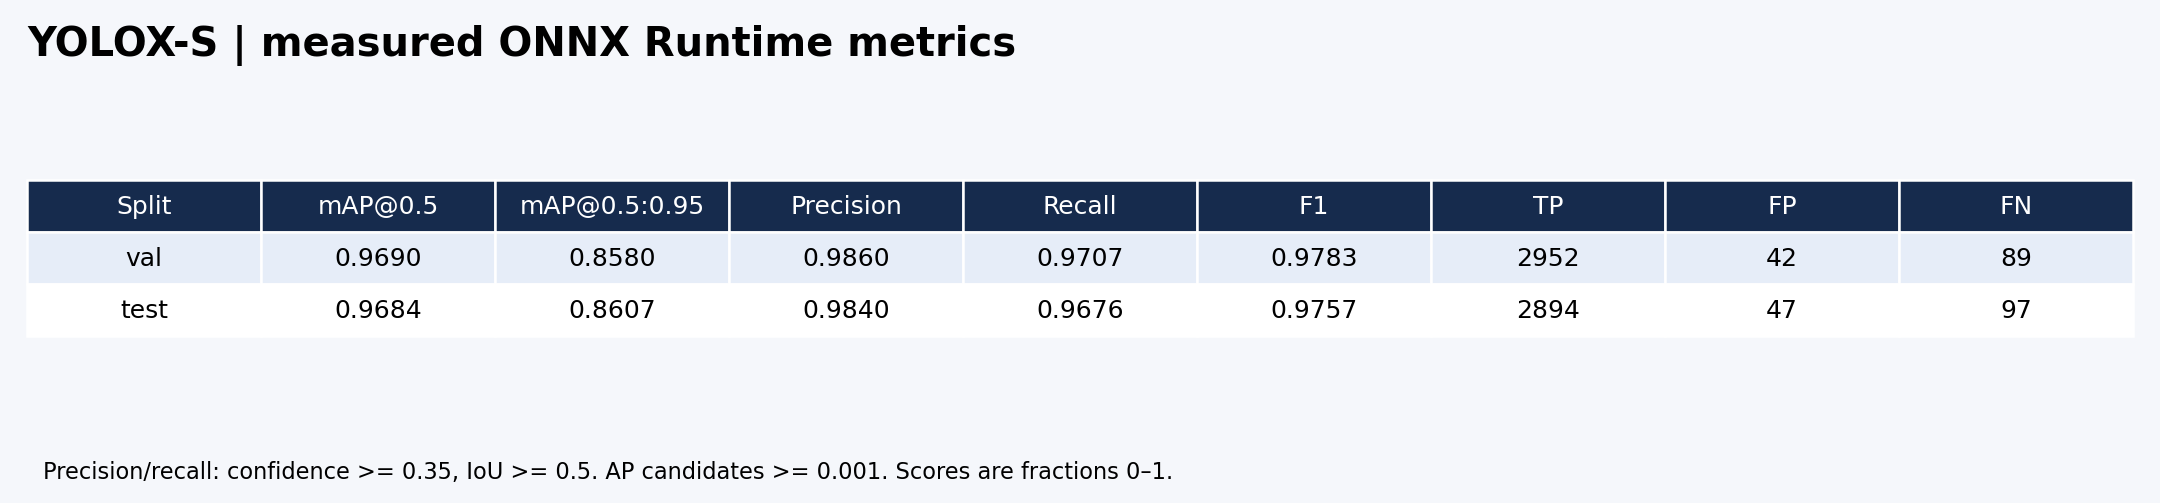

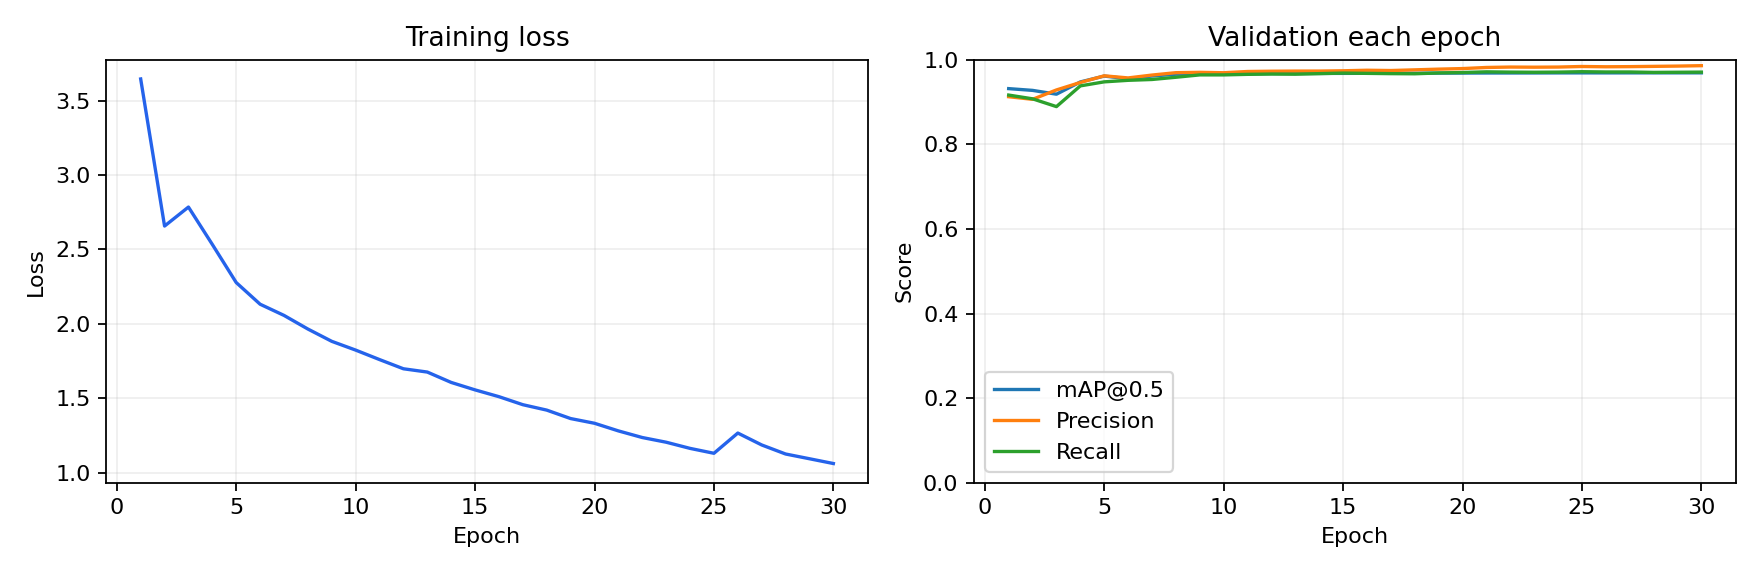

# Observed ONNX errors

Split: test; confidence=0.35; matching IoU=0.5.
Images with measured FP/FN: 101 / 2333.

See errors.csv for every affected image. Red boxes = predictions; green = ground truth.

- missed_signature: 89 images
- false_positive_or_duplicate_or_poor_localization: 38 images

## Visual review prompts (hypotheses, not automatically proven causes)

- Small signatures reduced to very few pixels at 640.
- Faint ink, low contrast, blur or compression.
- Stamps, printed names, handwriting or form lines mistaken for signatures.
- Rotated pages, dense forms, overlapping signatures or unfamiliar templates.

Confirm these causes by inspecting examples; do not label them measured failure modes without evidence.


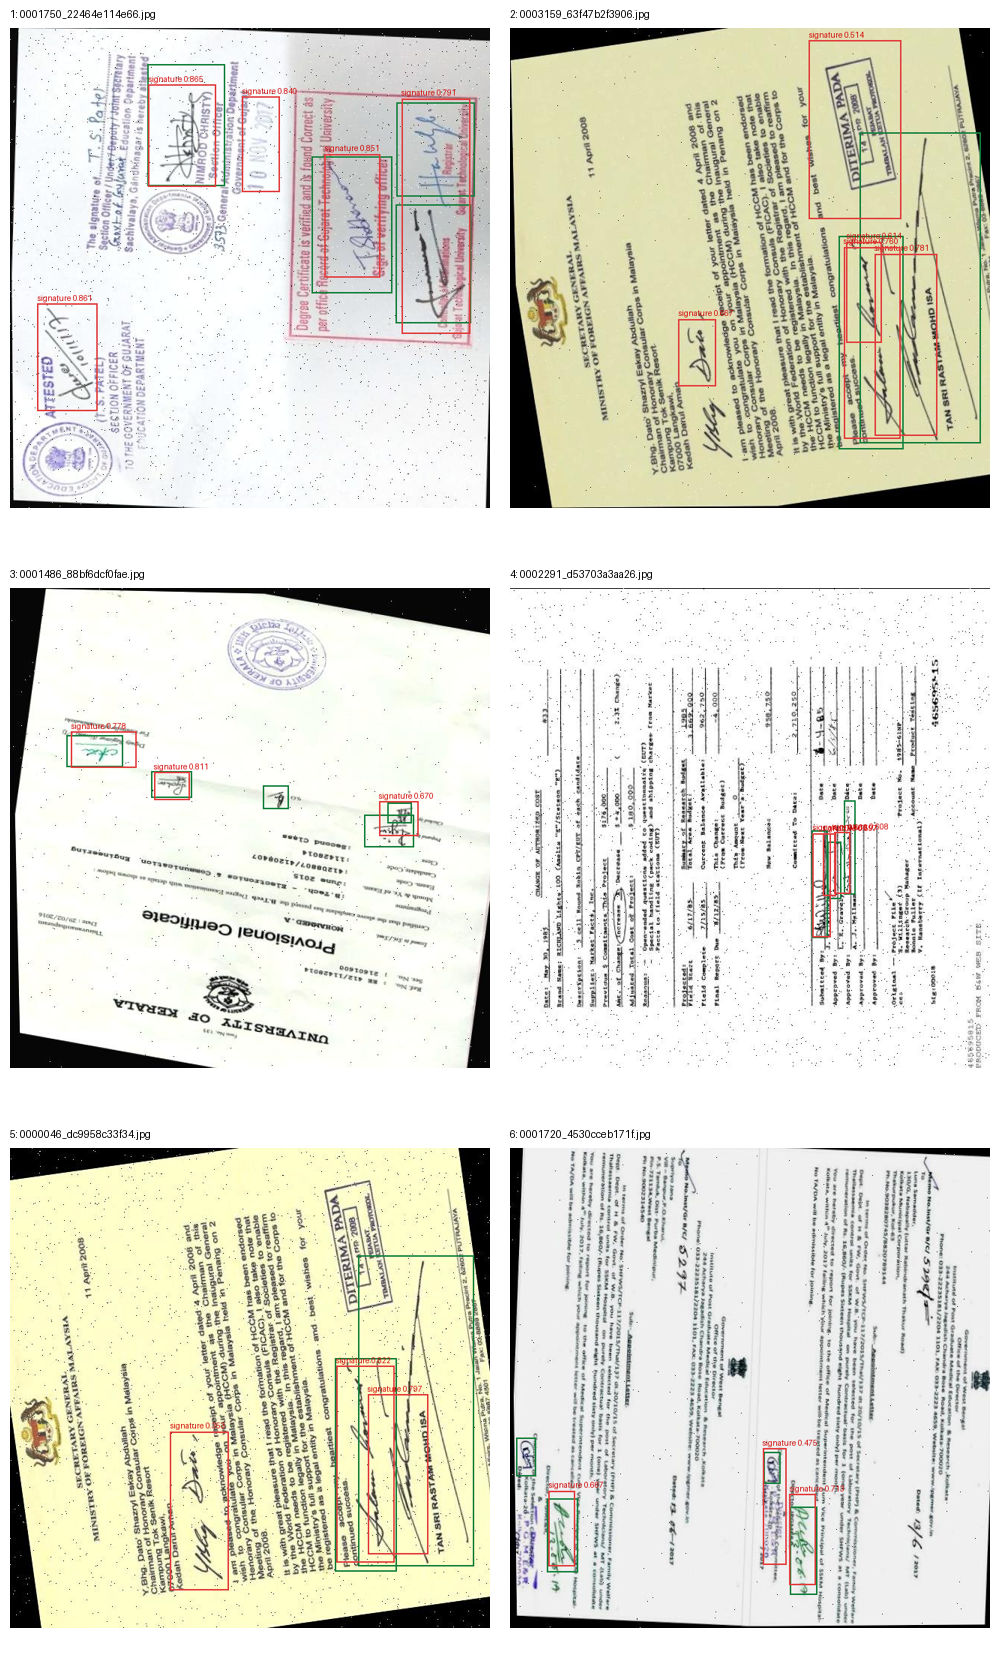

In [8]:
run_stage('evaluate')
display(pd.read_csv(OUT/'reports'/'metrics_table.csv'))
display(DisplayImage(filename=str(OUT/'reports'/'metrics_table.png')))
if (OUT/'reports'/'learning_curves.png').exists():
    display(DisplayImage(filename=str(OUT/'reports'/'learning_curves.png')))
display(Markdown((OUT/'reports'/'ERRORS.md').read_text()))
if (OUT/'reports'/'error_examples.png').exists():
    display(DisplayImage(filename=str(OUT/'reports'/'error_examples.png')))


## 11 · Actual model unit tests: signature + unsigned document

The positive image is selected deterministically from the test split: require an
overlapping bbox at IoU≥0.5 and a valid original-resolution PNG crop.
The unsigned image must return **`[]`**. A real annotated negative is preferred;
otherwise your `NEGATIVE_IMAGE` or the included synthetic unsigned form is used,
with its source stated in the results. No special-case logic forces negatives empty.

If either test fails, inspect saved evidence. Do not declare Done, raise confidence
based on the test set, or hide false positives. Add reviewed training negatives and
tune using validation before a new evaluation.

Negative source: synthetic_printed_unsigned_document
Unsigned result: []


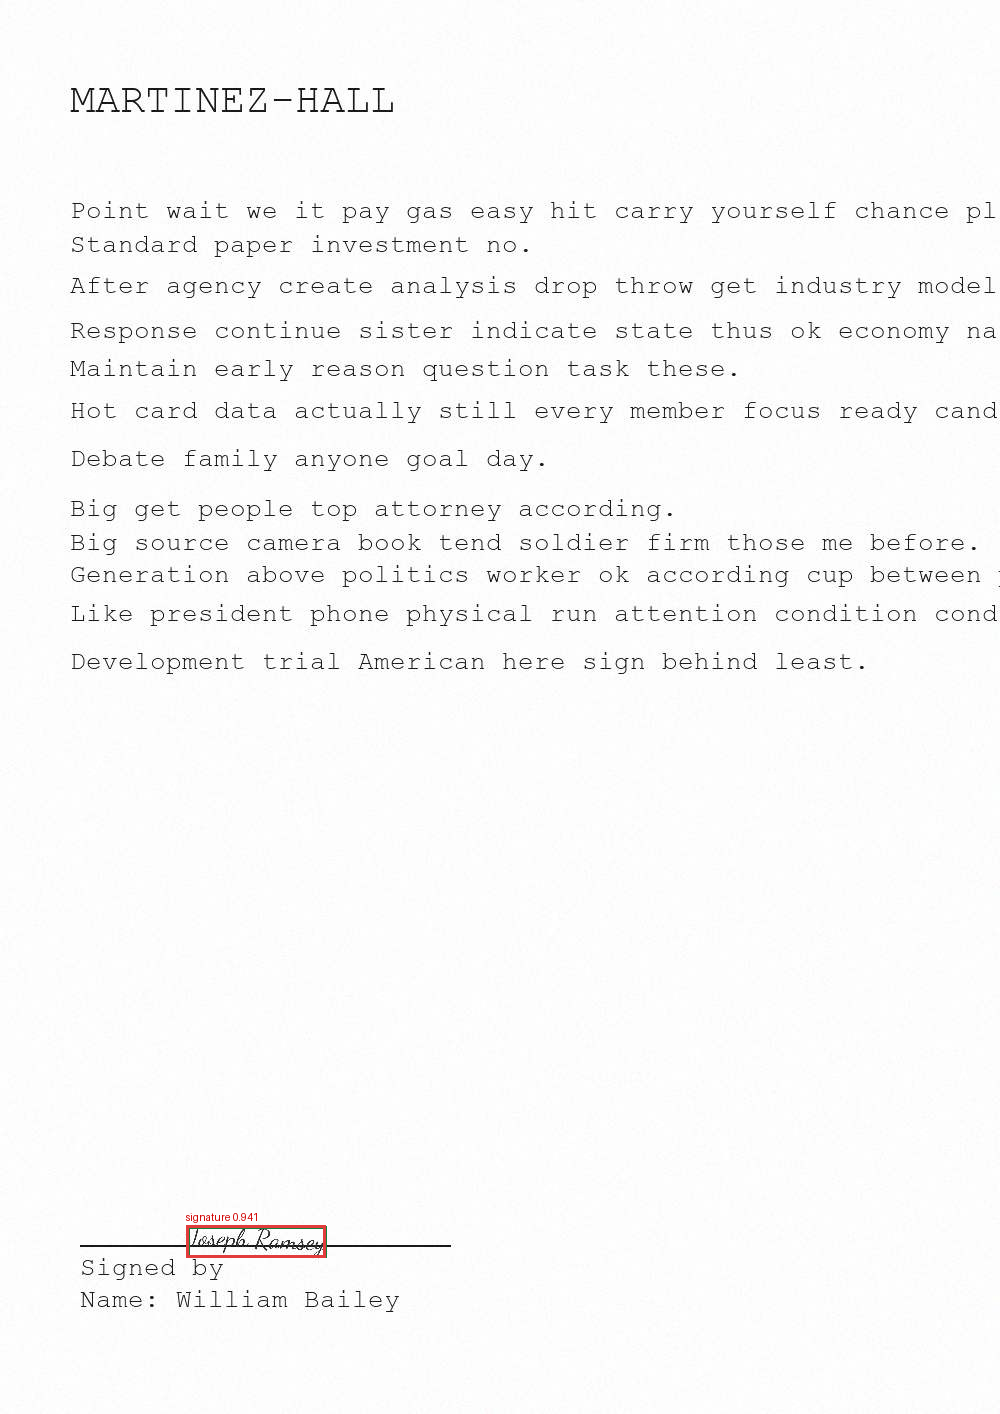

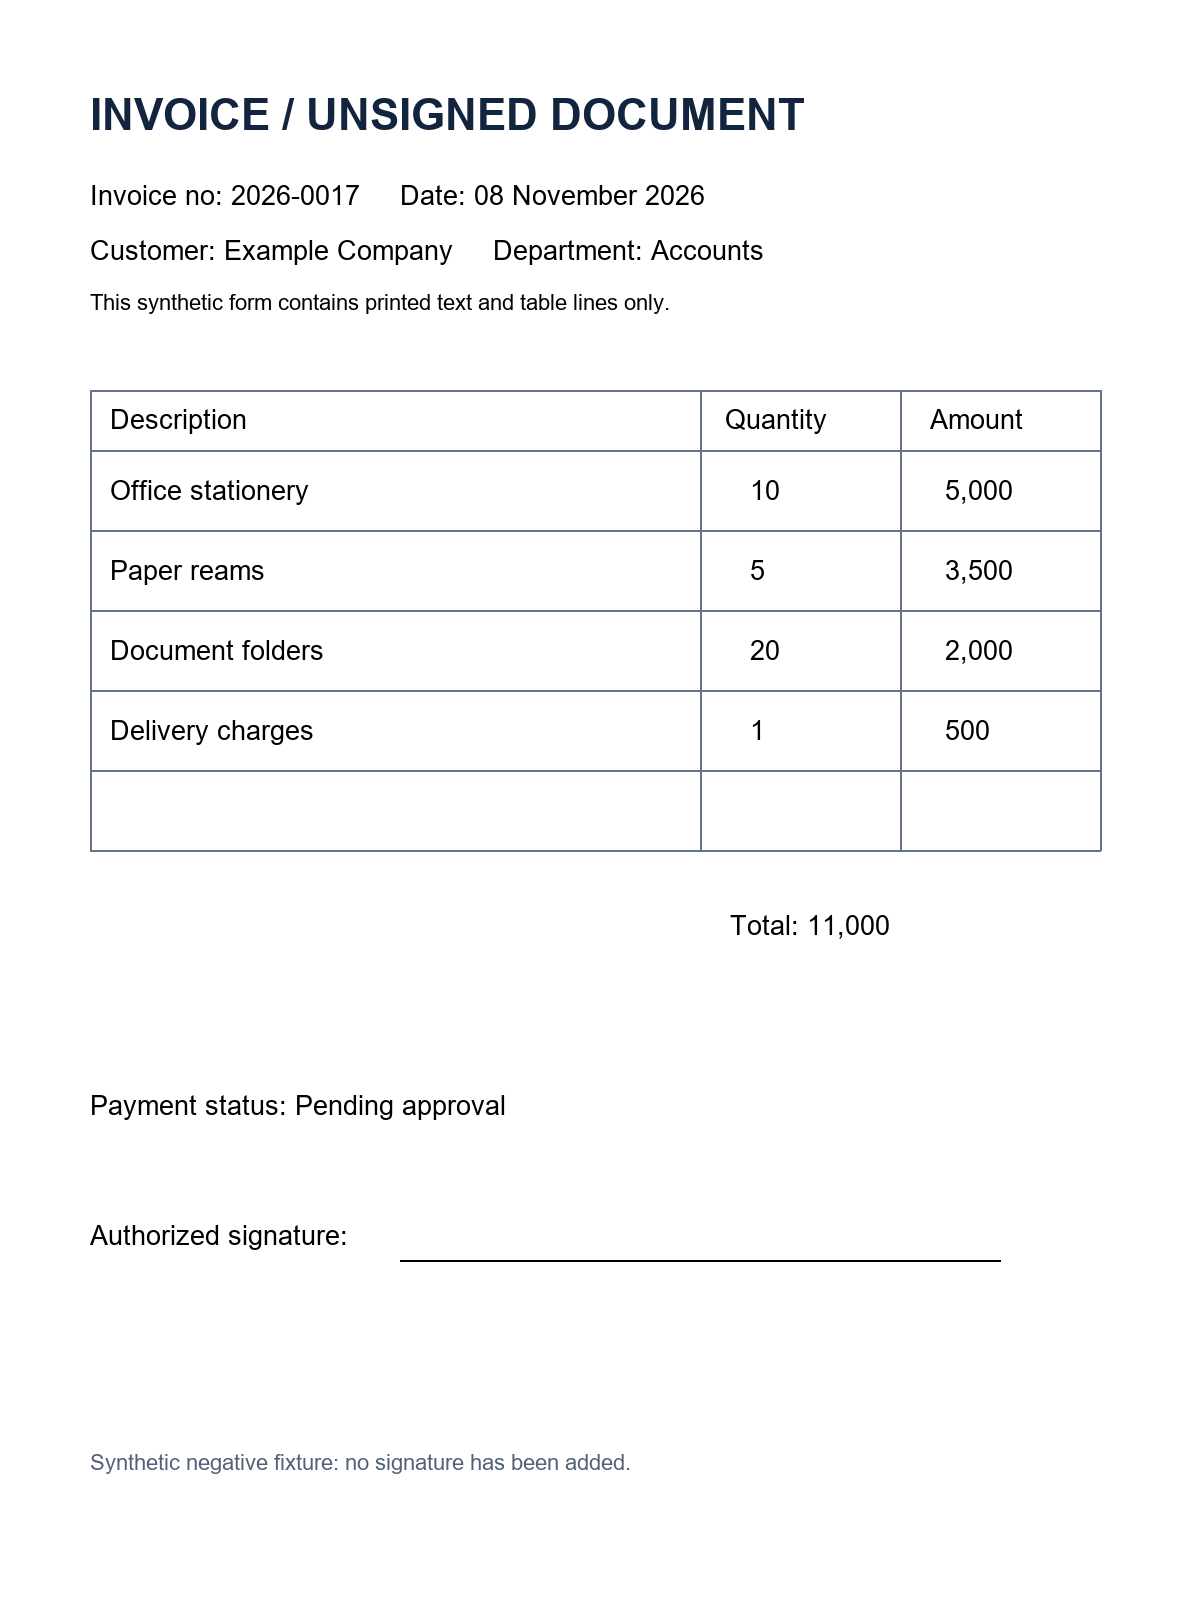

bbox: [186, 1225, 325, 1257] | score: 0.9408525228500366 | crop: /content/signature_day2/outputs/signature_day2_fresh30_b16_20261108/acceptance/crops/32d16a7f3abf46ebb91fb1331447d8b1/signature_000.png


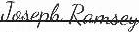

In [9]:
test_process = subprocess.run([PY, str(PROJECT/'pipeline.py'), 'test', '--config', str(CONFIG_PATH)],
                              cwd=PROJECT, env=os.environ.copy())
TESTS = json.loads((OUT/'acceptance'/'acceptance_tests.json').read_text())
print('Negative source:', TESTS['negative']['source_type'])
print('Unsigned result:', TESTS['negative']['actual'])
display(DisplayImage(filename=str(OUT/'acceptance'/'positive_bbox.png')))
display(DisplayImage(filename=str(OUT/'acceptance'/'negative_bbox.png')))
for row in TESTS['positive']['detections'][:4]:
    print('bbox:', row['bbox'], '| score:', row['score'], '| crop:', row['crop_path'])
    display(DisplayImage(filename=row['crop_path']))
assert test_process.returncode == 0 and TESTS['passed'], 'Acceptance failed; evidence is in acceptance/ and reports/.'


## 12 · Try your own image: bounding box + crop

Upload a raster document. This calls the same public function Farhan will import,
using the existing ONNX session for inference. PDF pages should be rendered upstream.
This cell is optional and does not replace held-out evaluation.

In [10]:
TRY_OWN_IMAGE = False
if TRY_OWN_IMAGE:
    from google.colab import files
    uploaded = files.upload()
    for filename, content in uploaded.items():
        safe_name = Path(filename).name
        user_image = OUT/'demo'/safe_name
        user_image.parent.mkdir(parents=True, exist_ok=True)
        user_image.write_bytes(content)
        demo_code = """
import json,sys
from pathlib import Path
from detect import configure,detect
from reports import annotated_image
image=Path(sys.argv[1]); artifact=Path(sys.argv[2]); output=Path(sys.argv[3])
configure(artifact/'signature_yolox_s.onnx',output_dir=output/'crops')
rows=detect(image.read_bytes())
(output/'result.json').write_text(json.dumps(rows,indent=2))
annotated_image(image,rows).save(output/'bbox.png')
print(json.dumps(rows,indent=2))
"""
        subprocess.run([PY,'-c',demo_code,str(user_image),str(OUT/'artifact'),str(OUT/'demo')],
                       cwd=PROJECT, env=os.environ.copy(), check=True)
        display(DisplayImage(filename=str(OUT/'demo'/'bbox.png')))
        for detection in json.loads((OUT/'demo'/'result.json').read_text()):
            display(DisplayImage(filename=detection['crop_path']))


## 13 · Upload the tested model to R2 or HF Hub

R2 upload is enabled by default with the four R2 secrets. You can also set a writable `HF_MODEL_REPO`
with `HF_TOKEN`. Only model/metadata/code/metric deliverables are uploaded.
R2 objects stay private. A new HF model repository is private; existing visibility
is preserved. The upload receipt records the actual resulting objects/commit.

Without configured credentials this step stays pending. Other cells still produce
the ONNX model, Farhan handoff and evaluation evidence locally and in Drive.

In [11]:
if CONFIG.get('enable_r2') or CONFIG.get('hf_model_repo'):
    run_stage('publish')
    RECEIPT = json.loads((OUT/'reports'/'upload_receipt.json').read_text())
    print('Upload completed. Destinations:', list(RECEIPT['destinations']))
    if 'huggingface' in RECEIPT['destinations']:
        print(RECEIPT['destinations']['huggingface']['commit_url'])
else:
    print('MODEL UPLOAD PENDING: configure ENABLE_R2 or HF_MODEL_REPO in Cell 2, then rerun Cell 2 and this cell.')


Upload completed. Destinations: ['r2']


## 14 · Completion table and downloads

`Done` means: full target epochs finished, ONNX parity passed, metrics saved,
positive crop + unsigned empty-list tests passed, and R2/HF upload recorded.
If a row is false, its deliverable remains pending. These are actual run files.

Drive keeps per-epoch checkpoints and final deliverables under your backup Run ID.
Send Farhan `farhan_handoff.zip`; send your team `day2_evidence.zip` for the table,
tests and observed error list. Crop paths inside JSON refer to the original worker;
the evidence zip includes the crop image files themselves.

In [12]:
def read_if(path):
    return json.loads(path.read_text()) if path.exists() else {}
progress = read_if(OUT/'reports'/'progress.json')
parity = read_if(OUT/'artifact'/'onnx_parity.json')
acceptance = read_if(OUT/'acceptance'/'acceptance_tests.json')
metadata = read_if(OUT/'artifact'/'metadata.json')
receipt = read_if(OUT/'reports'/'upload_receipt.json')
checks = {
    'Full cleaned-data training': bool(progress.get('epoch',0) >= CONFIG['epochs'] and metadata.get('trained_on_selected_snapshot_verified')),
    'ONNX raw + detection parity': bool(parity.get('passed')),
    'Measured mAP / precision / recall table': (OUT/'reports'/'metrics_table.csv').exists(),
    'Positive bbox + crop and unsigned []': bool(acceptance.get('passed')),
    'Observed error list': (OUT/'reports'/'errors.csv').exists(),
    'Model uploaded to R2 or HF': bool(receipt.get('destinations')),
}
display(pd.DataFrame([{'Requirement':k,'Passed':v} for k,v in checks.items()]))
print('DONE' if all(checks.values()) else 'PENDING: inspect false rows above')
DOWNLOAD_RESULTS = True
if DOWNLOAD_RESULTS:
    from google.colab import files
    for path in (OUT/'artifact'/'farhan_handoff.zip', OUT/'day2_evidence.zip'):
        if path.exists():
            files.download(str(path))


,Requirement,Passed
0,Full cleaned-data training,True
1,ONNX raw + detection parity,True
2,Measured mAP / precision / recall table,True
3,Positive bbox + crop and unsigned [],True
4,Observed error list,True
5,Model uploaded to R2 or HF,True


DONE


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Disconnect recovery / common fixes

| Situation | Action |
|---|---|
| Runtime reset | Same RUN_ID, EPOCHS, batch and thresholds; RESUME=True; rerun setup/prepare/train |
| Lost old GPU checkpoint best only | Use INITIAL_CHECKPOINT in a new run; optimizer resume requires Day 2 full state |
| CUDA quota exhausted | DEVICE='cpu', same run and backups; full training is much slower |
| Out of memory at batch 16 | Start a new Run ID with BATCH_SIZE=8; changing batch size changes the saved schedule |
| Dataset schema/overlap error | Inspect the reported source file; fix the cleaned snapshot and start a new run |
| HF access error | Enable HF_TOKEN access; no substitute dataset is used |
| R2 checkpoint upload fails | Local/Drive checkpoint remains; fix R2 credentials/connection and resume |
| Unsigned test has false positives | Inspect errors; add reviewed negatives and tune on validation before retest |
| Export parity fails | Keep graph/preprocessing/decode consistent; inspect artifact/onnx_parity.json |

Checkpoint recovery is at completed epoch boundaries; it cannot restore work from
the unfinished epoch. Detection does not verify signature authenticity.

Source references: [official exporter](https://github.com/Megvii-BaseDetection/YOLOX/blob/419778480ab6ec0590e5d3831b3afb3b46ab2aa3/tools/export_onnx.py),
[official preprocessing](https://github.com/Megvii-BaseDetection/YOLOX/blob/419778480ab6ec0590e5d3831b3afb3b46ab2aa3/yolox/data/data_augment.py),
[ONNX Runtime](https://onnxruntime.ai/docs/api/python/api_summary.html).